# Raw voltage explorer

Load BrainFlow CSVs for **one subject**, clean them, then look at leftover voltage on the channel you pick.

Run the cells **in order**. Use the **attn_analysis** kernel (`attn` cannot rasterize PNG).

1. **Select** — a dialog lists subject folders (and how many files each has). Pick a folder or make a new one, then tag sets the usual way: choose set 1 / 2 / 3 / 4, Command-click those CSVs, then the next set, then **Done picking**. Files are copied into that subject's folder.
2. **Load** — `LOAD_SET` chooses which of those tagged sets to QC now (so you do not load every set at once).
3. **Pack** — `WORK_ON` is one file or `"pooled"`. `VIEW_CH` is the 10–20 label. Plots go to `outputs/raw_signals/<subject>/set4/P3/`.
4. **Cleanup ladder** — high-pass, notch, low-pass, CAR, then ICA if you fill `ICA_DROP`.
5. **Meeting plots** — G1 is the marker table, G2 is the clip plus leftover peak/trough knobs, then the rough pattern. Then section 8: store each clip, show them all, stack, mean leftover, compare to baseline, close the gap.
6. **Scalp maps** — relative band power at each electrode (optional).
7. **ECG / heart rate** — Cyton **N1P / Ch0** with SRB2 off (ECG snaps). R-peaks, HR, HRV. Separate from the EEG leftover path; Ch0 is not range-checked as EEG here.


In [130]:
%matplotlib inline
%config InlineBackend.figure_format = "png"


In [ ]:
from pathlib import Path
import os, sys, re, json, shutil, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.signal import (
    stft, istft, butter, sosfiltfilt, iirnotch, tf2sos, welch, find_peaks,
)
from scipy.interpolate import griddata
from scipy.stats import kurtosis
from sklearn.decomposition import FastICA

cwd = Path.cwd().resolve()
if (cwd / "analysis").is_dir() and (cwd / "experiments").is_dir():
    REPO_ROOT = cwd
elif cwd.name == "analysis":
    REPO_ROOT = cwd.parent
else:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT / "analysis"))
print("REPO_ROOT:", REPO_ROOT)
print("kernel:", sys.executable)
if "/envs/attn/" in sys.executable.replace("\\", "/") and "attn_analysis" not in sys.executable:
    print("Switch kernel to attn_analysis, then re-run from the top.")

import openbci_qc as oqc
oqc = importlib.reload(oqc)

FS = oqc.FS
N_CH = oqc.N_CH
BP = oqc.BP
NOTCH_HZ = oqc.NOTCH_HZ
SETTLE_SEC = oqc.SETTLE_SEC
WIN_SEC = oqc.WIN_SEC
CHANNEL_LABELS = oqc.CHANNEL_LABELS
RAIL_UV = oqc.RAIL_UV
RAIL_FRAC = oqc.RAIL_FRAC
LABEL_TO_CH = {lab: c for c, lab in CHANNEL_LABELS.items()}
SET_DIR = {1: "baseline", 2: "set2", 3: "set3", 4: "set4"}

# Frontal / central / parietal — the regions this study is using.
# Fp1, Fp2, O1, O2 stay on the full-session plot in grey.
PRIORITY_CHANNELS = [c for c, lab in CHANNEL_LABELS.items()
                     if lab not in ("O1", "O2", "Fp1", "Fp2")]
DEPRIORITIZED = [c for c in range(N_CH) if c not in PRIORITY_CHANNELS]
MARKER_STYLE = {
    1: ("C1", "send (1)"),
    11: ("C2", "engage (11)"),
    12: ("C3", "release (12)"),
}
OUT_ROOT = REPO_ROOT / "analysis" / "outputs" / "raw_signals"
OUT_ROOT.mkdir(parents=True, exist_ok=True)


def show_fig(fig, name, out_dir):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    path = out_dir / Path(name).with_suffix(".png").name
    try:
        fig.savefig(str(path), dpi=140, bbox_inches="tight")
        plt.close(fig)
        display(Image(filename=str(path)))
        print("saved", path)
    except Exception as e:
        plt.close(fig)
        print(f"skipped figure {name}: {e}")
        print("Switch kernel to attn_analysis (Kernel → Change Kernel) for plots.")


def set_dirname(set_id):
    return SET_DIR.get(int(set_id), f"set{int(set_id)}")


def sitting_slug(rec):
    """Short folder name for one CSV (not the pooled hour)."""
    raw = str(rec.get("id") or Path(rec.get("path", "sitting")).stem)
    raw = raw.replace("BrainFlow-RAW_", "").replace(" ", "_")
    keep = "".join(ch if ch.isalnum() or ch in "-_." else "_" for ch in raw)
    return keep[:80] or "sitting"


def subject_slug(name=None):
    raw = str(name if name is not None else globals().get("SUBJECT", "unknown")).strip()
    keep = "".join(ch if ch.isalnum() or ch in "-_." else "_" for ch in raw)
    return keep[:40] or "unknown"


def subject_root(name=None):
    d = OUT_ROOT / subject_slug(name)
    d.mkdir(parents=True, exist_ok=True)
    return d


def recordings_dir(name=None, set_id=None):
    """Where this subject's selected CSVs live: <subject>/set4/recordings/"""
    d = subject_root(name)
    if set_id is not None:
        d = d / set_dirname(set_id) / "recordings"
    d.mkdir(parents=True, exist_ok=True)
    return d


def csv_identity(path):
    """Same recording even if the copy was renamed with the session folder prefix."""
    name = Path(path).name
    i = name.find("BrainFlow-RAW_")
    return name[i:] if i >= 0 else name


def store_session_csv(spec, name=None):
    """Copy the tagged CSV into the subject folder. Load uses the copy."""
    src = Path(spec["path"]).resolve()
    dest_dir = recordings_dir(name, spec.get("set"))
    dest = dest_dir / csv_identity(src)
    spec = dict(spec)
    if dest.exists() and dest.resolve() == src and dest.stat().st_size > 0:
        spec["path"] = dest
        return spec
    if dest.exists() and dest.stat().st_size == src.stat().st_size and dest.stat().st_size > 0:
        print(f"  already stored  {dest.name}")
    else:
        shutil.copy2(src, dest)
        print(f"  copied {src.name}  →  {dest}")
    spec["source_path"] = str(src)
    spec["path"] = dest
    return spec


def _spec_to_json(s):
    return {
        "id": s.get("id"),
        "condition": s.get("condition"),
        "set": int(s.get("set")),
        "electrodes": s.get("electrodes"),
        "task": s.get("task"),
        "enabled": bool(s.get("enabled", True)),
        "path": str(Path(s["path"]).resolve()),
        "source_path": s.get("source_path"),
    }


def _spec_from_json(d):
    p = Path(d["path"])
    return {
        "id": d.get("id") or oqc.id_from_path(p),
        "condition": d.get("condition"),
        "set": int(d["set"]),
        "electrodes": d.get("electrodes", "Cyton+Daisy dry"),
        "task": d.get("task"),
        "enabled": bool(d.get("enabled", True)),
        "path": p,
    }


def load_subject_catalog(name=None):
    """Tagged CSV lists for one subject, keyed by set number. EEG is not stored."""
    path = subject_root(name) / "tagged_files.json"
    sets = {}
    if path.exists():
        blob = json.loads(path.read_text())
        for k, rows in (blob.get("sets") or {}).items():
            sets[int(k)] = [_spec_from_json(r) for r in rows]
    return sets


def save_subject_catalog(sets, name=None):
    path = subject_root(name) / "tagged_files.json"
    blob = {
        "subject": subject_slug(name),
        "sets": {str(int(k)): [_spec_to_json(s) for s in v] for k, v in sorted(sets.items())},
    }
    path.write_text(json.dumps(blob, indent=2))
    return path


def list_subject_catalogs():
    return sorted(p.parent.name for p in OUT_ROOT.glob("*/tagged_files.json"))


_SKIP_SUBJECT_DIRS = set(SET_DIR.values()) | {"montage"}


def iter_subject_folders():
    names = set(list_subject_catalogs())
    if OUT_ROOT.is_dir():
        for p in OUT_ROOT.iterdir():
            if not p.is_dir() or p.name.startswith(".") or p.name in _SKIP_SUBJECT_DIRS:
                continue
            if p.name.startswith("BrainFlow-RAW"):
                continue
            names.add(p.name)
    return sorted(names)


def subject_folder_stats(name):
    """Count unique recordings (skip empty leftover copies)."""
    catalog = load_subject_catalog(name)
    by_set = {}
    for k, rows in catalog.items():
        ids = {csv_identity(r["path"]) for r in rows if Path(r["path"]).exists() and Path(r["path"]).stat().st_size > 0}
        if ids:
            by_set[int(k)] = len(ids)
    root = subject_root(name)
    for sid, dirname in SET_DIR.items():
        recs = root / dirname / "recordings"
        if not recs.is_dir():
            continue
        ids = set()
        for p in recs.glob("*.csv"):
            if p.stat().st_size > 0:
                ids.add(csv_identity(p))
        if ids:
            by_set[int(sid)] = len(ids)
    return by_set


def catalog_to_files(catalog):
    out = []
    for sid in sorted(catalog):
        out.extend(catalog[sid])
    return out


def files_to_catalog(files):
    cat = {}
    for s in files:
        cat.setdefault(int(s["set"]), []).append(s)
    return cat


def print_subject_library():
    names = iter_subject_folders()
    print("Subject folders:")
    if not names:
        print("  (none yet — you will create one next)")
        return names
    for name in names:
        by_set = subject_folder_stats(name)
        n = sum(by_set.values())
        bits = ", ".join(f"set {sid}: {by_set[sid]}" for sid in sorted(by_set)) or "empty"
        print(f"  {name:16}  {n} file(s)   {bits}")
    return names


def choose_subject_folder():
    """Dialog: pick an existing subject folder or create a new one."""
    names = print_subject_library()
    NEW = "New subject…"
    labels = []
    for name in names:
        by_set = subject_folder_stats(name)
        n = sum(by_set.values())
        bits = ", ".join(f"set {sid}: {by_set[sid]}" for sid in sorted(by_set))
        extra = f" — {bits}" if bits else " — empty"
        labels.append(f"{name}  ({n} file(s){extra})")
    labels.append(NEW)
    default = labels[0]
    choice = oqc._ask_list(
        "Which subject folder should these files be stored in?",
        labels,
        default=default,
    )
    if not choice or choice == NEW:
        ask = getattr(oqc, "ask_text", None)
        raw = ask("New subject folder name:", default="") if callable(ask) else input("New subject folder name: ").strip()
        slug = subject_slug(raw)
        if slug in ("unknown", ""):
            raise RuntimeError("No subject name entered. Re-run and type a folder name.")
    else:
        slug = subject_slug(names[labels.index(choice)])
    home = subject_root(slug)
    print(f"\nUsing subject folder: {home}")
    return slug


def out_dir_for(rec, ch=None, sitting=None):
    """One folder per subject × set × channel. A single-file sitting gets its own subfolder.

    Pooled:  analysis/outputs/raw_signals/soni/set4/P3/
    One CSV: analysis/outputs/raw_signals/soni/set4/P3/<file-id>/
    """
    ch = rec.get("view_ch") if ch is None else ch
    lab = CHANNEL_LABELS.get(ch, str(ch)) if ch is not None else "montage"
    subj = rec.get("subject") or globals().get("SUBJECT")
    rec["subject"] = subject_slug(subj)
    d = OUT_ROOT / rec["subject"] / set_dirname(rec.get("set") or 1) / lab
    if sitting:
        d = d / str(sitting)
    d.mkdir(parents=True, exist_ok=True)
    rec["out_dir"] = d
    rec["view_ch"] = ch
    rec["sitting"] = sitting
    return d


def session_time_min(rec):
    eeg, unix, fs = rec["eeg"], rec["unix"], rec["fs"]
    if unix is None or not np.isfinite(unix).any() or float(np.nanmin(unix)) < 1e9:
        return (np.arange(len(eeg)) / fs) / 60.0
    return (unix - np.nanmin(unix)) / 60.0


def decimate_for_plot(x, t, max_points=6000):
    # Thin the overview plot only. Every plotted point is still a real sample.
    n = len(x)
    if n <= max_points:
        return x, t
    step = int(np.ceil(n / max_points))
    return x[::step], t[::step]


def marker_onsets(mark):
    if mark is None:
        return []
    m = np.asarray(mark, dtype=float)
    m = np.where(np.isfinite(m), m, 0.0)
    prev = np.concatenate([[0.0], m[:-1]])
    events = []
    for i in np.where(m != prev)[0]:
        v = int(round(m[i]))
        if v in MARKER_STYLE:
            events.append((int(i), v))
    return events


def marker_times_s(rec):
    """(time_seconds, code) for each 1 / 11 / 12 onset."""
    t_min = session_time_min(rec)
    out = []
    for i, v in marker_onsets(rec.get("mark")):
        t_s = float(t_min[min(i, len(t_min) - 1)] * 60.0)
        out.append((t_s, v))
    return out


def draw_markers(ax, rec, t0=None, t1=None, x_unit="s", legend=False):
    """Draw send (1), engage (11), release (12) as vertical lines.

    t0/t1 and x_unit match the axis: seconds ('s') or minutes ('min').
    """
    scale = 1.0 if x_unit == "s" else (1.0 / 60.0)
    shown = []
    for t_s, v in marker_times_s(rec):
        x = t_s * scale
        if t0 is not None and x < t0:
            continue
        if t1 is not None and x > t1:
            continue
        ax.axvline(x, color=MARKER_STYLE[v][0], lw=0.85, alpha=0.75, zorder=3)
        if v not in shown:
            shown.append(v)
    if legend and shown:
        handles = [
            plt.Line2D([0], [0], color=MARKER_STYLE[v][0], lw=1.3, label=MARKER_STYLE[v][1])
            for v in shown
        ]
        ax.legend(handles=handles, loc="upper right", fontsize=7, frameon=False, ncol=min(3, len(handles)))
    return shown


def session_t_s(rec):
    return session_time_min(rec) * 60.0


def nan_at_gaps(t, x, max_dt=None):
    """Put NaN in y after a time jump so matplotlib does not draw a line through a dropout."""
    max_dt = float(oqc.GAP_SEC) if max_dt is None else float(max_dt)
    t = np.asarray(t, dtype=float)
    y = np.asarray(x, dtype=float).copy()
    if t.size < 2:
        return t, y
    d = np.diff(t)
    jump = (~np.isfinite(d)) | (d > max_dt)
    y[1:][jump] = np.nan
    return t, y


def rec_window(x, t0, t1, rec=None):
    """Samples in [t0, t1), including NaNs (packet loss / day join stay as holes)."""
    rec = rec or globals()["rec"]
    t = session_t_s(rec)
    m = (t >= t0) & (t < t1)
    return t[m], np.asarray(x)[m]


def window_ok(x, t0, t1, rec=None, need_frac=0.8, max_gap=0.5):
    """False if the clip is empty, mostly NaN, or has a reconnect hole inside it."""
    rec = rec or globals().get("rec")
    t, y = rec_window(x, t0, t1, rec=rec)
    if y.size < 10:
        return False
    if float(np.isfinite(y).mean()) < need_frac:
        return False
    tt = t[np.isfinite(y)]
    if tt.size >= 2 and float(np.max(np.diff(tt))) > max_gap:
        return False
    return True


def first_clean_start(rec):
    """Session-seconds of the first sample that a QC segment actually covers (not a dropout)."""
    t = session_t_s(rec)
    n = len(t)
    covered = np.zeros(n, dtype=bool)
    for s in rec.get("segs") or []:
        idx = np.asarray(s["idx"], dtype=int)
        idx = idx[(idx >= 0) & (idx < n)]
        covered[idx] = True
    ok = covered & np.isfinite(rec["eeg"]).all(axis=1)
    if not ok.any():
        return float(t[0]) if n else SETTLE_SEC
    return float(t[int(np.argmax(ok))])


def slice_seg(rec, start_s, dur_s):
    """Raw + QC-filtered voltages on the rec timeline for [start_s, start_s+dur_s).

    Packed hours start at t=0 (original 45 s settle is already gone). Do not
    subtract SETTLE_SEC or index into segs[0] as if it were the whole file.
    """
    t = session_t_s(rec)
    m = (t >= float(start_s)) & (t < float(start_s) + float(dur_s))
    if int(m.sum()) < 10:
        return None, None, None
    raw = np.asarray(rec["eeg"][m], dtype=float)
    if not np.isfinite(raw).any():
        return None, None, None
    filt_full = np.full(rec["eeg"].shape, np.nan, dtype=float)
    n = len(rec["eeg"])
    for s in rec.get("segs") or []:
        idx = np.asarray(s["idx"], dtype=int)
        y = np.asarray(s["filt"], dtype=float)
        k = min(len(idx), len(y))
        if k == 0:
            continue
        idx, y = idx[:k], y[:k]
        ok = (idx >= 0) & (idx < n)
        if ok.any():
            filt_full[idx[ok]] = y[ok]
    return raw, filt_full[m], np.asarray(t[m], dtype=float)


def snap_zoom_start(rec, start_s, dur_s):
    """If that window has no samples, jump to the first stretch that does."""
    raw, _, _ = slice_seg(rec, start_s, dur_s)
    if raw is not None:
        return float(start_s), False
    alt = first_clean_start(rec)
    raw, _, _ = slice_seg(rec, alt, dur_s)
    if raw is not None:
        return float(alt), True
    return float(start_s), False


def resolve_channel(spec):
    """VIEW_CH can be a 10-20 label ('C3') or a 0-based index."""
    if isinstance(spec, (int, np.integer)):
        ch = int(spec)
        if ch not in CHANNEL_LABELS:
            raise ValueError(f"channel index {ch} is not 0–{N_CH - 1}")
        return ch
    key = str(spec).strip()
    if key.isdigit():
        return resolve_channel(int(key))
    by_lower = {lab.lower(): c for lab, c in LABEL_TO_CH.items()}
    if key.lower() not in by_lower:
        raise ValueError(f"Unknown channel {spec!r}. Use one of: {', '.join(CHANNEL_LABELS[c] for c in range(N_CH))}")
    return by_lower[key.lower()]


def calendar_day(rec):
    m = re.search(r"(\d{4}-\d{2}-\d{2})", Path(rec["path"]).name)
    from_name = m.group(1) if m else None
    u = rec.get("unix")
    if u is not None and np.isfinite(u).any():
        ts = float(np.nanmin(u))
        # unix 0 / 1970 is a missing timestamp, not a real session day
        if ts > 1e9:
            return datetime.fromtimestamp(ts).date().isoformat()
    return from_name or "unknown"


def _cat_field(recs, key, fill=np.nan):
    parts = []
    for r in recs:
        v = r.get(key)
        n = len(r["eeg"])
        if v is None:
            parts.append(np.full(n, fill))
        else:
            parts.append(np.asarray(v))
    return np.concatenate(parts)


def concat_recs(recs):
    """Glue recordings in time order. Unix gaps stay; QC will split them into segments."""
    recs = sorted(
        recs,
        key=lambda r: float(np.nanmin(r["unix"])) if r.get("unix") is not None and np.isfinite(r["unix"]).any() else 0.0,
    )
    eeg = np.vstack([r["eeg"] for r in recs])
    fs = float(recs[0]["fs"])
    unix = _cat_field(recs, "unix")
    mark = _cat_field(recs, "mark", fill=0.0)
    ts = _cat_field(recs, "ts")
    accel = None
    if all(r.get("accel") is not None for r in recs):
        accel = np.concatenate([np.asarray(r["accel"]) for r in recs])
    segs = oqc.preprocess(eeg, fs, unix, mark, accel)
    win = oqc.window_qc(segs, fs)
    qc = oqc.channel_qc(segs, win, fs)
    ids = [r.get("id") or Path(r["path"]).stem for r in recs]
    return {
        "path": recs[0]["path"],
        "eeg": eeg, "ts": ts, "fs": fs, "df": recs[0].get("df"),
        "mark": mark, "accel": accel, "unix": unix,
        "segs": segs, "win": win, "qc": qc,
        "dur_min": len(eeg) / fs / 60.0,
        "n_samples": len(eeg),
        "id": ids[0] if len(ids) == 1 else f"pooled_{len(ids)}files_{ids[0]}",
        "condition": recs[0].get("condition"),
        "set": recs[0].get("set"),
        "task": recs[0].get("task"),
        "electrodes": recs[0].get("electrodes"),
        "source_files": [str(r["path"]) for r in recs],
        "source_ids": ids,
    }


def pool_by_day(set_recs):
    groups = {}
    for r in set_recs:
        groups.setdefault(calendar_day(r), []).append(r)
    days = []
    for day, rs in sorted(groups.items()):
        m = concat_recs(rs)
        m["day"] = day
        m["id"] = f"pooled_set{m['set']}_{day}" + ("" if len(rs) == 1 else f"_{len(rs)}files")
        days.append(m)
    return days


def n_complete_trials_in(rec, t0, t1):
    ev = marker_times_s(rec)
    ones = [t for t, v in ev if v == 1 and t0 <= t <= t1]
    elevens = [t for t, v in ev if v == 11]
    twelves = [t for t, v in ev if v == 12]
    n, used11, used12 = 0, set(), set()
    for t_one in ones:
        t11s = [t for t in elevens if t_one < t <= t1 and t not in used11]
        if not t11s:
            continue
        t11 = t11s[0]
        t12s = [t for t in twelves if t11 < t <= t1 and t not in used12]
        if not t12s:
            continue
        n += 1
        used11.add(t11)
        used12.add(t12s[0])
    return n


def hour_windows(rec, target_min, hop_s=30.0):
    """Candidate [t0, t1) in recording seconds. Stays inside one sitting (unix gap > 5 min)."""
    t = session_time_min(rec) * 60.0
    if len(t) == 0:
        return []
    u = rec.get("unix")
    fs = rec["fs"]
    if u is None or not np.isfinite(u).any():
        chunks = [(float(t[0]), float(t[-1]) + 1.0 / fs)]
    else:
        d = np.diff(np.asarray(u, dtype=float))
        cuts = np.where(np.isfinite(d) & (d > 300.0))[0] + 1
        edges = [0, *cuts.tolist(), len(u)]
        chunks = [(float(t[a]), float(t[b - 1]) + 1.0 / fs) for a, b in zip(edges[:-1], edges[1:])]
    target_s = float(target_min) * 60.0
    wins = []
    for a, b in chunks:
        span = b - a
        if span <= target_s * 1.05:
            wins.append((a, b))
            continue
        s = a
        while s + target_s <= b + 1e-6:
            wins.append((s, s + target_s))
            s += hop_s
        tail0 = b - target_s
        if tail0 > a and (not wins or abs(wins[-1][0] - tail0) > 1):
            wins.append((tail0, b))
    seen, out = set(), []
    for w in wins:
        k = (round(w[0], 1), round(w[1], 1))
        if k not in seen:
            seen.add(k)
            out.append(w)
    return out


def score_hour(rec, t0, t1, ch, target_min, penalize_short=True):
    t = session_time_min(rec) * 60.0
    m = (t >= t0) & (t < t1)
    x = rec["eeg"][m, ch]
    fs = rec["fs"]
    if len(x) < fs * 30:
        return -1e9, {"frac_clean": np.nan, "frac_fin": 0, "frac_rail": 1, "n_trials": 0, "dur_min": 0.0}
    rail_thr = RAIL_FRAC * RAIL_UV
    finite = np.isfinite(x)
    frac_fin = float(finite.mean())
    xr = np.abs(x[finite]) if finite.any() else np.array([np.inf])
    frac_rail = float((xr >= rail_thr).mean()) if len(xr) else 1.0
    frac_clean = np.nan
    win = rec.get("win")
    u = rec.get("unix")
    if win is not None and len(win) and "t0" in win.columns and u is not None:
        uu = u[m]
        if np.isfinite(uu).any():
            u0, u1 = float(np.nanmin(uu)), float(np.nanmax(uu))
            wc = win[win.ch == ch]
            ov = wc[(wc["t0"] < u1) & (wc["t1"] > u0)]
            if len(ov):
                frac_clean = float(ov["clean"].mean())
    if not np.isfinite(frac_clean):
        frac_clean = max(0.0, 1.0 - frac_rail)
    n_tr = n_complete_trials_in(rec, t0, t1)
    n_u = int((rec["qc"]["verdict"] == "USABLE").sum()) if rec.get("qc") is not None and len(rec["qc"]) else 0
    dur = float(t1 - t0)
    stats = dict(frac_clean=frac_clean, frac_fin=frac_fin, frac_rail=frac_rail,
                 n_trials=n_tr, n_usable=n_u, dur_min=dur / 60.0)
    score = 2.0 * frac_clean + 1.0 * frac_fin - 2.0 * frac_rail + 0.3 * (n_u / 16.0)
    if int(rec.get("set") or 1) != 1:
        score += 0.5 * min(n_tr, 12) / 12.0
    if penalize_short:
        target_s = float(target_min) * 60.0
        if dur < 0.9 * target_s:
            score *= dur / target_s
    return float(score), stats


def slice_rec_hour(rec, t0, t1):
    """Keep only samples in [t0, t1) recording-seconds. Remap segs onto the slice."""
    fs = rec["fs"]
    t = session_time_min(rec) * 60.0
    idx = np.where((t >= t0) & (t < t1))[0]
    if len(idx) < int(fs * 10):
        raise ValueError(f"hour slice {t0:.0f}–{t1:.0f}s is empty")
    i0, i1 = int(idx[0]), int(idx[-1]) + 1
    out = dict(rec)
    out["eeg"] = rec["eeg"][i0:i1]
    out["n_samples"] = len(out["eeg"])
    out["dur_min"] = out["n_samples"] / fs / 60.0
    for key in ("unix", "ts", "mark", "accel"):
        v = rec.get(key)
        if v is not None:
            out[key] = np.asarray(v)[i0:i1]
    segs = []
    for s in rec.get("segs") or []:
        si = np.asarray(s["idx"])
        keep = (si >= i0) & (si < i1)
        if keep.sum() < int(WIN_SEC * fs):
            continue
        ns = dict(s)
        ns["idx"] = si[keep] - i0
        ns["raw"] = np.asarray(s["raw"])[keep]
        ns["filt"] = np.asarray(s["filt"])[keep]
        if s.get("t_unix") is not None:
            ns["t_unix"] = np.asarray(s["t_unix"])[keep]
        if s.get("mark") is not None:
            ns["mark"] = np.asarray(s["mark"])[keep]
        if s.get("accel") is not None:
            ns["accel"] = np.asarray(s["accel"])[keep]
        segs.append(ns)
    out["segs"] = segs
    out["win"] = oqc.window_qc(segs, fs) if segs else rec.get("win")
    if segs:
        out["qc"] = oqc.channel_qc(segs, out["win"], fs)
    out["hour_t0"] = float(t0)
    out["hour_t1"] = float(t1)
    return out


def sitting_span(rec):
    t = session_time_min(rec) * 60.0
    fs = rec["fs"]
    if len(t) == 0:
        return 0.0, 0.0
    return float(t[0]), float(t[-1]) + 1.0 / fs


def complete_trial_spans(rec, pre_s=8.0):
    """Each 1→11→12, including a short pre-text reading pad. Do not split these."""
    tmin, tmax = sitting_span(rec)
    ev = marker_times_s(rec)
    ones = [t for t, v in ev if v == 1]
    elevens = [t for t, v in ev if v == 11]
    twelves = [t for t, v in ev if v == 12]
    spans, used11, used12 = [], set(), set()
    for t1 in ones:
        t11s = [t for t in elevens if t > t1 and t not in used11]
        if not t11s:
            continue
        t11 = t11s[0]
        t12s = [t for t in twelves if t > t11 and t not in used12]
        if not t12s:
            continue
        t12 = t12s[0]
        used11.add(t11)
        used12.add(t12)
        a = max(tmin, t1 - pre_s)
        b = min(tmax, t12)
        if b - a >= 5:
            spans.append((a, b))
    return spans


def tile_gaps(t0, t1, occupied, slot_s, min_s=30.0):
    occupied = sorted((float(a), float(b)) for a, b in occupied)
    gaps, cur = [], t0
    for a, b in occupied:
        if a > cur + min_s:
            gaps.append((cur, min(a, t1)))
        cur = max(cur, b)
    if t1 > cur + min_s:
        gaps.append((cur, t1))
    tiles = []
    for a, b in gaps:
        s = a
        while s < b - min_s:
            e = min(s + slot_s, b)
            tiles.append((s, e))
            s = e
    return tiles


def atoms_for(rec, slot_min=5.0):
    t0, t1 = sitting_span(rec)
    trials = complete_trial_spans(rec)
    idle = tile_gaps(t0, t1, trials, float(slot_min) * 60.0)
    return [("trial", a, b) for a, b in trials] + [("idle", a, b) for a, b in idle]


def best_subwindow(rec, t0, t1, ch, want_s, hop_s=15.0):
    """Best stretch of length want_s inside [t0, t1)."""
    span = t1 - t0
    if span <= want_s + 1:
        return t0, t1
    best = None
    s = t0
    while s + want_s <= t1 + 1e-6:
        sc, _ = score_hour(rec, s, s + want_s, ch, want_s / 60.0, penalize_short=False)
        if best is None or sc > best[0]:
            best = (sc, s, s + want_s)
        s += hop_s
    tail0 = t1 - want_s
    if tail0 >= t0:
        sc, _ = score_hour(rec, tail0, t1, ch, want_s / 60.0, penalize_short=False)
        if best is None or sc > best[0]:
            best = (sc, tail0, t1)
    return best[1], best[2]


def _overlaps(a0, a1, b0, b1):
    return (a0 < b1) and (b0 < a1)


def pack_slots(day_recs, ch, target_min, slot_min=5.0, override=None):
    """Fill target_min from whole sittings: take the cleanest day first, then
    the best leftover minutes from the next day, and so on.

    Example: 50 min sitting + 30 min sitting → 50 + best 10 = 60.
    """
    recs = list(day_recs)
    if override is not None:
        key, start_s = str(override[0]), float(override[1])
        recs = [r for r in recs if key in str(r.get("day", "")) or key in str(r.get("id", ""))
                or key in Path(r["path"]).name]
        if not recs:
            raise ValueError(f"HOUR_OVERRIDE {override!r} matched no pooled day.")
        print(f"HOUR_OVERRIDE: packing only from {recs[0]['id']} (start hint {start_s:.0f}s)")

    ranked = []
    for rec in recs:
        a, b = sitting_span(rec)
        sc, st = score_hour(rec, a, b, ch, (b - a) / 60.0, penalize_short=False)
        ranked.append({"t0": a, "t1": b, "score": sc, **st, "day": rec.get("day", ""),
                       "id": rec["id"], "_rec": rec, "kind": "sitting"})
    ranked.sort(key=lambda r: r["score"], reverse=True)
    print("sittings by quality on this channel:")
    print(pd.DataFrame(ranked).drop(columns=["_rec"]).round(3).to_string(index=False))

    def sample_s(rec, t0, t1):
        t = session_time_min(rec) * 60.0
        return float(np.sum((t >= t0) & (t < t1))) / rec["fs"]

    need = float(target_min) * 60.0
    chosen = []
    for a in ranked:
        if need <= 1:
            break
        rec, t0, t1 = a["_rec"], a["t0"], a["t1"]
        have = sample_s(rec, t0, t1)
        take = min(need, have)
        if have > take + 1:
            t0, t1 = best_subwindow(rec, t0, t1, ch, take)
        sc, st = score_hour(rec, t0, t1, ch, sample_s(rec, t0, t1) / 60.0, penalize_short=False)
        chosen.append(dict(a, t0=t0, t1=t1, score=sc, **st, kind="chunk"))
        need -= sample_s(rec, t0, t1)

    chosen.sort(key=lambda a: (a["day"], a["t0"]))
    got = sum(a["t1"] - a["t0"] for a in chosen) / 60.0
    print(f"\npacked {len(chosen)} sitting-chunk(s)  →  {got:.1f} min  (target {target_min:.0f})")
    for a in chosen:
        print(f"  {a['day']}  {a['t0']/60:6.1f}–{a['t1']/60:6.1f} min  "
              f"clean={a['frac_clean']:.2f}  trials={a['n_trials']}  {a['id']}")
    if need > 1:
        print(f"  pool only had {got:.1f} min — using everything that scored")
    return chosen, pd.DataFrame(ranked).drop(columns=["_rec"])


def stitch_pieces(pieces, gap_s=2.0):
    """Join chosen slices in time order with a short NaN gap so the plot does not connect days."""
    if not pieces:
        raise RuntimeError("nothing to stitch")
    fs = float(pieces[0]["fs"])
    gap_n = max(int(round(gap_s * fs)), 1)
    n_ch = pieces[0]["eeg"].shape[1]
    eeg_p, unix_p, mark_p, accel_p = [], [], [], []
    segs = []
    seams = []
    recipe = []
    offset = 0
    have_accel = all(p.get("accel") is not None for p in pieces)
    u_cursor = None
    for i, p in enumerate(pieces):
        if i > 0:
            eeg_p.append(np.full((gap_n, n_ch), np.nan))
            unix_p.append(u_cursor + (1.0 + np.arange(gap_n)) / fs)
            u_cursor = float(unix_p[-1][-1])
            mark_p.append(np.zeros(gap_n))
            if have_accel:
                acc0 = np.asarray(pieces[0]["accel"])
                shape = (gap_n,) + acc0.shape[1:]
                accel_p.append(np.full(shape, np.nan))
            offset += gap_n
            seams.append({
                "t_s": offset / fs,
                "after": pieces[i - 1].get("day", pieces[i - 1]["id"]),
                "before": p.get("day", p["id"]),
            })
        n = len(p["eeg"])
        eeg_p.append(p["eeg"])
        if u_cursor is None:
            if p.get("unix") is not None and np.isfinite(p["unix"]).any():
                u_cursor = float(np.nanmin(p["unix"]))
            else:
                u_cursor = 0.0
            unix_p.append(u_cursor + np.arange(n) / fs)
        else:
            unix_p.append(u_cursor + (1.0 + np.arange(n)) / fs)
        u_cursor = float(unix_p[-1][-1])
        mark_p.append(np.asarray(p["mark"]) if p.get("mark") is not None else np.zeros(n))
        if have_accel:
            accel_p.append(np.asarray(p["accel"]))
        for s in p.get("segs") or []:
            ns = dict(s)
            ns["id"] = len(segs)
            ns["idx"] = np.asarray(s["idx"]) + offset
            segs.append(ns)
        recipe.append({
            "day": p.get("day", ""),
            "id": p.get("id", ""),
            "src_t0": p.get("hour_t0"),
            "src_t1": p.get("hour_t1"),
            "stitched_t0": offset / fs,
            "stitched_t1": (offset + n) / fs,
            "min": n / fs / 60.0,
        })
        offset += n
    eeg = np.vstack(eeg_p)
    unix = np.concatenate(unix_p)
    mark = np.concatenate(mark_p)
    accel = np.concatenate(accel_p) if have_accel else None
    win = oqc.window_qc(segs, fs) if segs else None
    qc = oqc.channel_qc(segs, win, fs) if segs else pieces[0].get("qc")
    days = sorted({p.get("day", "") for p in pieces})
    return {
        "path": pieces[0]["path"],
        "eeg": eeg, "ts": unix, "fs": fs, "df": pieces[0].get("df"),
        "mark": mark, "accel": accel, "unix": unix,
        "segs": segs, "win": win, "qc": qc,
        "dur_min": len(eeg) / fs / 60.0,
        "n_samples": len(eeg),
        "id": f"pooled_set{pieces[0].get('set')}_{'+'.join(days)}",
        "condition": pieces[0].get("condition"),
        "set": pieces[0].get("set"),
        "task": pieces[0].get("task"),
        "electrodes": pieces[0].get("electrodes"),
        "source_files": [s for p in pieces for s in p.get("source_files", [str(p["path"])])],
        "source_ids": [p.get("id") for p in pieces],
        "day": "+".join(days),
        "seams": seams,
        "recipe": recipe,
        "hour_t0": 0.0,
        "hour_t1": len(eeg) / fs,
    }


def pick_best_hour(day_recs, ch, target_min, override=None, slot_min=5.0):
    """Fill ~target_min from the best slots in the pool (several files if needed)."""
    chosen, show = pack_slots(day_recs, ch, target_min, slot_min=slot_min, override=override)
    pieces = []
    for a in chosen:
        sl = slice_rec_hour(a["_rec"], a["t0"], a["t1"])
        sl["day"] = a["day"]
        sl["id"] = a["id"]
        pieces.append(sl)
    rec = stitch_pieces(pieces)
    rec["hour_score"] = float(np.mean([a["score"] for a in chosen])) if chosen else np.nan
    rec["hour_stats"] = {
        "n_slots": len(chosen),
        "dur_min": rec["dur_min"],
        "n_trials": int(sum(a["n_trials"] for a in chosen)),
    }
    return rec, show


## 1. Subject folder, then tag every set

Run this cell. A list of **existing subject folders** appears first (name + how many files per set). Choose one, or **New subject…** and type a name. That folder is created immediately.

Then the old tagging loop:

1. Choose **which set** (baseline / 2 / 3 / 4)
2. Command-click **all CSVs for that set**
3. Choose the **next set**, and so on
4. **Done picking**

Those files are copied into `outputs/raw_signals/<subject>/set2/recordings/` (and set 1 / 3 / 4 the same way). Another person's folder is not touched.


In [131]:
# This is the select cell in raw_signal_explorer.ipynb.
# 1) A dialog lists subject folders (name + how many files).
# 2) Pick a folder or New subject.
# 3) Then the old loop: choose set → Command-click those CSVs → next set → Done picking.
ELECTRODES = "Cyton+Daisy dry"

SUBJECT = choose_subject_folder()
home = subject_root(SUBJECT)
print("CSVs will be stored under", home)

catalog = load_subject_catalog(SUBJECT)
existing = catalog_to_files(catalog)
if not existing:
    existing = [
        s for s in (globals().get("FILES") or [])
        if subject_slug(s.get("subject") or SUBJECT) == subject_slug(SUBJECT)
    ]

print("\nTag sets one after another (baseline, then set 2, then 3, then 4). Done picking when finished.")
FILES = oqc.pick_labeled_sessions(
    existing=existing,
    electrodes=ELECTRODES,
)
if not FILES:
    raise RuntimeError("No files tagged. Re-run and choose a set, then Command-click its CSVs.")

stored = []
for s in FILES:
    s = store_session_csv(s, SUBJECT)
    s["subject"] = subject_slug(SUBJECT)
    stored.append(s)
FILES = stored

catalog = files_to_catalog(FILES)
save_subject_catalog(catalog, SUBJECT)

print(f"\n{subject_slug(SUBJECT)}  {len(FILES)} file(s) stored")
for sid in sorted(catalog):
    print(f"  set {sid}  {len(catalog[sid])} file(s)  →  {recordings_dir(SUBJECT, sid)}")
    for s in catalog[sid]:
        print(f"    {s['path'].name}")


Subject folders:
  Priya             5 file(s)   set 1: 1, set 2: 2, set 3: 1, set 4: 1
  Soni              10 file(s)   set 1: 2, set 2: 3, set 3: 3, set 4: 2

Using subject folder: /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni
CSVs will be stored under /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni

Tag sets one after another (baseline, then set 2, then 3, then 4). Done picking when finished.
Tagged files (this is how they will be pooled):
  baseline     set=1  BrainFlow-RAW_2026-10-20_12-23-57-SoniBaselineSession3_0.csv
  baseline     set=1  BrainFlow-RAW_2026-10-22_15-24-44-SoniBaselineSession4_0.csv
  distracted   set=2  BrainFlow-RAW_2026-10-25_14-23-26-SoniSet2_0.csv
  distracted   set=2  BrainFlow-RAW_2026-10-27_15-46-58-SoniSet2_0.csv
  distracted   set=2  BrainFlow-RAW_2026-10-29_16-38-58-SoniSet2_0.csv
  distracted   set=3  BrainFlow-RAW_2026-11-01_13-23-25-SoniSet3_0.csv
  distracted   set=3  BrainFlow-RAW_202

## 2. Load one tagged set

All sets are already tagged in the subject folder. **`LOAD_SET`** here is which of those sets to QC now (1 = baseline, 2 = reply, 3 = glance, 4 = auditory). That keeps the load from chewing every CSV at once.

Already-loaded files for this subject are skipped. Other subjects stay in memory.


In [185]:
LOAD_SET = 4           # which tagged set of this SUBJECT to QC now
                       # 1=baseline  2=reply  3=glance  4=auditory

slug = subject_slug(SUBJECT)
need = [s for s in FILES if int(s["set"]) == int(LOAD_SET)]
if not need:
    have = sorted({int(s["set"]) for s in FILES})
    raise RuntimeError(
        f"No tagged files for {slug} set {LOAD_SET}. Tagged sets: {have}. "
        "Re-run select to add that set, or change LOAD_SET."
    )

missing = [s["id"] for s in need if not Path(s["path"]).exists()]
if missing:
    raise FileNotFoundError("Missing: " + ", ".join(missing))

RECORDS_BY_SUBJECT = globals().get("RECORDS_BY_SUBJECT") or {}
prior = list(RECORDS_BY_SUBJECT.get(slug) or [])
_cache = {
    str(Path(r["path"]).resolve()): r
    for r in prior
    if r.get("eeg") is not None and Path(r.get("path", "")).exists()
}

records = []
n_skip = 0
for spec in need:
    key = str(Path(spec["path"]).resolve())
    print(f"\n=== {spec['id']}  ({spec['condition']})  set={spec['set']}  subject={slug}")
    if key in _cache:
        rec = _cache[key]
        rec.update(spec)
        rec["subject"] = slug
        n_skip += 1
        print("  already in memory — skip re-running QC, table below is the stored verdicts")
    else:
        rec = oqc.qc_file(spec["path"], verbose=True)
        rec.update(spec)
        rec["subject"] = slug
    records.append(rec)
    print(rec["qc"][["ch", "label", "verdict", "% windows clean", "median win RMS µV"]].round(1).to_string(index=False))
    print("USABLE:", rec["qc"].loc[rec["qc"].verdict == "USABLE", "label"].tolist())

kept = [r for r in prior if int(r.get("set", -1)) != int(LOAD_SET)]
RECORDS_BY_SUBJECT[slug] = kept + records

print(f"\nloaded {len(records)} file(s) for {slug} set {LOAD_SET}"
      + (f"  ({n_skip} reused from memory)" if n_skip else ""))
print("per file (this cell QCs every tagged sitting of the set, not just one):")
for i, r in enumerate(records):
    n_u = int((r["qc"]["verdict"] == "USABLE").sum()) if r.get("qc") is not None else 0
    n_a = int((r["qc"]["verdict"] == "ARTIFACT").sum()) if r.get("qc") is not None else 0
    print(f"  [{i}]  {r['dur_min']:.1f} min  {n_u} USABLE  {n_a} ARTIFACT  {r['id']}")
print("this subject, all sets still in memory:")
mem = RECORDS_BY_SUBJECT[slug]
if mem:
    for set_id, grp in pd.DataFrame(
        [{"set": r["set"], "id": r["id"], "min": r["dur_min"]} for r in mem]
    ).groupby("set"):
        mark = "  ← working" if int(set_id) == int(LOAD_SET) else ""
        print(f"  set {int(set_id)}  {len(grp)} file(s)  {grp['min'].sum():.1f} min total{mark}")
held = [n for n in RECORDS_BY_SUBJECT if n != slug]
if held:
    print("other subjects still in memory (untouched):", ", ".join(held))



=== 2026-11-05_14-40-31_soni_set4_0  (distracted)  set=4  subject=Soni
  already in memory — skip re-running QC, table below is the stored verdicts
 ch label       verdict  % windows clean  median win RMS µV
  0   Fp1      MARGINAL             69.1               35.9
  1   Fp2 RAILED / dead              4.2               28.4
  2    C3        USABLE             96.2                9.2
  3    C4        USABLE             96.2               12.3
  4    P7        USABLE             86.0               10.1
  5    P8        USABLE             94.5                9.5
  6    O1        USABLE             87.7               10.2
  7    O2        USABLE             89.4                9.7
  8    F7        USABLE             91.9               13.1
  9    F8        USABLE             91.1               20.0
 10    F3        USABLE             96.2               15.3
 11    F4        USABLE             96.6               16.4
 12    T7        USABLE             95.3                7.6
 13    T8  

## 3. Pick the file (or the pool), the channel, and the hour

This cell uses **`SUBJECT`** from select and **`LOAD_SET`** from the load cell. Change **`VIEW_CH`** here. To QC a different tagged set, change `LOAD_SET` in load and re-run load, then this cell.

Plots: `outputs/raw_signals/<subject>/set4/P3/` so one person does not overwrite another.

**`WORK_ON`** chooses the recording:

- `"pooled"` — all loaded files of this set (same-day CSVs still merge, then pack ~1 hour)
- `0`, `1`, … — **one file** from the numbered list this cell prints
- a filename snippet, e.g. `"15-24"` — that one CSV if the snippet is unique

Two Set 4 sittings from the same day stay **separate** unless you set `WORK_ON = "pooled"`.

Plots: pooled → `<subject>/set4/P3/`. One file → `<subject>/set4/P3/<that-file>/`.

To pack from only one day of a pool: `HOUR_OVERRIDE = ("2026-10-29", 0)`.


In [186]:
SET = int(LOAD_SET)  # from the select cell; change LOAD_SET there to switch sets
VIEW_CH = "P4"       # 10-20 label, or 0-based index
TARGET_MIN = 60      # pack the best stretches until they add up to this many minutes
HOUR_OVERRIDE = None
# HOUR_OVERRIDE = ("2026-10-29", 0)   # pack from that day only (pooled mode)
WORK_ON = "pooled"   # "pooled"  or  0 / 1 / 2  or  a unique filename snippet

if not records:
    raise RuntimeError("Run the load cell first.")

for r in records:
    r["subject"] = subject_slug(SUBJECT)

VIEW_CH_IDX = resolve_channel(VIEW_CH)
pool = [r for r in records if int(r["set"]) == int(SET)]
if not pool:
    have = sorted({int(r["set"]) for r in records})
    raise ValueError(f"No files tagged set={SET}. Tagged sets: {have}")
pool = sorted(pool, key=lambda r: (calendar_day(r), Path(r["path"]).name))

print(f"{subject_slug(SUBJECT)}  set {SET} ({set_dirname(SET)})  {len(pool)} loaded file(s):")
for i, r in enumerate(pool):
    print(f"  [{i}]  {calendar_day(r)}  {r['dur_min']:.1f} min  {Path(r['path']).name}")
print('  WORK_ON = "pooled"  for all of them together, or 0 / 1 / … for one file')

def _select_work(pool, work_on):
    if work_on is None:
        return pool, "pooled"
    if isinstance(work_on, (int, np.integer)):
        i = int(work_on)
        if i < 0 or i >= len(pool):
            raise ValueError(f"WORK_ON={i} is out of range 0..{len(pool)-1}")
        return [pool[i]], "file"
    s = str(work_on).strip().lower()
    if s in ("pooled", "pool", "all", ""):
        return pool, "pooled"
    if s.isdigit():
        return _select_work(pool, int(s))
    hits = [
        r for r in pool
        if s in Path(r["path"]).name.lower() or s in str(r.get("id", "")).lower()
    ]
    if len(hits) == 1:
        return hits, "file"
    if not hits:
        raise ValueError(f"WORK_ON={work_on!r} matched no file. Use an index from the list above.")
    raise ValueError(
        f"WORK_ON={work_on!r} matched {len(hits)} files. Use a unique snippet or an index."
    )

chosen, work_mode = _select_work(pool, WORK_ON)
if work_mode == "file":
    r0 = chosen[0]
    sitting = sitting_slug(r0)
    print(f"\nONE file  [{pool.index(r0)}]  {Path(r0['path']).name}")
    print("  (not pooled with the other sitting)")
else:
    sitting = None
    print(f"\nPOOLED  {len(chosen)} file(s) of set {SET}")
    for r in chosen:
        print(f"  {calendar_day(r)}  {r['dur_min']:.1f} min  {Path(r['path']).name}")

day_recs = pool_by_day(chosen)
print("\nsittings used:")
for d in day_recs:
    ncsv = len(d.get("source_ids") or [d.get("id")])
    print(f"  {d['day']}  {d['dur_min']:.1f} min  from {ncsv} csv  {d['id']}")

print(f"\npacking best {TARGET_MIN:.0f} min on {CHANNEL_LABELS[VIEW_CH_IDX]} …")
rec, hour_table = pick_best_hour(
    day_recs, VIEW_CH_IDX, TARGET_MIN, override=HOUR_OVERRIDE,
)
out_dir_for(rec, VIEW_CH_IDX, sitting=sitting)

qc_row = rec["qc"].loc[rec["qc"].ch == VIEW_CH_IDX].iloc[0]
print(f"\n{CHANNEL_LABELS[VIEW_CH_IDX]}  verdict={qc_row['verdict']}  "
      f"clean windows={qc_row['% windows clean']:.0f}%  RMS={qc_row['median win RMS µV']:.1f} µV")
if qc_row["verdict"] != "USABLE":
    print("  (not USABLE on the packed hour — plots still use this channel because you asked for it)")

print(f"working rec: {rec['id']}")
print(f"  {rec['dur_min']:.1f} min   {rec['fs']:g} Hz")
print("  recipe (original sittings → this hour):")
for row in rec.get("recipe") or []:
    print(f"    {row['day']}  src {row['src_t0']:.0f}–{row['src_t1']:.0f}s  "
          f"→ packed {row['stitched_t0']:.0f}–{row['stitched_t1']:.0f}s  ({row['min']:.1f} min)")
print(f"  first clean-ish window starts at {first_clean_start(rec):.0f} s  (use this as START_S in the ladder)")
print(f"  marker events (1 / 11 / 12): {len(marker_onsets(rec.get('mark')))}")
print(f"  complete 1→11→12 in packed hour: {n_complete_trials_in(rec, 0, rec['dur_min']*60)}")
print(f"plots → {rec['out_dir']}")
print("That folder is created from VIEW_CH. Change VIEW_CH to P4 or T7 (any 10-20 label),")
print("re-run THIS cell, then the plot cells, and you will get set2/P4/ or set2/T7/.")
print("Folders appear only for channels you actually run.")
print("\nChange VIEW_CH or WORK_ON and re-run this cell, then the plot cells.")
print('WORK_ON=0 or 1 is one sitting. WORK_ON="pooled" stitches them. Another set: change LOAD_SET in the load cell.')
print("Other channels on this packed hour:")
print(rec["qc"][["label", "verdict", "% windows clean", "median win RMS µV"]].round(1).to_string(index=False))


Soni  set 4 (set4)  2 loaded file(s):
  [0]  2026-11-05  44.2 min  BrainFlow-RAW_2026-11-05_14-40-31_soni_set4_0.csv
  [1]  2026-11-05  49.2 min  BrainFlow-RAW_2026-11-05_16-27-22_soni_set4_0.csv
  WORK_ON = "pooled"  for all of them together, or 0 / 1 / … for one file

POOLED  2 file(s) of set 4
  2026-11-05  44.2 min  BrainFlow-RAW_2026-11-05_14-40-31_soni_set4_0.csv
  2026-11-05  49.2 min  BrainFlow-RAW_2026-11-05_16-27-22_soni_set4_0.csv

sittings used:
  2026-11-05  93.4 min  from 2 csv  pooled_set4_2026-11-05_2files

packing best 60 min on P4 …
sittings by quality on this channel:
 t0       t1  score  frac_clean  frac_fin  frac_rail  n_trials  n_usable  dur_min        day                            id    kind
0.0 9339.138  3.231       0.984       1.0        0.0         0        14  155.652 2026-11-05 pooled_set4_2026-11-05_2files sitting

packed 1 sitting-chunk(s)  →  60.0 min  (target 60)
  2026-11-05    17.5–  77.5 min  clean=1.00  trials=0  pooled_set4_2026-11-05_2files
  pool

## 4. Staged cleanup

`START_S` / `DUR_S` are set in cell **B** (packed-hour seconds). Marker lines on the figures:

- **1** send / ping
- **11** engage (phone pickup)
- **12** release (phone down)

Recipe (not written on the plots):

1. Median offset
2. High-pass 1 Hz
3. Notch 60 Hz
4. Low-pass 40 Hz
5. CAR on USABLE channels
6. ICA, only if you fill `ICA_DROP` after looking at the components

Run **A → B → C → D**. Fill `ICA_DROP` in **E**. **F** is raw vs cleaned for every USABLE channel.


In [187]:
# CELL A — stage functions + build all stages for the whole segment
HP_HZ = 1.0          # drift / "sweat battery" removal (try 0.5 too)
LP_HZ = 40.0
NOTCH = 60.0
NOTCH_Q = 30.0
FRONTAL = ["F3", "F4", "F7", "F8"]   # where blinks show up most


def hp(x, fs, f=HP_HZ):
    return sosfiltfilt(butter(4, f, "highpass", fs=fs, output="sos"), x, axis=0)

def notch(x, fs, f0=NOTCH, q=NOTCH_Q):
    b, a = iirnotch(f0, q, fs=fs)
    return sosfiltfilt(tf2sos(b, a), x, axis=0)

def lp(x, fs, f=LP_HZ):
    return sosfiltfilt(butter(4, f, "lowpass", fs=fs, output="sos"), x, axis=0)

def car(x, good):
    """Subtract the mean of GOOD channels only, from every good channel."""
    out = x.copy()
    if good:
        out[:, good] = x[:, good] - np.nanmean(x[:, good], axis=1, keepdims=True)
    return out


def build_stages(rec, good, ica_drop=()):
    """Stage arrays aligned to the full recording (NaN in dropouts / joins).

    Filter each QC segment as a whole, then write it back onto the session
    timeline so START_S is real clock time, not an index into segment 0.
    """
    fs = rec["fs"]
    n, n_ch = rec["eeg"].shape
    names = ["raw", "high-pass", "notch", "low-pass", "CAR"]
    S = {k: np.full((n, n_ch), np.nan) for k in names}
    for seg in rec.get("segs") or []:
        raw = np.asarray(seg["raw"], dtype=float)
        if len(raw) < int(3 * fs):
            continue
        idx = np.asarray(seg["idx"], dtype=int)
        x0 = raw - np.median(raw, axis=0)
        x1 = hp(x0, fs)
        x2 = notch(x1, fs)
        x3 = lp(x2, fs)
        x4 = car(x3, good)
        S["raw"][idx] = x0
        S["high-pass"][idx] = x1
        S["notch"][idx] = x2
        S["low-pass"][idx] = x3
        S["CAR"][idx] = x4
    if len(ica_drop) and rec.get("_ica") is not None:
        ica = rec["_ica"]
        x4 = S["CAR"]
        ok = np.isfinite(x4[:, good]).all(axis=1)
        y = x4.copy()
        if ok.any():
            src = ica.transform(x4[ok][:, good])
            src[:, list(ica_drop)] = 0
            y[np.ix_(ok, good)] = ica.inverse_transform(src)
        S["ICA"] = y
    return S


good = [int(c) for c in rec["qc"].loc[rec["qc"].verdict == "USABLE", "ch"]]
print("good channels:", [CHANNEL_LABELS[c] for c in good])
STAGES = build_stages(rec, good)
print("stages:", list(STAGES))


good channels: ['C3', 'C4', 'P7', 'P8', 'O1', 'O2', 'F7', 'F8', 'F3', 'F4', 'T7', 'T8', 'P3', 'P4']
stages: ['raw', 'high-pass', 'notch', 'low-pass', 'CAR']


ladder window 0–15 s   channel P4


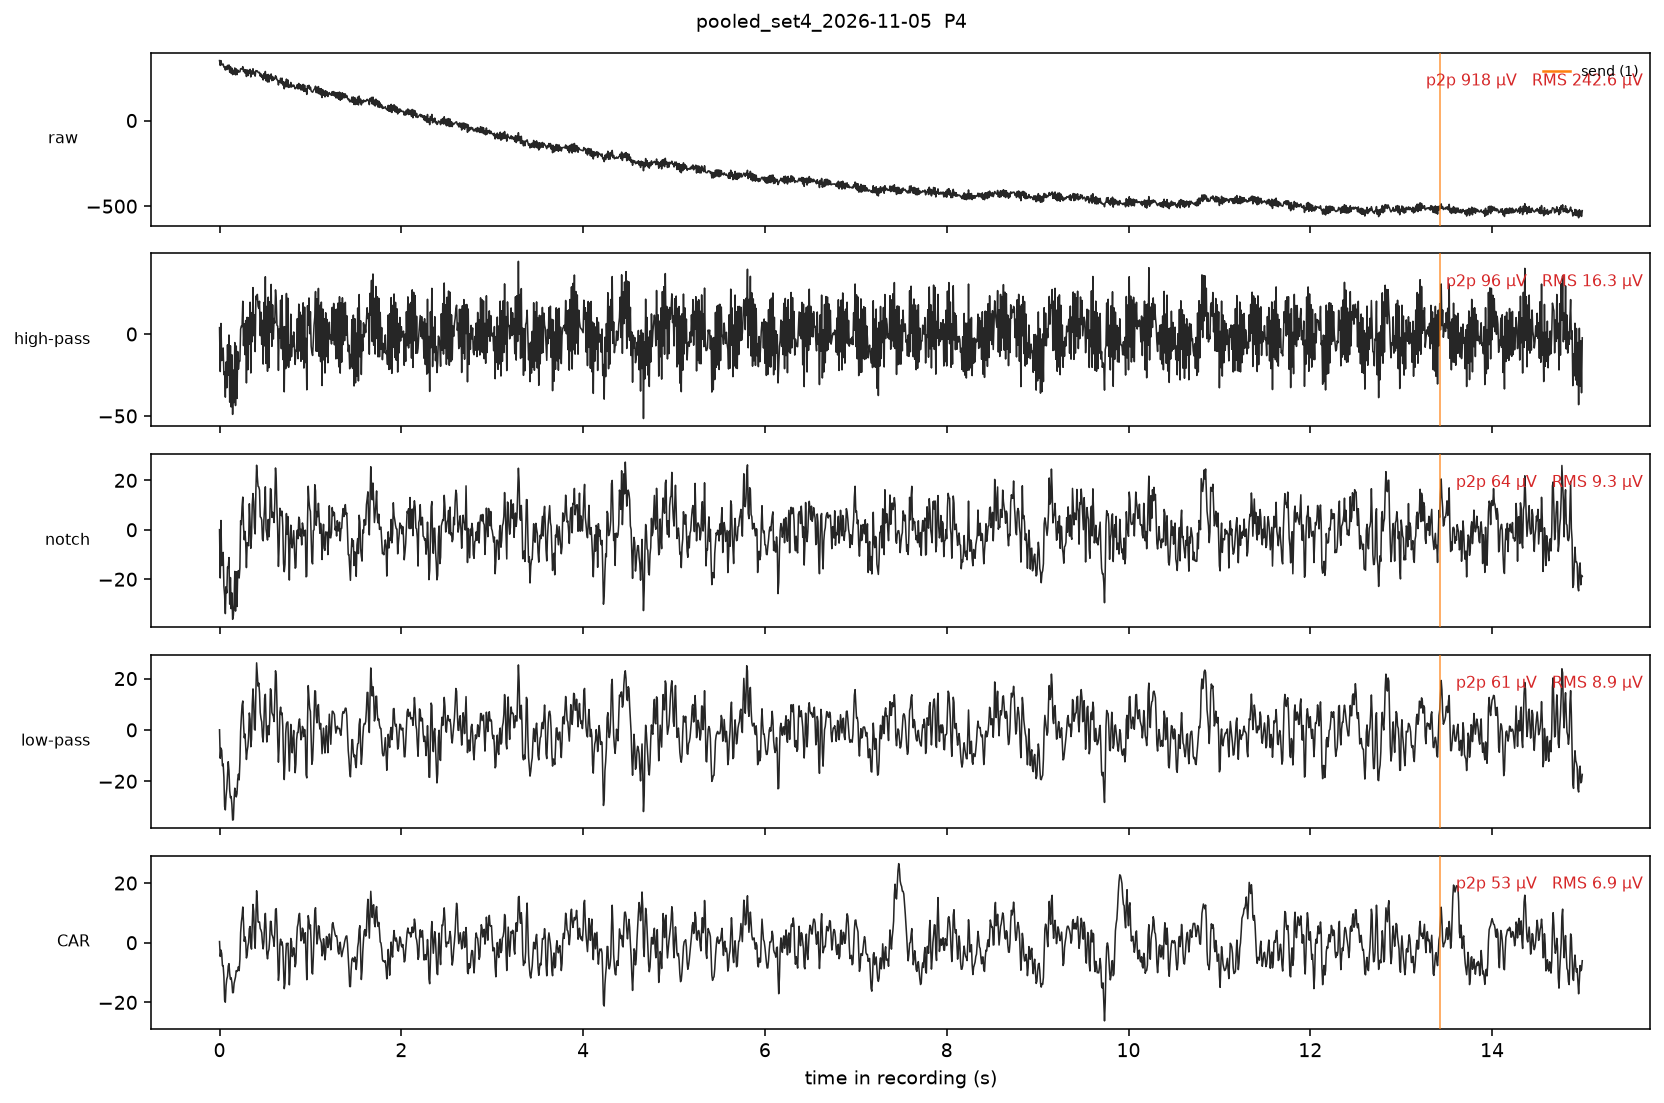

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set4/P4/ladder_one_channel.png


In [188]:
# CELL B — the ladder: ONE channel, every stage, same seconds
CH = globals().get("VIEW_CH_IDX", good[0])  # set VIEW_CH in the pick cell
# Packed-hour seconds for ladder / ICA / side-by-side. Change and re-run B → F.
START_S = first_clean_start(rec)
DUR_S = 15.0
START_S, _snapped = snap_zoom_start(rec, START_S, DUR_S)
if _snapped:
    print(f"window was empty — using START_S={START_S:.1f}s")

def plot_ladder(rec, stages, ch, start_s, dur_s):
    names = list(stages)
    fig, axes = plt.subplots(len(names), 1, figsize=(12, 1.6 * len(names)), sharex=True)
    for i, (ax, n) in enumerate(zip(np.atleast_1d(axes), names)):
        tt, y = rec_window(stages[n][:, ch], start_s, start_s + dur_s)
        tt, y = nan_at_gaps(tt, y)
        ax.plot(tt, y, lw=0.8, color="0.15")
        draw_markers(ax, rec, start_s, start_s + dur_s, x_unit="s", legend=(i == 0))
        ax.set_ylabel(n, rotation=0, ha="right", va="center", fontsize=8)
        yf = y[np.isfinite(y)]
        if yf.size < 10:
            ax.text(0.5, 0.55, "no samples in this window (dropout or join)",
                    transform=ax.transAxes, ha="center", fontsize=8, color="C3")
        else:
            ax.text(0.995, 0.88, f"p2p {np.ptp(yf):.0f} µV   RMS {np.std(yf):.1f} µV",
                    transform=ax.transAxes, ha="right", va="top", fontsize=8, color="C3")
    axes[-1].set_xlabel("time in recording (s)")
    fig.suptitle(f"{rec['id']}  {CHANNEL_LABELS[ch]}", fontsize=10)
    fig.tight_layout()
    return fig

if not window_ok(STAGES["CAR"][:, CH], START_S, START_S + DUR_S):
    START_S = first_clean_start(rec)
    print(f"window was a gap — using START_S={START_S:.1f}s instead")
print(f"ladder window {START_S:.0f}–{START_S + DUR_S:.0f} s   channel {CHANNEL_LABELS[CH]}")
fig = plot_ladder(rec, STAGES, CH, START_S, DUR_S)
show_fig(fig, "ladder_one_channel", rec["out_dir"])


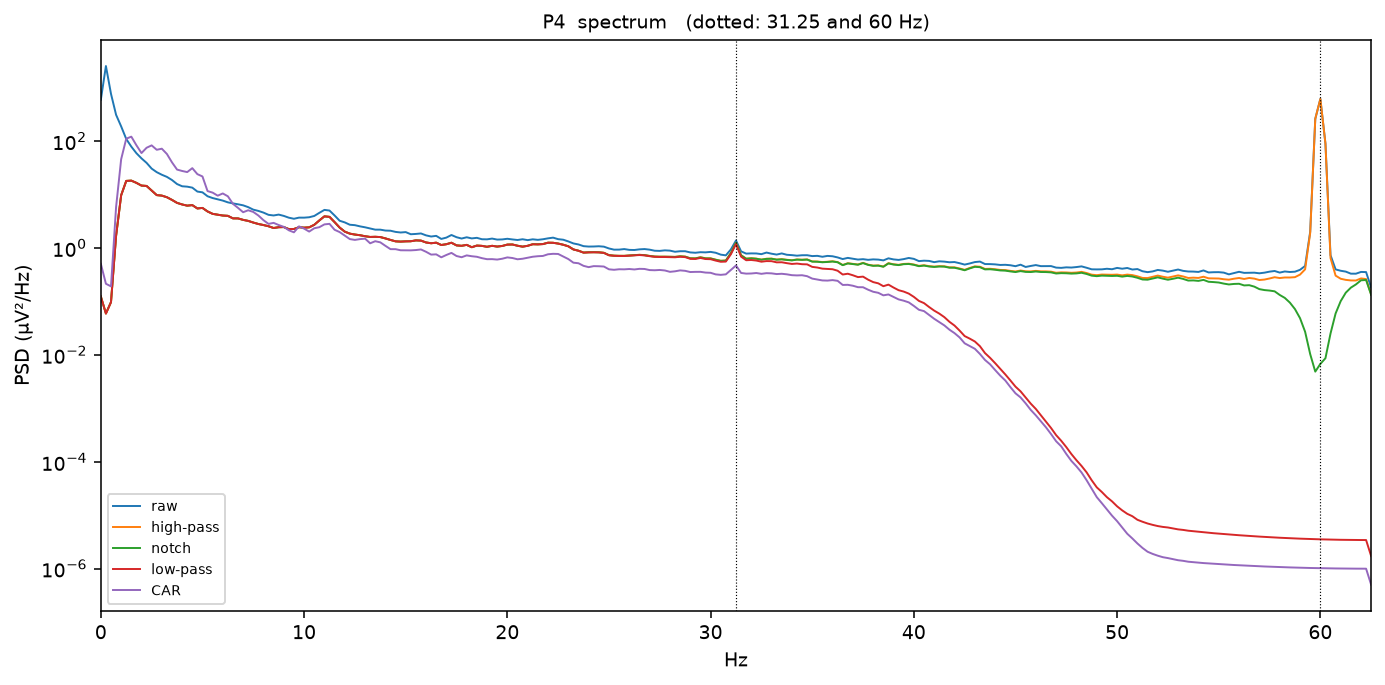

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set4/P4/psd_ladder.png


In [189]:
# CELL C — the same ladder in FREQUENCY (this is where 60 Hz / drift / 31 Hz show)
def plot_psd_ladder(rec, stages, ch):
    fs = rec["fs"]
    fig, ax = plt.subplots(figsize=(10, 5))
    for n, x in stages.items():
        y = x[:, ch]
        y = y[np.isfinite(y)]
        if len(y) < fs * 2:
            continue
        f, p = welch(y, fs=fs, nperseg=min(int(4 * fs), len(y)))
        ax.semilogy(f, p, lw=1.0, label=n)
    ax.set_xlim(0, fs / 2)
    ax.set_xlabel("Hz")
    ax.set_ylabel("PSD (µV²/Hz)")
    ax.axvline(60, color="k", ls=":", lw=0.6)
    ax.axvline(31.25, color="k", ls=":", lw=0.6)
    ax.legend(fontsize=7)
    ax.set_title(f"{CHANNEL_LABELS[ch]}  spectrum   (dotted: 31.25 and 60 Hz)", fontsize=10)
    fig.tight_layout()
    return fig

fig = plot_psd_ladder(rec, STAGES, CH)
show_fig(fig, "psd_ladder", rec["out_dir"])


comp  kurtosis  frontal-weight   (blink = high kurtosis AND high frontal weight)
   0       1.8      0.19
   1     166.1      0.12
   2      20.8      0.25
   3    3112.4      0.17
   4       4.3      0.60
   5      10.6      0.50
   6       1.8      0.15
   7     548.1      0.12
   8      -0.4      0.28
   9    1944.9      0.10
  10       0.4      0.11
  11     450.3      0.19
  12     191.1      0.15


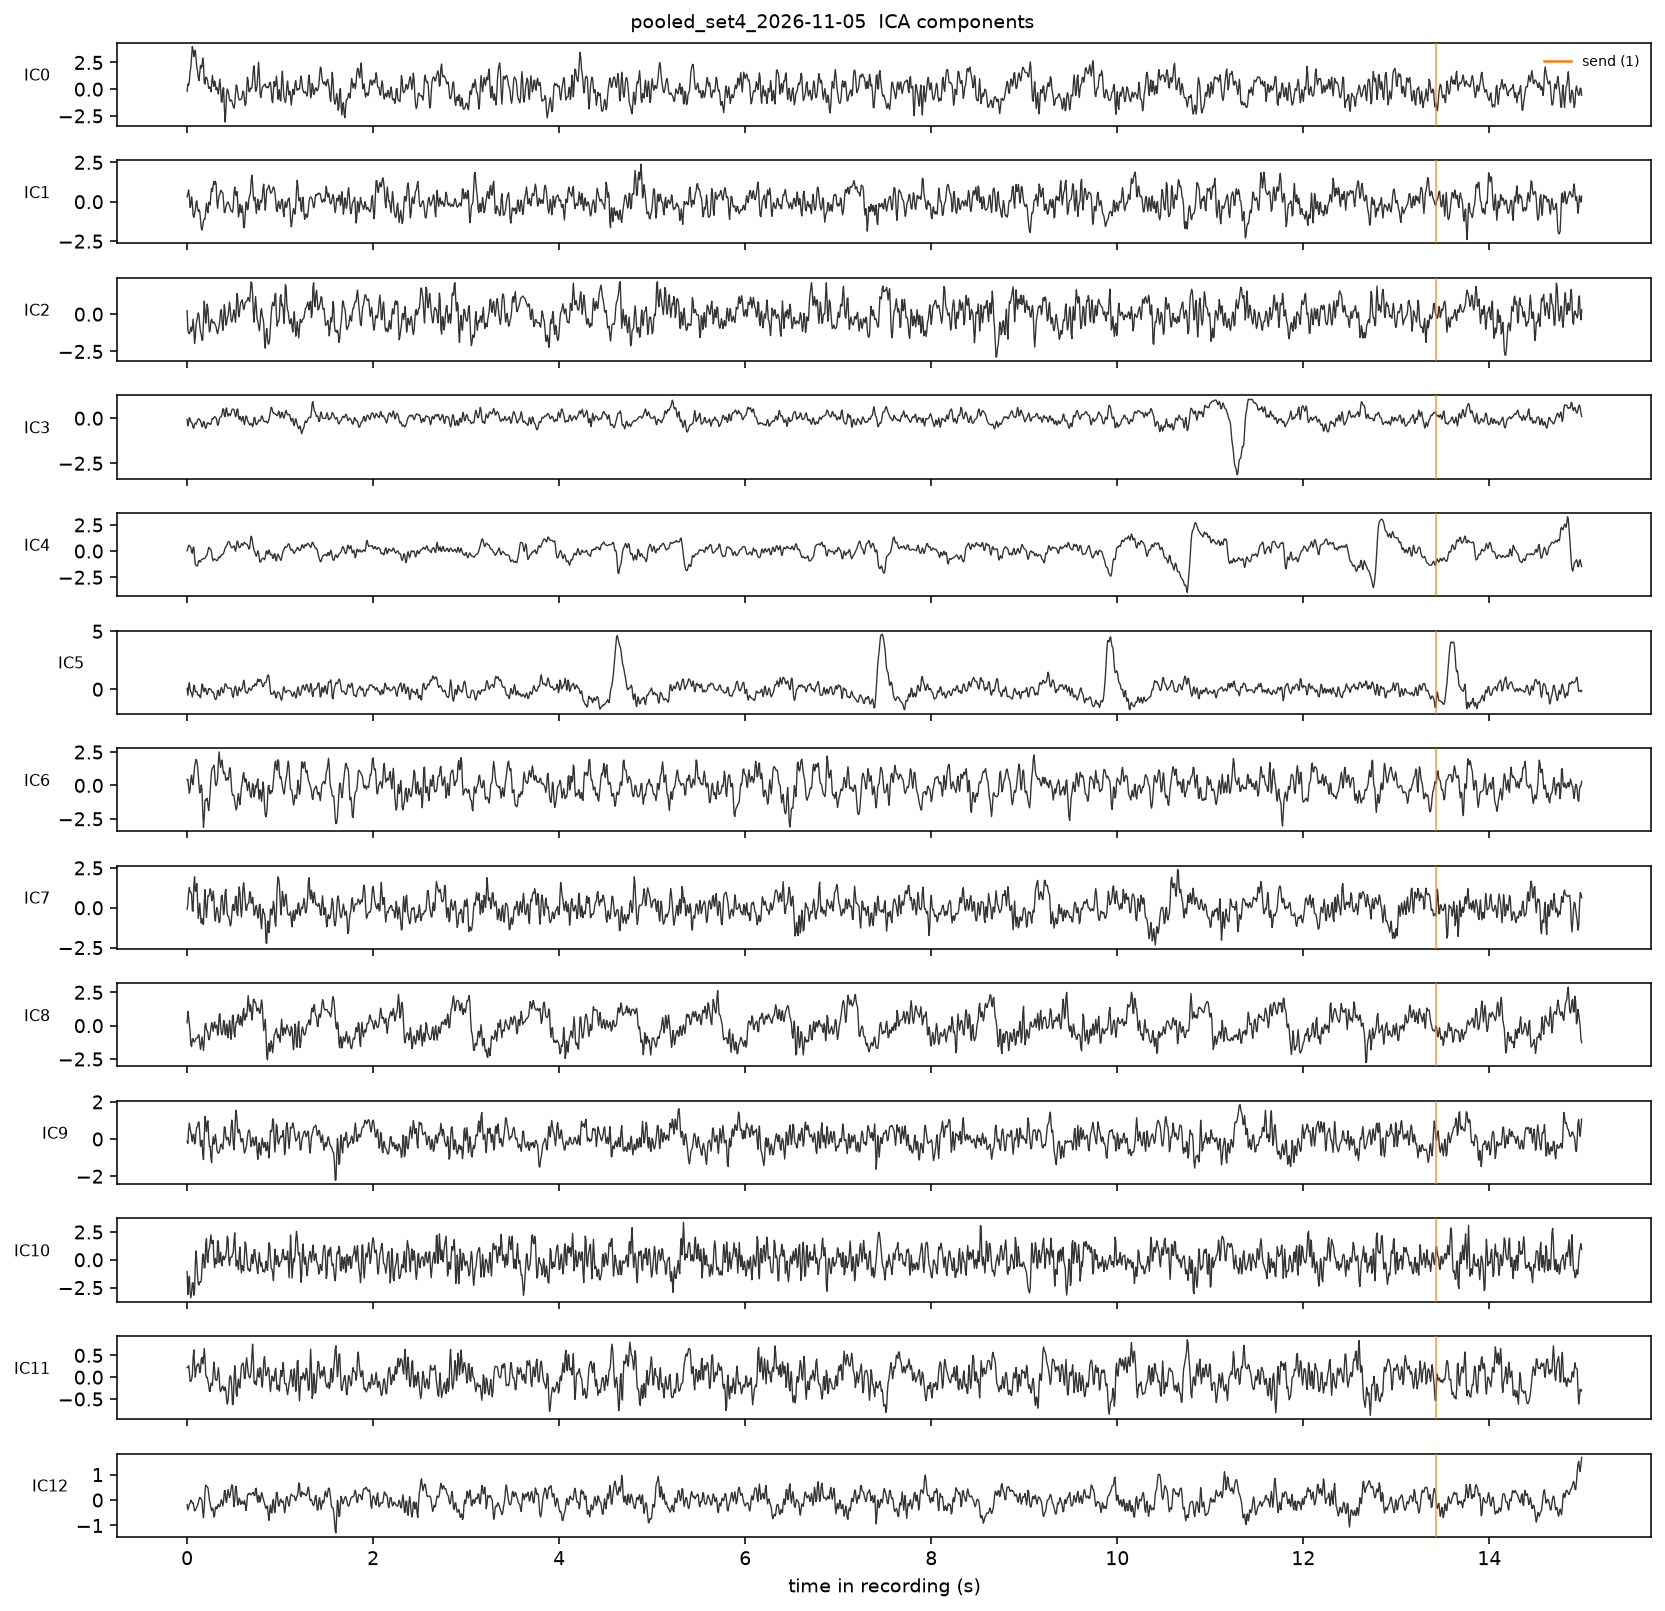

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set4/P4/ica_components.png


In [190]:
# CELL D — ICA: fit, then LOOK at components before deciding what to remove
x4 = STAGES["CAR"]
fs = rec["fs"]
ok = np.isfinite(x4[:, good]).all(axis=1)
if ok.sum() < fs * 10:
    raise RuntimeError("Not enough finite CAR samples to fit ICA (dropouts). Change START_S / SET.")
# fit on a decimated copy of finite samples; 1 Hz high-passed already
ica = FastICA(n_components=max(1, len(good) - 1), whiten="unit-variance", random_state=0, max_iter=1000)
ica.fit(x4[ok][::2, good])
rec["_ica"] = ica
src = np.full((len(x4), ica.n_components), np.nan)
src[ok] = ica.transform(x4[ok][:, good])
mix = ica.mixing_                       # channels x components
labels = [CHANNEL_LABELS[c] for c in good]
rows = []
for k in range(src.shape[1]):
    w = np.abs(mix[:, k])
    w = w / (w.sum() + 1e-12)
    fr = sum(w[labels.index(l)] for l in FRONTAL if l in labels)
    rows.append((k, kurtosis(src[ok, k]), fr))
print("comp  kurtosis  frontal-weight   (blink = high kurtosis AND high frontal weight)")
for k, ku, fr in rows:
    print(f"{k:>4}  {ku:8.1f}  {fr:8.2f}")

fig, axes = plt.subplots(src.shape[1], 1, figsize=(12, 0.9 * src.shape[1]), sharex=True)
for k, ax in enumerate(np.atleast_1d(axes)):
    tt, y = rec_window(src[:, k], START_S, START_S + DUR_S)
    tt, y = nan_at_gaps(tt, y)
    ax.plot(tt, y, lw=0.7, color="0.2")
    draw_markers(ax, rec, START_S, START_S + DUR_S, x_unit="s", legend=(k == 0))
    ax.set_ylabel(f"IC{k}", rotation=0, ha="right", fontsize=8)
axes[-1].set_xlabel("time in recording (s)")
fig.suptitle(f"{rec['id']}  ICA components", fontsize=10)
fig.tight_layout()
show_fig(fig, "ica_components", rec["out_dir"])


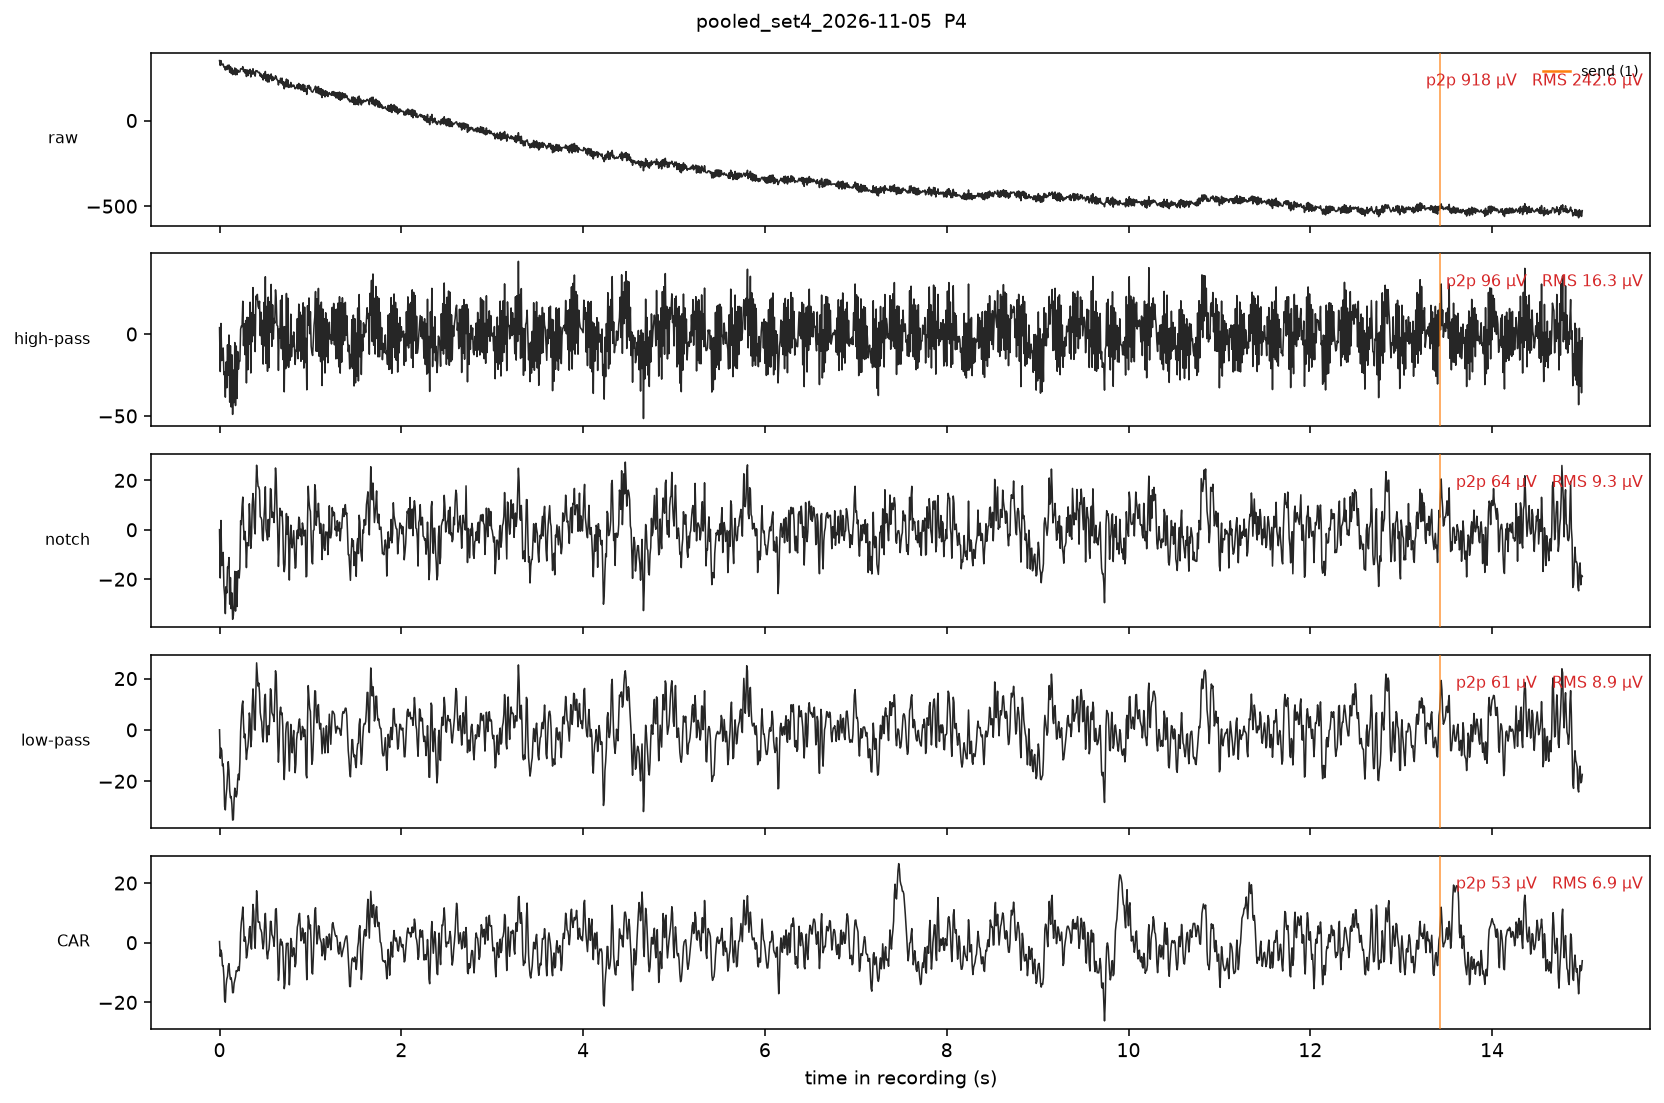

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set4/P4/ladder_with_ica.png
ICA_DROP []
stages now: ['raw', 'high-pass', 'notch', 'low-pass', 'CAR']


In [191]:
# CELL E — choose components, rebuild, re-plot the ladder with the ICA step
ICA_DROP = []           # after Cell D. Blink = high kurtosis AND high frontal. e.g. [0] or [0, 3]. [] = drop none.
STAGES = build_stages(rec, good, ica_drop=ICA_DROP)
fig = plot_ladder(rec, STAGES, CH, START_S, DUR_S)
show_fig(fig, "ladder_with_ica", rec["out_dir"])
print("ICA_DROP", ICA_DROP)
print("stages now:", list(STAGES))


final stage: CAR
channels: ['C3', 'C4', 'P7', 'P8', 'O1', 'O2', 'F7', 'F8', 'F3', 'F4', 'T7', 'T8', 'P3', 'P4']


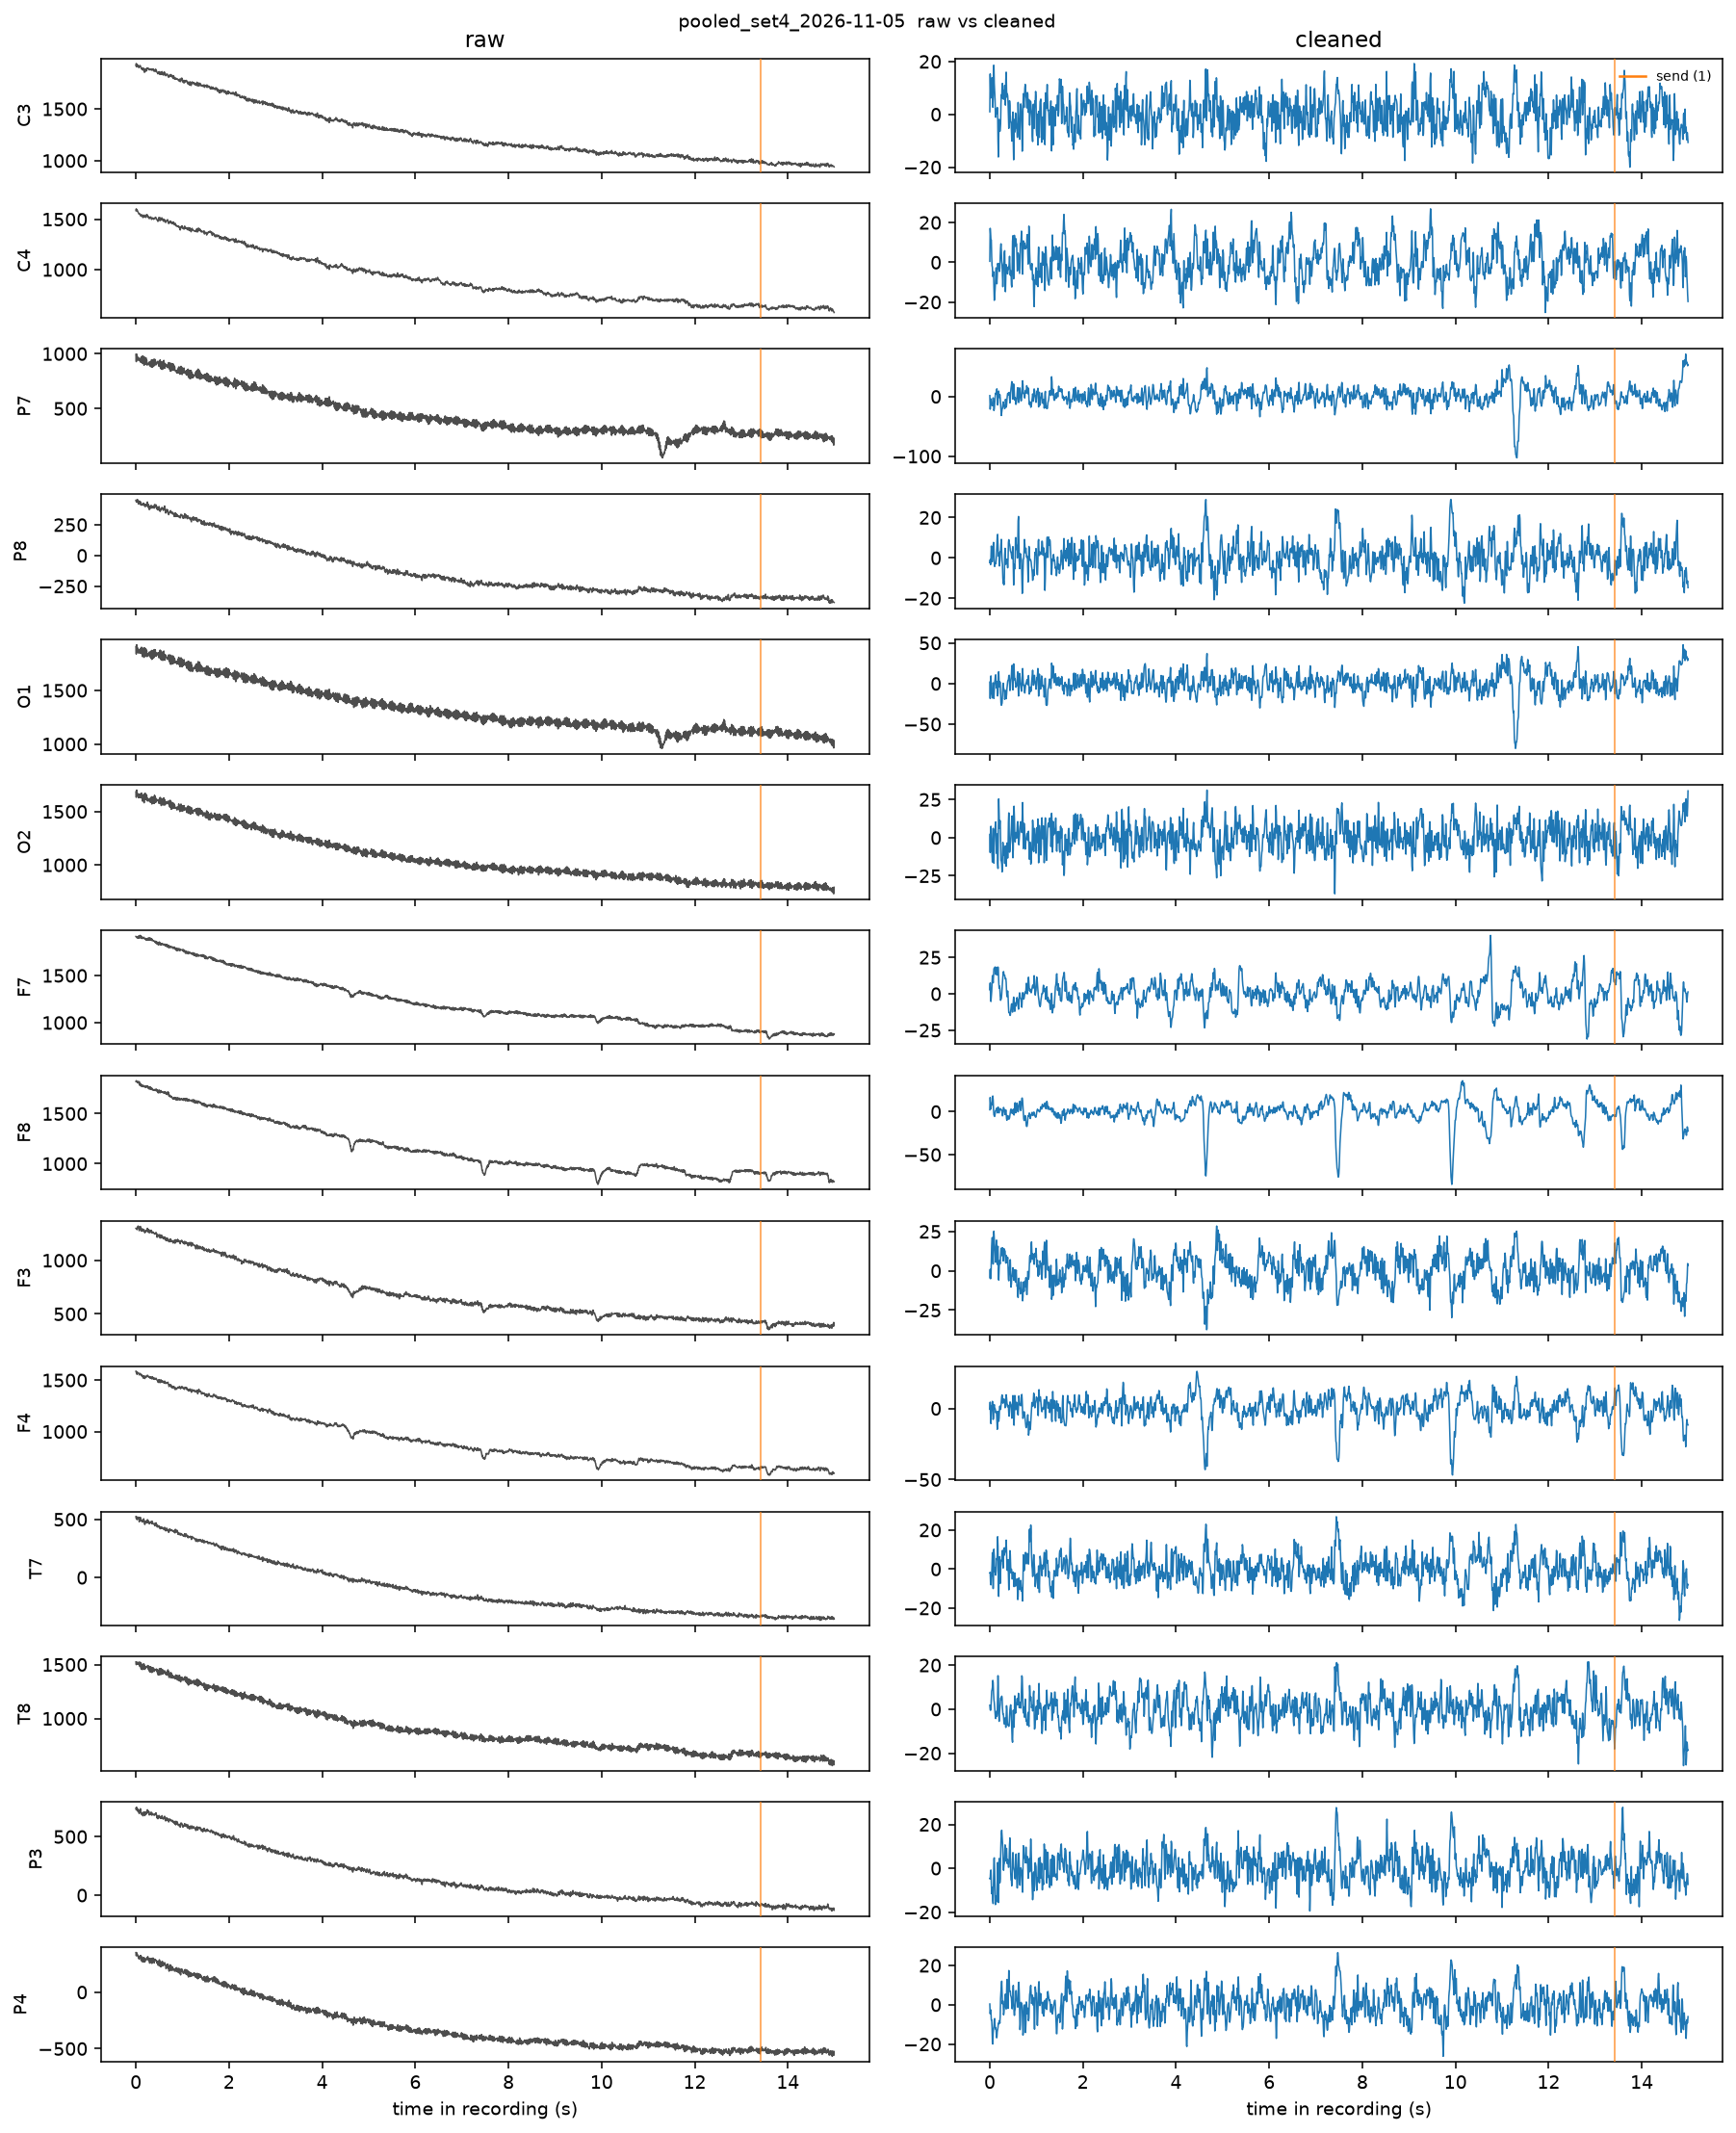

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set4/P4/side_by_side_raw_vs_clean.png


In [192]:
# CELL F — raw vs final, side by side, every USABLE channel
FINAL = list(STAGES)[-1]
WIN_START, WIN_DUR = START_S, DUR_S       # change WIN_START to a phone stretch (marker 11 -> 12)
CHS = list(good)   # every USABLE channel from QC

def plot_side_by_side(rec, stages, final, chs, start_s, dur_s):
    raw = stages[list(stages)[0]]
    fin = stages[final]
    fig, axes = plt.subplots(len(chs), 2, figsize=(13, max(4.0, 1.15 * len(chs))), sharex=True)
    for r, c in enumerate(chs):
        tt0, y0 = nan_at_gaps(*rec_window(raw[:, c], start_s, start_s + dur_s))
        tt1, y1 = nan_at_gaps(*rec_window(fin[:, c], start_s, start_s + dur_s))
        axes[r, 0].plot(tt0, y0, lw=0.8, color="0.3")
        axes[r, 1].plot(tt1, y1, lw=0.8, color="C0")   # own y-scale on purpose
        axes[r, 0].set_ylabel(CHANNEL_LABELS[c], fontsize=9)
        draw_markers(axes[r, 0], rec, start_s, start_s + dur_s, x_unit="s")
        draw_markers(axes[r, 1], rec, start_s, start_s + dur_s, x_unit="s", legend=(r == 0))
    axes[0, 0].set_title("raw")
    axes[0, 1].set_title("cleaned")
    axes[-1, 0].set_xlabel("time in recording (s)")
    axes[-1, 1].set_xlabel("time in recording (s)")
    fig.suptitle(f"{rec['id']}  raw vs cleaned", fontsize=10)
    fig.tight_layout()
    return fig

print("final stage:", FINAL)
print("channels:", [CHANNEL_LABELS[c] for c in CHS])
fig = plot_side_by_side(rec, STAGES, FINAL, CHS, WIN_START, WIN_DUR)
show_fig(fig, "side_by_side_raw_vs_clean", rec["out_dir"])


## 5. Meeting plots — what the wave is doing

**G1** (next cell) lists every marker 1 / 11 / 12 in a table. Copy a `t_s`.
**G2** (the cell after that) plots that clip and lets you set leftover peak / trough bands.

**Clip** = an 8-second piece we cut so the wiggles are visible. Time 0 is the left edge of that piece.

Left column is **reading from the same Set 2 trial**: the 8 s *immediately before* the text (marker 1). It is not a separate baseline day. Right column is the 8 s *after pickup* (marker 11) of that same trial. Both columns use the **same cleaned signal** and the **same y-scale per row**.

**n=13** = 13 events where we could cut the full −0.5 to +2 s window without hitting a headset gap or the end of the file. (14 pickups happened; 1 sat on a gap, so 13 overlays.)

**Pre-event mean removed** is standard ERP practice (baseline correction). Each ping has a slightly different leftover offset (the trace sitting at +8 µV vs −3 µV). Subtract that trial’s own 0.5 s before the marker so all 13 sit on zero and you compare the *wiggle after the beep*, not the leftover bias. The event is still there.

Five-band plot: same one trial, split into delta / theta / alpha / beta / gamma. Markers 1, 11, 12 on every row.


### G1 — marker times

Run this cell. It prints every 1 / 11 / 12 with `t_s`. Copy one time into `ANN_START_WANT` in **G2**.

In [193]:
# Meeting G1 — marker times. Copy a t_s into G2 to choose the clip.

def stitch_cleaned(rec, good):
    """Filter each QC segment, write back onto the full recording timeline.
    Marker times (file seconds) then line up with the cleaned voltage."""
    stages = globals().get("STAGES") or {}
    fs = rec["fs"]
    n, n_ch = rec["eeg"].shape
    # If STAGES only covers segment 0, still stitch from rec["segs"] so later pickups exist.
    def hp(x):
        return sosfiltfilt(butter(4, HP_HZ, "highpass", fs=fs, output="sos"), x, axis=0)
    def nt(x):
        b, a = iirnotch(NOTCH, NOTCH_Q, fs=fs)
        return sosfiltfilt(tf2sos(b, a), x, axis=0)
    def lpf(x):
        return sosfiltfilt(butter(4, LP_HZ, "lowpass", fs=fs, output="sos"), x, axis=0)
    out = np.full((n, n_ch), np.nan)
    for seg in rec["segs"]:
        raw = np.asarray(seg["raw"], dtype=float)
        if len(raw) < int(3 * fs):
            continue
        x = raw - np.median(raw, axis=0)
        x = lpf(nt(hp(x)))
        keep = [c for c in good if c < n_ch]
        if keep:
            x[:, keep] = x[:, keep] - np.nanmean(x[:, keep], axis=1, keepdims=True)
        out[seg["idx"]] = x
    drop = [int(k) for k in (globals().get("ICA_DROP") or [])]
    ica = rec.get("_ica")
    keep = [c for c in good if c < n_ch]
    if ica is not None and drop and keep:
        ok = np.isfinite(out[:, keep]).all(axis=1)
        if ok.any():
            src = ica.transform(out[ok][:, keep])
            src[:, drop] = 0
            out[np.ix_(ok, keep)] = ica.inverse_transform(src)
        return out, f"CAR+ICA drop {drop}"
    return out, "CAR (all segments)"


def rec_slice(x, t0, t1):
    """Finite samples only (RMS / peaks). Dropouts are omitted, not interpolated."""
    t, y = rec_window(x, t0, t1)
    m = np.isfinite(y)
    return t[m], y[m]


def _pearson(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    m = np.isfinite(a) & np.isfinite(b)
    a, b = a[m], b[m]
    if len(a) < 5 or np.std(a) < 1e-9 or np.std(b) < 1e-9:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])


def recurring_band(heights, lo, hi, band_uv, min_recur, kind, quiet=False):
    """Prefer a typed band if it already recurs. Else the densest band_uv window, not the tallest."""
    h = np.asarray(heights, dtype=float)
    n = len(h)
    if n == 0:
        if not quiet:
            print(f"  {kind}: no candidates")
        return None, None, np.zeros(0, dtype=bool)
    if lo is not None and hi is not None:
        m = (h >= float(lo)) & (h <= float(hi))
        if int(m.sum()) >= min_recur:
            if not quiet:
                print(f"  {kind}: typed {float(lo):.0f}–{float(hi):.0f} µV  (n={int(m.sum())})")
            return float(lo), float(hi), m
        if not quiet:
            print(f"  {kind}: typed {float(lo):.0f}–{float(hi):.0f} µV has {int(m.sum())} "
                  f"(need >= {min_recur}) — auto")
    hsort = np.sort(h)
    best_n, best_i = 0, 0
    j = 0
    for i in range(len(hsort)):
        while j < len(hsort) and (hsort[j] - hsort[i]) <= band_uv:
            j += 1
        if (j - i) > best_n:
            best_n = j - i
            best_i = i
    alo = float(hsort[best_i])
    ahi = float(hsort[best_i] + band_uv)
    m = (h >= alo) & (h <= ahi)
    if int(m.sum()) >= min_recur:
        if not quiet:
            print(f"  {kind}: auto {alo:.1f}–{ahi:.1f} µV  (n={int(m.sum())} recurring)")
        return alo, ahi, m
    if not quiet:
        print(f"  {kind}: no band with >= {min_recur} (best n={int(m.sum())} at {alo:.1f}–{ahi:.1f} µV)")
    return None, None, np.zeros(n, dtype=bool)


def leftover_marks(tt, x, fs, min_prom=8.0, min_recur=3, band_uv=10.0, min_sep_s=0.08,
                   drop_s=0.50, peak_lo=None, peak_hi=None, trough_lo=None, trough_hi=None,
                   quiet=False):
    """Recurring peak/trough pairs on one clip. Same rules as G2."""
    sep = max(1, int(min_sep_s * fs))
    pk, _ = find_peaks(x, prominence=min_prom, distance=sep)
    tr, _ = find_peaks(-x, prominence=min_prom, distance=sep)
    pk_h = x[pk] if len(pk) else np.array([])
    tr_h = x[tr] if len(tr) else np.array([])
    peak_lo, peak_hi, m_pk = recurring_band(pk_h, peak_lo, peak_hi, band_uv, min_recur, "peaks", quiet=quiet)
    trough_lo, trough_hi, m_tr = recurring_band(tr_h, trough_lo, trough_hi, band_uv, min_recur, "troughs", quiet=quiet)
    pk_keep = pk[m_pk] if len(pk) else pk
    tr_keep = tr[m_tr] if len(tr) else tr
    saw = []
    for p in pk_keep:
        later = [q for q in tr_keep if q > p and (tt[q] - tt[p]) <= drop_s]
        if not later:
            continue
        q = min(later, key=lambda qi: x[qi])
        saw.append((int(p), int(q), float(x[p] - x[q])))
    return dict(pk=pk, tr=tr, saw=saw, peak_lo=peak_lo, peak_hi=peak_hi,
                trough_lo=trough_lo, trough_hi=trough_hi)


def fit_repeating_leftover(tt, x, saw, n_grid=80, min_period=0.15):
    """Mean peak-to-peak cycle, tiled. Same red fit as the rough-pattern cell."""
    cycles, periods = [], []
    grid = np.linspace(0, 1, n_grid, endpoint=False)
    for (a, _, _), (b, _, _) in zip(saw[:-1], saw[1:]):
        w = float(tt[b] - tt[a])
        if w < min_period:
            continue
        t_c = (tt[a:b] - tt[a]) / w
        y_c = np.asarray(x[a:b], dtype=float)
        if len(y_c) < 5 or t_c[-1] <= t_c[0]:
            continue
        cycles.append(np.interp(grid, t_c, y_c))
        periods.append(w)
    if len(cycles) < 1:
        return None
    tmpl = np.mean(np.vstack(cycles), axis=0)
    T = float(np.median(periods))
    t0 = float(tt[saw[0][0]])
    phase = np.mod(tt - t0, T) / T
    y_fit = np.interp(phase, grid, tmpl)
    r_tile = _pearson(x, y_fit)
    ss_res = float(np.nansum((x - y_fit) ** 2))
    ss_tot = float(np.nansum((x - np.nanmean(x)) ** 2))
    r2_tile = float(1.0 - ss_res / ss_tot) if ss_tot > 0 else np.nan
    rmse = float(np.sqrt(np.nanmean((x - y_fit) ** 2)))
    r_shape = float(np.nanmean([_pearson(c, tmpl) for c in cycles]))
    return dict(tmpl=tmpl, T=T, y_fit=y_fit, cycles=cycles, periods=periods,
                r_tile=r_tile, r2_tile=r2_tile, rmse=rmse, r_shape=r_shape, t0=t0)


def fitted_clip_path(start, set_id=None, ch=None):
    set_id = int(rec.get("set") if set_id is None else set_id)
    ch = int(globals().get("CH_ANN", VIEW_CH_IDX) if ch is None else ch)
    d = subject_root() / set_dirname(set_id) / CHANNEL_LABELS[ch] / "fitted_clips"
    d.mkdir(parents=True, exist_ok=True)
    return d / f"t{float(start):.1f}.npz"


def save_fitted_clip(start, tt, x, fit, saw, set_id=None, ch=None, marks=None, code=None):
    path = fitted_clip_path(start, set_id=set_id, ch=ch)
    extra = {}
    if code is not None:
        extra["code"] = np.array([int(code)])
    if marks is not None:
        saw = marks.get("saw") or saw
        extra = dict(
            peak_lo=np.array([np.nan if marks.get("peak_lo") is None else float(marks["peak_lo"])]),
            peak_hi=np.array([np.nan if marks.get("peak_hi") is None else float(marks["peak_hi"])]),
            trough_lo=np.array([np.nan if marks.get("trough_lo") is None else float(marks["trough_lo"])]),
            trough_hi=np.array([np.nan if marks.get("trough_hi") is None else float(marks["trough_hi"])]),
            pk=np.asarray(marks.get("pk", []), int),
            tr=np.asarray(marks.get("tr", []), int),
            saw_p=np.asarray([p for p, q, d in saw], int),
            saw_q=np.asarray([q for p, q, d in saw], int),
        )
    np.savez(
        path,
        tt=np.asarray(tt, float), x=np.asarray(x, float), y_fit=np.asarray(fit["y_fit"], float),
        tmpl=np.asarray(fit["tmpl"], float), T=np.array([float(fit["T"])]),
        start=np.array([float(start)]),
        n_peak=np.array([len(saw)]), n_trough=np.array([len(saw)]),
        n_cycle=np.array([len(fit["cycles"])]),
        **extra,
    )
    return path


def plot_clip_leftover(tt, x, fit, marks, title, path):
    """Leftover + recurring peak/trough marks + red fit."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    saw = list(marks.get("saw") or [])
    pk = np.asarray(marks.get("pk", []), int)
    tr = np.asarray(marks.get("tr", []), int)
    fig, ax = plt.subplots(figsize=(11, 3.6))
    ax.plot(tt, x, color="0.18", lw=1.1, label="leftover")
    ax.axhline(0, color="0.75", lw=0.5)
    plo, phi = marks.get("peak_lo"), marks.get("peak_hi")
    tlo, thi = marks.get("trough_lo"), marks.get("trough_hi")
    if plo is not None and phi is not None and np.isfinite(plo) and np.isfinite(phi):
        ax.axhspan(plo, phi, color="C3", alpha=0.08, zorder=0)
    if tlo is not None and thi is not None and np.isfinite(tlo) and np.isfinite(thi):
        ax.axhspan(tlo, thi, color="C0", alpha=0.08, zorder=0)
    if len(pk):
        ax.plot(tt[pk], x[pk], "v", color="0.7", ms=5, label="other peak")
    if len(tr):
        ax.plot(tt[tr], x[tr], "^", color="0.7", ms=5, label="other trough")
    if saw:
        sp = np.array([p for p, q, d in saw], int)
        sq = np.array([q for p, q, d in saw], int)
        ax.plot(tt[sp], x[sp], "v", color="C3", ms=9, label="recurring peak")
        ax.plot(tt[sq], x[sq], "^", color="C0", ms=9, label="recurring trough")
    if fit is not None and fit.get("y_fit") is not None:
        ax.plot(tt, fit["y_fit"], color="C3", lw=2.0, label="fitted leftover")
    ax.set_xlabel("session seconds")
    ax.set_ylabel("µV")
    ax.set_title(title, fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc="upper right", ncol=2)
    fig.tight_layout()
    fig.savefig(str(path), dpi=120, bbox_inches="tight")
    plt.close(fig)
    return path


def plot_clip_fit_only(tt, x, y_fit, title, path):
    """Grey leftover + red tiled fit only (the cleaner clip view)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(12, 2.8))
    ax.plot(tt, x, color="0.75", lw=1.0, label="leftover")
    if y_fit is not None:
        ax.plot(tt, y_fit, color="C3", lw=1.8, label="fitted leftover")
    ax.axhline(0, color="0.85", lw=0.5)
    ax.set_xlabel("session seconds")
    ax.set_ylabel("µV")
    ax.set_title(title, fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    fig.tight_layout()
    fig.savefig(str(path), dpi=120, bbox_inches="tight")
    plt.close(fig)
    return path


HP_HZ = globals().get("HP_HZ", 1.0)
LP_HZ = globals().get("LP_HZ", 40.0)
NOTCH = globals().get("NOTCH", 60.0)
NOTCH_Q = globals().get("NOTCH_Q", 30.0)

X_CLEAN, CLEAN_NAME = stitch_cleaned(rec, good)
print("using", CLEAN_NAME, X_CLEAN.shape, "finite frac", float(np.isfinite(X_CLEAN).mean()))

CH_ANN = int(globals().get("VIEW_CH_IDX", next((c for c in good if CHANNEL_LABELS[c] in ("C3", "P3", "C4", "P4")), good[0])))
ANN_DUR = 4.0            # 4 or 8 (seconds on this recording)

_ev = marker_times_s(rec)
MARK_WHAT = {0: "reading", 1: "shock", 11: "attention disruption", 12: "recovery"}
_MARK_NAME = {1: "shock (1)", 11: "attention disruption (11)", 12: "recovery (12)"}
print(f"markers on this recording — copy t_s into ANN_START_WANT in the next cell  (clip = {ANN_DUR:.0f} s from that time)")
rows = []
for i, (t, v) in enumerate(_ev):
    rows.append({
        "#": i,
        "t_s": round(float(t), 1),
        "code": int(v),
        "what": _MARK_NAME.get(int(v), str(int(v))),
        "clip if you start there": f"{t:.1f}–{t + ANN_DUR:.1f} s",
    })
df_markers = pd.DataFrame(rows)
if len(df_markers) == 0:
    print("  (no 1 / 11 / 12 in this recording)")
else:
    display(df_markers)
    print(df_markers.to_string(index=False))
print("Next cell: paste a t_s into ANN_START_WANT, then set the leftover peak/trough bands.")


using CAR (all segments) (200217, 16) finite frac 0.9201816029607875
markers on this recording — copy t_s into ANN_START_WANT in the next cell  (clip = 4 s from that time)


,#,t_s,code,what,clip if you start there
0,0,13.4,1,shock (1),13.4–17.4 s
1,1,149.2,1,shock (1),149.2–153.2 s
2,2,191.6,1,shock (1),191.6–195.6 s
3,3,243.3,1,shock (1),243.3–247.3 s
4,4,320.3,1,shock (1),320.3–324.3 s
5,5,498.6,1,shock (1),498.6–502.6 s
6,6,698.6,1,shock (1),698.6–702.6 s
7,7,896.8,1,shock (1),896.8–900.8 s
8,8,1115.2,1,shock (1),1115.2–1119.2 s
9,9,1241.3,1,shock (1),1241.3–1245.3 s


 #    t_s  code      what clip if you start there
 0   13.4     1 shock (1)             13.4–17.4 s
 1  149.2     1 shock (1)           149.2–153.2 s
 2  191.6     1 shock (1)           191.6–195.6 s
 3  243.3     1 shock (1)           243.3–247.3 s
 4  320.3     1 shock (1)           320.3–324.3 s
 5  498.6     1 shock (1)           498.6–502.6 s
 6  698.6     1 shock (1)           698.6–702.6 s
 7  896.8     1 shock (1)           896.8–900.8 s
 8 1115.2     1 shock (1)         1115.2–1119.2 s
 9 1241.3     1 shock (1)         1241.3–1245.3 s
10 1343.0     1 shock (1)         1343.0–1347.0 s
11 1394.6     1 shock (1)         1394.6–1398.6 s
12 1570.0     1 shock (1)         1570.0–1574.0 s
Next cell: paste a t_s into ANN_START_WANT, then set the leftover peak/trough bands.


### G2 — choose a clip, mark leftover peaks and troughs

Paste a `t_s` from the G1 table into `ANN_START_WANT`. Leave `SAW_PEAK_*` / `SAW_TROUGH_*` as `None` to auto-pick the µV band that recurs at least `MIN_RECUR` times (not the tallest spikes). Type a band only if you want to lock it.

In [ ]:
# Meeting G2 — pick the clip (t_s from the table), then leftover peak / trough bands
ANN_START_WANT = 420.1    # None = auto. Or a time from the table, e.g. 215.0
ANN_DUR = float(globals().get("ANN_DUR", 4.0))

_ev = marker_times_s(rec)
_pairs_tmp = []
_used = set()
for t, v in _ev:
    if v != 11:
        continue
    later = [u for u, w in _ev if w == 12 and u > t and u not in _used]
    if later:
        _pairs_tmp.append((t, later[0]))
        _used.add(later[0])

candidates = []
for t11, t12 in _pairs_tmp:
    candidates.append(t11 + 2.0)          # after the reach-for-phone spike
    candidates.append(t11 - 1.0)          # just before pickup
candidates.append(first_clean_start(rec))
# any later 4 s block that is actually filled
t_all = session_t_s(rec)
t_lo, t_hi = float(t_all[0]), float(t_all[-1]) - ANN_DUR
s = t_lo
while s < t_hi:
    candidates.append(s)
    s += 10.0

xch = X_CLEAN[:, CH_ANN]
ANN_START = None
if ANN_START_WANT is not None:
    want = float(ANN_START_WANT)
    if window_ok(xch, want, want + ANN_DUR):
        ANN_START = want
    else:
        ANN_START, _ = snap_zoom_start(rec, want, ANN_DUR)
        print(f"ANN_START_WANT={want:.1f}s had a gap — using {ANN_START:.1f}s")
else:
    for s in candidates:
        if s < t_lo or s + ANN_DUR > t_all[-1] + 1:
            continue
        if window_ok(xch, s, s + ANN_DUR):
            ANN_START = float(s)
            break
if ANN_START is None:
    raise RuntimeError(f"No {ANN_DUR:.0f} s clip without a dropout on this channel. Try another VIEW_CH or set ANN_START_WANT.")
print(f"annotated clip {ANN_START:.1f}–{ANN_START + ANN_DUR:.1f} s  "
      f"({'your pick' if ANN_START_WANT is not None else 'auto'}; {len(_pairs_tmp)} pickup pairs in rec)")

# Recurring leftover: keep a µV band that shows up often, not the tallest spikes.
MIN_PROM_UV = 8.0        # skip tiny wiggles; recurrence (not height) decides which marks to keep
MIN_RECUR = 3            # keep a band if it has at least this many peaks (same for troughs)
BAND_UV = 10.0           # width of one peak/trough band when auto-picking
MIN_PEAK_SEP_S = 0.08    # do not double-mark two peaks closer than this
SAW_DROP_S = 0.50        # pair a peak with a trough within this many seconds
# Optional lock. None = auto (densest band with count >= MIN_RECUR).
SAW_PEAK_LO = None       # e.g. 10.0
SAW_PEAK_HI = None       # e.g. 20.0
SAW_TROUGH_LO = None     # e.g. -15.0
SAW_TROUGH_HI = None     # e.g. 0.0

tt_win, x_win = rec_window(xch, ANN_START, ANN_START + ANN_DUR)
tt_win, x_win = nan_at_gaps(tt_win, x_win)
tt, x = rec_slice(xch, ANN_START, ANN_START + ANN_DUR)
marks = leftover_marks(
    tt, x, rec["fs"],
    min_prom=MIN_PROM_UV, min_recur=MIN_RECUR, band_uv=BAND_UV,
    min_sep_s=MIN_PEAK_SEP_S, drop_s=SAW_DROP_S,
    peak_lo=SAW_PEAK_LO, peak_hi=SAW_PEAK_HI,
    trough_lo=SAW_TROUGH_LO, trough_hi=SAW_TROUGH_HI,
)
pk, tr, saw = marks["pk"], marks["tr"], marks["saw"]
SAW_PEAK_LO, SAW_PEAK_HI = marks["peak_lo"], marks["peak_hi"]
SAW_TROUGH_LO, SAW_TROUGH_HI = marks["trough_lo"], marks["trough_hi"]

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(tt_win, x_win, color="0.15", lw=1.2)
ax.axhline(0, color="0.75", lw=0.6)
if SAW_PEAK_LO is not None and SAW_PEAK_HI is not None:
    ax.axhspan(SAW_PEAK_LO, SAW_PEAK_HI, color="C3", alpha=0.08, zorder=0)
if SAW_TROUGH_LO is not None and SAW_TROUGH_HI is not None:
    ax.axhspan(SAW_TROUGH_LO, SAW_TROUGH_HI, color="C0", alpha=0.08, zorder=0)
draw_markers(ax, rec, ANN_START, ANN_START + ANN_DUR, x_unit="s", legend=True)
ax.plot(tt[pk], x[pk], "v", color="0.75", ms=5, label="other peak")
ax.plot(tt[tr], x[tr], "^", color="0.75", ms=5, label="other trough")

ylo = float(np.nanmin(x_win)) if np.isfinite(x_win).any() else -40.0
yhi = float(np.nanmax(x_win)) if np.isfinite(x_win).any() else 40.0
span = max(yhi - ylo, 1.0)
# extra room inside the axes so labels sit in the plot, not on the title
ax.set_ylim(ylo - 0.08 * span, yhi + 0.48 * span)

if saw:
    sp = np.array([p for p, q, d in saw])
    sq = np.array([q for p, q, d in saw])
    ax.plot(tt[sp], x[sp], "v", color="C3", ms=10, label="recurring peak")
    ax.plot(tt[sq], x[sq], "^", color="C0", ms=10, label="recurring trough")
    # stagger Hz labels on two rows so neighbors do not sit on top of each other
    y_hz_lo = yhi + 0.10 * span
    y_hz_hi = yhi + 0.28 * span
    k = 0
    for (a, qa, da), (b, qb, db) in zip(saw[:-1], saw[1:]):
        w = float(tt[b] - tt[a])
        if w < 0.04:
            continue
        y_hz = y_hz_hi if (k % 2 == 0) else y_hz_lo
        ax.annotate("", xy=(tt[b], y_hz), xytext=(tt[a], y_hz),
                    arrowprops=dict(arrowstyle="<->", color="C3", lw=0.9))
        ax.text((tt[a] + tt[b]) / 2, y_hz + 0.015 * span,
                f"{w*1000:.0f} ms\n{1/w:.1f} Hz",
                ha="center", va="bottom", fontsize=8, color="C3", linespacing=1.15)
        k += 1
    p0, q0, d0 = saw[0]
    ax.annotate("", xy=(tt[p0], x[p0]), xytext=(tt[p0], x[q0]),
                arrowprops=dict(arrowstyle="<->", color="C0", lw=0.9))
    ax.text(tt[p0] + 0.04, (x[p0] + x[q0]) / 2, f"{d0:.0f} µV drop",
            fontsize=8, color="C0")
    ax.text(tt[p0] + 0.04, x[p0] + 2, f"peak {x[p0]:.0f} µV",
            fontsize=8, color="C3")
ax.set_xlabel("time in recording (s)")
ax.set_ylabel("µV")
ax.set_title(f"{rec['id']}  {CHANNEL_LABELS[CH_ANN]}  {CLEAN_NAME}   {ANN_DUR:.0f}s",
             fontsize=10, pad=10)
ax.legend(loc="lower right", fontsize=8, frameon=False, ncol=2)
fig.tight_layout()
show_fig(fig, "meeting_annotated_wave", rec["out_dir"])

ANN_TT, ANN_X, ANN_SAW = tt, x, saw  # keep this clip; later cells reuse the name tt
print(f"{CHANNEL_LABELS[CH_ANN]}  {ANN_START:.1f}–{ANN_START + ANN_DUR:.1f} s")
_pband = (f"{SAW_PEAK_LO:.0f}–{SAW_PEAK_HI:.0f} µV" if SAW_PEAK_LO is not None else "no recurring peak band")
_tband = (f"{SAW_TROUGH_LO:.0f}–{SAW_TROUGH_HI:.0f} µV" if SAW_TROUGH_LO is not None else "no recurring trough band")
print(f"all peaks {len(pk)}; recurring pairs {len(saw)}  (peak {_pband}, trough {_tband})")
if saw:
    widths = [float(tt[saw[i+1][0]] - tt[saw[i][0]]) for i in range(len(saw)-1)]
    print(f"{'#':>3}  {'t_s':>7}  {'peak µV':>8}  {'trough µV':>10}  {'drop µV':>8}  {'to next':>10}")
    for i, (p, q, d) in enumerate(saw):
        nxt = f"{widths[i]*1000:.0f} ms  {1/widths[i]:.1f} Hz" if i < len(widths) else ""
        print(f"{i:>3}  {tt[p]:7.2f}  {x[p]:8.1f}  {x[q]:10.1f}  {d:8.1f}  {nxt}")
    if widths:
        w = np.array(widths)
        print(f"spacing: {1000*w.min():.0f}–{1000*w.max():.0f} ms   mean {1000*w.mean():.0f} ms  ({1/w.mean():.1f} Hz)")
        print(f"peak height: {np.min([x[p] for p,q,d in saw]):.0f}–{np.max([x[p] for p,q,d in saw]):.0f} µV")
        print(f"drop: {np.min([d for p,q,d in saw]):.0f}–{np.max([d for p,q,d in saw]):.0f} µV")
    print("Hz here is 1 / time between those recurring peaks — not an FFT.")
else:
    print("no recurring peak–trough pairs in this clip. Lower MIN_PROM_UV or MIN_RECUR, or pick another START.")


In [ ]:
# Rough repeating leftover — mean cycle from the tall peaks, tiled across this clip
# Run Meeting G first, then this cell (do not rely on `tt` — other cells overwrite it).
if "ANN_SAW" not in dir() or "ANN_TT" not in dir() or len(ANN_TT) == 0:
    raise RuntimeError("Re-run Meeting G first so ANN_TT / ANN_SAW are saved.")
tt, x, saw = ANN_TT, ANN_X, ANN_SAW
if len(saw) < 2:
    raise RuntimeError("Need ≥2 recurring peaks from Meeting G. Loosen MIN_PROM_UV / MIN_RECUR there, re-run G, then this cell.")
if max(p for p, q, d in saw) >= len(tt):
    raise RuntimeError("Peak indices do not match this clip. Re-run Meeting G, then this cell.")

fit = fit_repeating_leftover(tt, x, saw)
if fit is None:
    raise RuntimeError("Could not cut peak-to-peak cycles. Check marks on Meeting G.")
tmpl, T, y_fit = fit["tmpl"], fit["T"], fit["y_fit"]
cycles, r_tile, r2_tile, rmse, r_shape = fit["cycles"], fit["r_tile"], fit["r2_tile"], fit["rmse"], fit["r_shape"]
t0 = fit["t0"]

fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(tt, x, color="0.55", lw=1.0, alpha=0.28, zorder=1, label="leftover voltage")
ax.plot(tt, y_fit, color="C3", lw=2.6, zorder=3,
        label=f"rough pattern  ({1/T:.1f} Hz, {len(cycles)} cycles, r={r_tile:.2f})")
ax.plot(tt[[p for p, q, d in saw]], x[[p for p, q, d in saw]], "v", color="C3", ms=8, zorder=4)
ax.axhline(0, color="0.85", lw=0.6, zorder=0)
ax.set_xlabel("time in recording (s)")
ax.set_ylabel("µV")
ax.set_title(f"{CHANNEL_LABELS[CH_ANN]}  rough pattern")
ax.legend(loc="upper right", fontsize=9, frameon=False)
fig.tight_layout()
show_fig(fig, "meeting_rough_pattern", rec["out_dir"])

print(f"{CHANNEL_LABELS[CH_ANN]}  n_cycles={len(cycles)}  period={1000*T:.0f} ms  ({1/T:.1f} Hz)")
print(f"template peak {np.max(tmpl):.0f} µV   trough {np.min(tmpl):.0f} µV   drop {np.max(tmpl)-np.min(tmpl):.0f} µV")
print(f"tiled red vs leftover:  r={r_tile:.2f}   R²={r2_tile:.2f}   typical miss {rmse:.1f} µV")
print(f"bump shape vs mean bump: r={r_shape:.2f}   (ignores the fixed clock)")
print("r is -1 to 1.  1 = red tracks grey,  0 = unrelated,  negative = opposite.")
print("R² is the fraction of leftover variance the tiled red line accounts for; it can be low if peak spacing wanders even when the bump shape is good.")
print("This is the average of one peak-to-peak cycle, repeated. Same leftover on reading and phone is still not a phone inverse.")

# Keep this leftover + red fit on disk. Re-run G (new t_s) + this cell to add another segment.
_t0 = float(globals().get("ANN_START", t0))
_path = save_fitted_clip(_t0, tt, x, fit, saw, marks=globals().get("marks"))
n_stored = len(list(_path.parent.glob("t*.npz")))
print(f"stored this clip → {_path}")
print(f"{n_stored} fitted segment(s) for {CHANNEL_LABELS[CH_ANN]} set {rec.get('set')}.")
print("To add another: copy a t_s into ANN_START_WANT in G2, or run the batch cell on the G1 table.")


### G-batch — fit leftover at every timestamp in the G1 table

G1 / G2 still work one clip at a time. This cell walks the table and, **for each timestamp separately**, auto-picks that clip’s recurring peak band, that clip’s trough band, and that clip’s red cycle. A band that fit 170 s is not reused at 420 s.

Only the *method* is shared (recurring marks + tiled mean cycle). The voltages and the template are new on every 4 s clip. The table this cell prints has each clip’s peak µV band and trough µV band so you can see they differ.

Then run section 8. Those cells only read `fitted_clips/`.

`BATCH_CODES = None` uses every row. Set it to `(1,)` if you only want marker 1.

In [194]:
# G-batch — one independent leftover fit per timestamp (own peak band, own trough band, own red cycle)
BATCH_CODES = None          # None = all rows in df_markers. Or (1,) for send/ping only.
BATCH_SKIP_EXISTING = False  # False = overwrite last night's npz + peak/fit pngs in the same folders
BATCH_SAVE_PLOTS = True     # leftover + peak/trough marks + red fit, one png per clip
MIN_SAW_SAVE = 3            # need at least this many recurring pairs, same bar as section 8
# Do not pass G2's SAW_PEAK_* / SAW_TROUGH_*. Each clip auto-picks its own µV band.

if "X_CLEAN" not in globals() or "df_markers" not in globals():
    raise RuntimeError("Run G1 first so X_CLEAN and the marker table exist.")

rows = df_markers.copy()
if BATCH_CODES is not None:
    rows = rows[rows["code"].isin(list(BATCH_CODES))]
if len(rows) == 0:
    # Baseline (no 1/11/12): take every 10 s that holds a full clip.
    print("G1 table empty — using a 10 s grid of clip starts (typical for set 1).")
    t_all = session_t_s(rec)
    ANN_DUR = float(globals().get("ANN_DUR", 4.0))
    starts = np.arange(float(t_all[0]), float(t_all[-1]) - ANN_DUR, 10.0)
    rows = pd.DataFrame({"t_s": starts, "code": 0})

CH_ANN = int(globals().get("CH_ANN", VIEW_CH_IDX))
ANN_DUR = float(globals().get("ANN_DUR", 4.0))
MIN_PROM_UV = float(globals().get("MIN_PROM_UV", 8.0))
MIN_RECUR = int(globals().get("MIN_RECUR", 3))
BAND_UV = float(globals().get("BAND_UV", 10.0))
MIN_PEAK_SEP_S = float(globals().get("MIN_PEAK_SEP_S", 0.08))
SAW_DROP_S = float(globals().get("SAW_DROP_S", 0.50))
xch = X_CLEAN[:, CH_ANN]
clip_dir = fitted_clip_path(0.0).parent
print(f"batch {CHANNEL_LABELS[CH_ANN]}  set {rec.get('set')}  {len(rows)} timestamp(s)  →  {clip_dir}")
print(f"knobs: PROM={MIN_PROM_UV:g}  MIN_RECUR={MIN_RECUR}  BAND={BAND_UV:g} µV  clip={ANN_DUR:g} s")

batch_rows = []
n_new = n_skip = n_fail = 0
for _, row in rows.iterrows():
    t_want = float(row["t_s"])
    code = int(row["code"])
    path = fitted_clip_path(t_want)
    if BATCH_SKIP_EXISTING and path.exists():
        n_skip += 1
        z = np.load(path)
        def _s(key, default=np.nan):
            if key not in z.files:
                return default
            v = np.asarray(z[key]).reshape(-1)
            return default if len(v) == 0 else v[0].item()
        T = _s("T", np.nan)
        batch_rows.append(dict(
            t_s=t_want, code=code, status="exists",
            n_saw=_s("n_peak", np.nan), n_cycle=_s("n_cycle", np.nan),
            r=np.nan, Hz=(1.0 / T if T and T == T and T != 0 else np.nan),
            peak_lo=_s("peak_lo"), peak_hi=_s("peak_hi"),
            trough_lo=_s("trough_lo"), trough_hi=_s("trough_hi"),
        ))
        continue
    if not window_ok(xch, t_want, t_want + ANN_DUR):
        t_use, jumped = snap_zoom_start(rec, t_want, ANN_DUR)
        if jumped and not window_ok(xch, t_use, t_use + ANN_DUR):
            n_fail += 1
            batch_rows.append(dict(t_s=t_want, code=code, status="gap", n_saw=np.nan, n_cycle=np.nan, r=np.nan, Hz=np.nan,
                                   peak_lo=np.nan, peak_hi=np.nan, trough_lo=np.nan, trough_hi=np.nan))
            continue
    else:
        t_use = t_want
    tt, x = rec_slice(xch, t_use, t_use + ANN_DUR)
    if len(x) < int(0.5 * rec["fs"]):
        n_fail += 1
        batch_rows.append(dict(t_s=t_want, code=code, status="short", n_saw=np.nan, n_cycle=np.nan, r=np.nan, Hz=np.nan,
                               peak_lo=np.nan, peak_hi=np.nan, trough_lo=np.nan, trough_hi=np.nan))
        continue
    # None, None = auto on THIS clip only. G2's SAW_PEAK_* from another timestamp is ignored.
    marks = leftover_marks(
        tt, x, rec["fs"],
        min_prom=MIN_PROM_UV, min_recur=MIN_RECUR, band_uv=BAND_UV,
        min_sep_s=MIN_PEAK_SEP_S, drop_s=SAW_DROP_S,
        peak_lo=None, peak_hi=None, trough_lo=None, trough_hi=None,
        quiet=True,
    )
    saw = marks["saw"]
    band = dict(
        peak_lo=marks["peak_lo"], peak_hi=marks["peak_hi"],
        trough_lo=marks["trough_lo"], trough_hi=marks["trough_hi"],
    )
    if len(saw) < MIN_SAW_SAVE:
        n_fail += 1
        batch_rows.append(dict(t_s=t_want, code=code, status=f"marks={len(saw)}", n_saw=len(saw),
                               n_cycle=np.nan, r=np.nan, Hz=np.nan, **band))
        continue
    fit = fit_repeating_leftover(tt, x, saw)
    if fit is None:
        n_fail += 1
        batch_rows.append(dict(t_s=t_want, code=code, status="no cycle", n_saw=len(saw),
                               n_cycle=0, r=np.nan, Hz=np.nan, **band))
        continue
    save_fitted_clip(t_use, tt, x, fit, saw, marks=marks, code=code)
    n_new += 1
    batch_rows.append(dict(
        t_s=t_use, code=code, status="saved", n_saw=len(saw),
        n_cycle=len(fit["cycles"]), r=fit["r_tile"], Hz=1.0 / fit["T"],
        **band,
    ))
    hz = (1.0 / fit["T"]) if fit["T"] else np.nan
    what = (globals().get("MARK_WHAT") or {1: "shock", 11: "attention disruption", 12: "recovery"}).get(int(code), f"marker {code}")
    title = f"{CHANNEL_LABELS[CH_ANN]}  t={t_use:.1f}s  {what}  {len(saw)} peaks  {len(fit['cycles'])} cycles  {hz:.1f} Hz"
    plot_clip_fit_only(tt, x, fit["y_fit"], title, fitted_clip_path(t_use).with_suffix(".png"))
    if BATCH_SAVE_PLOTS:
        plot_dir = Path(rec["out_dir"]) / "plots"
        plot_clip_leftover(
            tt, x, fit, marks,
            title=title,
            path=plot_dir / f"t{t_use:.1f}_peaks_fit.png",
        )

df_batch = pd.DataFrame(batch_rows)
print(f"saved {n_new}   skipped existing {n_skip}   no-fit {n_fail}")
print(f"folder now has {len(list(clip_dir.glob('t*.npz')))} npz file(s)")
display(df_batch)
print(df_batch.to_string(index=False))
print("Next: section 8. 8a loads this folder; 8b–8e stack / mean / baseline / LOO.")

batch P4  set 4  13 timestamp(s)  →  /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set4/P4/fitted_clips
knobs: PROM=8  MIN_RECUR=3  BAND=10 µV  clip=4 s
saved 12   skipped existing 0   no-fit 1
folder now has 12 npz file(s)


,t_s,code,status,n_saw,n_cycle,r,Hz,peak_lo,peak_hi,trough_lo,trough_hi
0,13.4,1,saved,11.0,5.0,0.164370,1.785714,2.704087,12.704087,-17.127931,-7.127931
1,149.2,1,saved,6.0,2.0,0.006989,0.892857,9.501581,19.501581,-7.500786,2.499214
2,191.6,1,saved,12.0,8.0,-0.002706,4.166667,3.043183,13.043183,-19.971907,-9.971907
3,243.3,1,saved,18.0,11.0,0.056698,4.807694,4.057900,14.057900,-13.690182,-3.690182
4,320.3,1,saved,22.0,9.0,0.030580,4.310347,-0.200050,9.799950,-14.261814,-4.261814
5,498.6,1,saved,17.0,9.0,0.064758,3.787880,1.803988,11.803988,-17.199286,-7.199286
6,698.6,1,saved,22.0,8.0,-0.045145,5.434786,0.455203,10.455203,-14.099533,-4.099533
7,896.8,1,saved,19.0,10.0,0.055982,3.676473,3.648687,13.648687,-10.873240,-0.873240
8,1115.2,1,short,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1241.3,1,saved,18.0,9.0,-0.139067,4.032256,5.177639,15.177639,-13.858966,-3.858966


   t_s  code status  n_saw  n_cycle         r       Hz   peak_lo   peak_hi  trough_lo  trough_hi
  13.4     1  saved   11.0      5.0  0.164370 1.785714  2.704087 12.704087 -17.127931  -7.127931
 149.2     1  saved    6.0      2.0  0.006989 0.892857  9.501581 19.501581  -7.500786   2.499214
 191.6     1  saved   12.0      8.0 -0.002706 4.166667  3.043183 13.043183 -19.971907  -9.971907
 243.3     1  saved   18.0     11.0  0.056698 4.807694  4.057900 14.057900 -13.690182  -3.690182
 320.3     1  saved   22.0      9.0  0.030580 4.310347 -0.200050  9.799950 -14.261814  -4.261814
 498.6     1  saved   17.0      9.0  0.064758 3.787880  1.803988 11.803988 -17.199286  -7.199286
 698.6     1  saved   22.0      8.0 -0.045145 5.434786  0.455203 10.455203 -14.099533  -4.099533
 896.8     1  saved   19.0     10.0  0.055982 3.676473  3.648687 13.648687 -10.873240  -0.873240
1115.2     1  short    NaN      NaN       NaN      NaN       NaN       NaN        NaN        NaN
1241.3     1  saved   18.0    

In [177]:
# Redraw the clean leftover + red-fit pngs from stored .npz (does not re-fit).
# Overwrites fitted_clips/t{t}.png next to each npz. Does not touch plots/*_peaks_fit.png.
def plot_clip_fit_only(tt, x, y_fit, title, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(12, 2.8))
    ax.plot(tt, x, color="0.75", lw=1.0, label="leftover")
    if y_fit is not None:
        ax.plot(tt, y_fit, color="C3", lw=1.8, label="fitted leftover")
    ax.axhline(0, color="0.85", lw=0.5)
    ax.set_xlabel("session seconds")
    ax.set_ylabel("µV")
    ax.set_title(title, fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    fig.tight_layout()
    fig.savefig(str(path), dpi=120, bbox_inches="tight")
    plt.close(fig)
    return path

clip_dir = fitted_clip_path(0.0).parent
ch = CHANNEL_LABELS[int(globals().get("CH_ANN", VIEW_CH_IDX))]
MARK_WHAT = globals().get("MARK_WHAT") or {1: "shock", 11: "attention disruption", 12: "recovery"}
table = []
if "df_markers" in globals() and len(globals()["df_markers"]):
    table = [(float(r["t_s"]), int(r["code"])) for _, r in df_markers.iterrows()]
n = 0
for p in sorted(clip_dir.glob("t*.npz"), key=lambda q: float(q.stem[1:])):
    z = np.load(p)
    tt, x, y_fit = z["tt"], z["x"], z["y_fit"]
    start = float(np.asarray(z["start"]).reshape(-1)[0])
    T = float(np.asarray(z["T"]).reshape(-1)[0])
    n_peak = int(np.asarray(z["n_peak"]).reshape(-1)[0])
    n_cycle = int(np.asarray(z["n_cycle"]).reshape(-1)[0])
    hz = (1.0 / T) if T else float("nan")
    code = int(np.asarray(z["code"]).reshape(-1)[0]) if "code" in z.files else 0
    if not code and table:
        bt, bc = min(table, key=lambda tv: abs(tv[0] - start))
        if abs(bt - start) <= 2.0:
            code = int(bc)
    what = MARK_WHAT.get(code, "unknown")
    plot_clip_fit_only(
        tt, x, y_fit,
        title=f"{ch}  t={start:.1f}s  {what}  {n_peak} peaks  {n_cycle} cycles  {hz:.1f} Hz",
        path=p.with_suffix(".png"),
    )
    n += 1
print(f"wrote {n} clean leftover+fit pngs → {clip_dir}")

wrote 62 clean leftover+fit pngs → /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set3/P4/fitted_clips


## 8. Collective leftover — one small step at a time

This section only **reads** `fitted_clips/` for the current channel and set. It does not re-pick peaks.

**How clips get into that folder**

- One at a time: G2 (`ANN_START_WANT`) → rough-pattern cell, or
- All timestamps: G-batch (walks the G1 table).

Then run: **show stored clips → stack → mean leftover → does it overfit? → baseline stack → close the gap**.

**Leave-one-out (LOO)** hides one clip, builds the leftover from the rest, and asks how well that leftover matches the hidden clip. If leftover is the same leftover, r stays high. If the mean was only memorizing those particular wiggles, r on the hidden clip drops. A 70/30 split does the same idea with a chunk held out at once.

The later **map LOO** (8e) is different: it asks whether a baseline→distract shift/scale still works on a clip that was not used to fit that map.

Baseline compare: run G-batch on **set 1** (same `VIEW_CH`) so `…/baseline/<channel>/fitted_clips/` has files. 8d reads them from there.

CAR stays whatever you already used in the leftover cleanup.


P4  set 4  /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set4/P4/fitted_clips
12 segment(s) ready:
  t=13.4s  shock  11 peaks  5 cycles  period 560 ms
  t=149.2s  shock  6 peaks  2 cycles  period 1120 ms
  t=191.6s  shock  12 peaks  8 cycles  period 240 ms
  t=243.3s  shock  18 peaks  11 cycles  period 208 ms
  t=320.3s  shock  22 peaks  9 cycles  period 232 ms
  t=498.6s  shock  17 peaks  9 cycles  period 264 ms
  t=698.6s  shock  22 peaks  8 cycles  period 184 ms
  t=896.8s  shock  19 peaks  10 cycles  period 272 ms
  t=1241.3s  shock  18 peaks  9 cycles  period 248 ms
  t=1343.0s  shock  21 peaks  10 cycles  period 220 ms
  t=1394.6s  shock  15 peaks  6 cycles  period 268 ms
  t=1570.0s  shock  17 peaks  12 cycles  period 220 ms


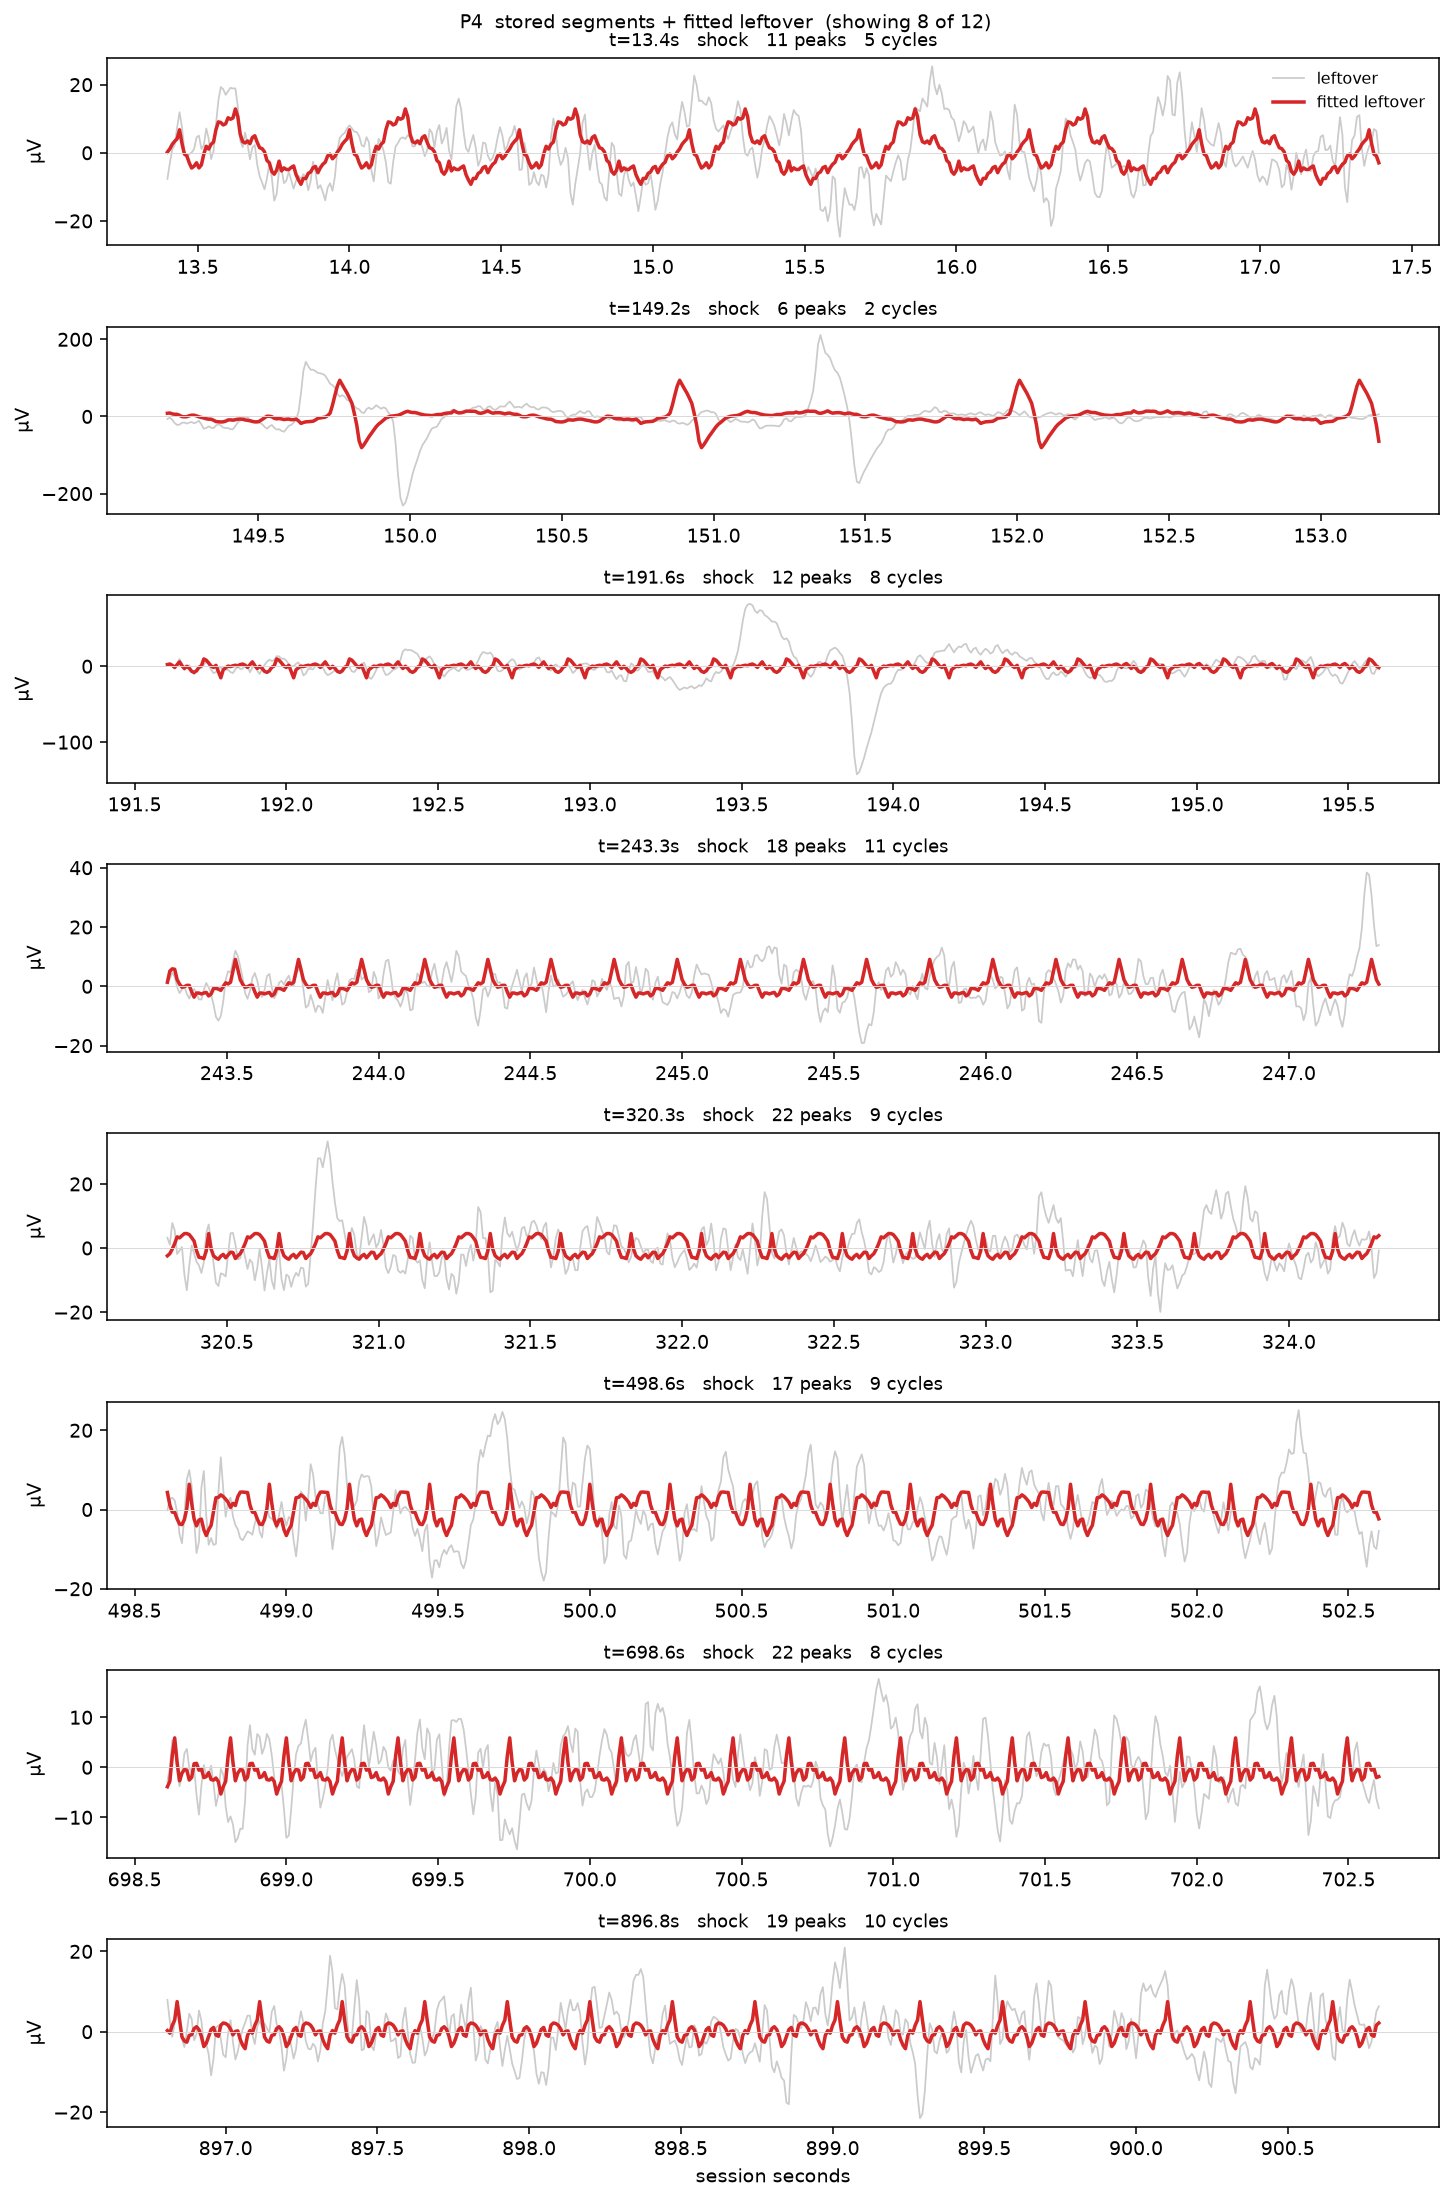

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set4/P4/collect_all_clips.png
gallery shows 8 of 12; the stack uses all 12.


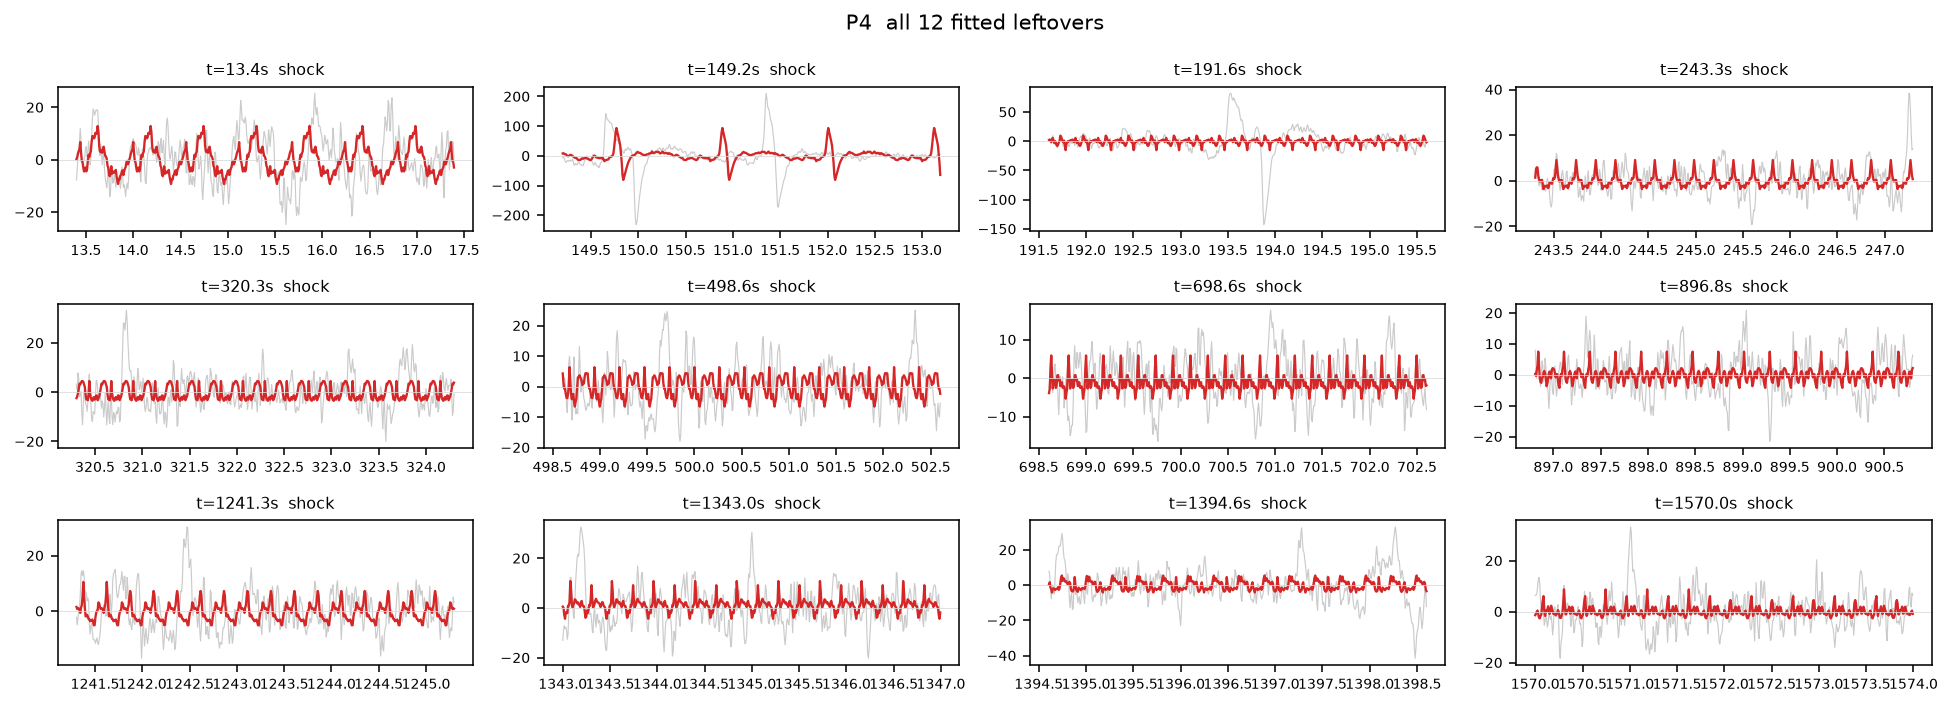

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set4/P4/collect_all_clips_grid.png


In [195]:
# 8a — show every stored segment: leftover (grey) + fitted leftover (red)
COLLECT_MIN_PEAKS = 3      # more than 2
COLLECT_MIN_TROUGHS = 3


def fitted_clips_dir(set_id=None, ch=None):
    set_id = int(rec.get("set") if set_id is None else set_id)
    ch = int(globals().get("CH_ANN", VIEW_CH_IDX) if ch is None else ch)
    d = subject_root() / set_dirname(set_id) / CHANNEL_LABELS[ch] / "fitted_clips"
    d.mkdir(parents=True, exist_ok=True)
    return d


def _npz_scalar(z, key, default=np.nan):
    if key not in z.files:
        return default
    v = np.asarray(z[key]).reshape(-1)
    return default if len(v) == 0 else v[0].item()


MARK_WHAT = globals().get("MARK_WHAT") or {1: "shock", 11: "attention disruption", 12: "recovery"}


def _event_table():
    rows = []
    if "df_markers" in globals() and len(globals()["df_markers"]):
        for _, r in df_markers.iterrows():
            rows.append((float(r["t_s"]), int(r["code"])))
        return rows
    if "rec" in globals():
        for t, v in marker_times_s(rec):
            if int(v) in MARK_WHAT:
                rows.append((float(t), int(v)))
    return rows


def _code_for_start(start, table, tol=2.0):
    if not table:
        return 0
    t0 = float(start)
    bt, bc = min(table, key=lambda tv: abs(tv[0] - t0))
    return int(bc) if abs(bt - t0) <= tol else 0


def load_fitted_clips(set_id=None, ch=None):
    d = fitted_clips_dir(set_id, ch)
    clips = []
    table = _event_table()
    for p in sorted(d.glob("t*.npz"), key=lambda q: float(q.stem[1:])):
        z = np.load(p)
        n_peak = int(_npz_scalar(z, "n_peak", 0))
        n_trough = int(_npz_scalar(z, "n_trough", 0))
        if n_peak < COLLECT_MIN_PEAKS or n_trough < COLLECT_MIN_TROUGHS:
            print(f"  skip {p.name}: {n_peak} peaks / {n_trough} troughs (need >2 each)")
            continue
        start = float(_npz_scalar(z, "start", np.nan))
        code = int(_npz_scalar(z, "code", 0) or 0)
        if not code:
            code = _code_for_start(start, table)
        clips.append(dict(
            name=p.name, tt=z["tt"], x=z["x"], y_fit=z["y_fit"], tmpl=z["tmpl"],
            T=float(_npz_scalar(z, "T", np.nan)), start=start,
            n_peak=n_peak, n_trough=n_trough, n_cycle=int(_npz_scalar(z, "n_cycle", 0)),
            code=code, what=MARK_WHAT.get(code, "unknown"),
        ))
    return d, clips


d_clips, CLIP_LIST = load_fitted_clips()
print(f"{CHANNEL_LABELS[CH_ANN]}  set {rec.get('set')}  {d_clips}")
print(f"{len(CLIP_LIST)} segment(s) ready:")
for c in CLIP_LIST:
    print(f"  t={c['start']:.1f}s  {c['what']}  {c['n_peak']} peaks  {c['n_cycle']} cycles  period {1000*c['T']:.0f} ms")
if not CLIP_LIST:
    raise RuntimeError("No stored clips yet. Run G-batch, or G2 + the rough-pattern cell.")

SHOW_MAX = 8   # gallery; the stack still uses every clip in CLIP_LIST
show = CLIP_LIST[:SHOW_MAX]
n = len(show)
fig, axes = plt.subplots(n, 1, figsize=(10.5, max(2.2, 2.0 * n)), sharex=False)
axes = np.atleast_1d(axes)
for ax, c in zip(axes, show):
    ax.plot(c["tt"], c["x"], color="0.55", lw=0.9, alpha=0.45, label="leftover")
    ax.plot(c["tt"], c["y_fit"], color="C3", lw=1.8, label="fitted leftover")
    ax.axhline(0, color="0.85", lw=0.5)
    ax.set_ylabel("µV")
    ax.set_title(f"t={c['start']:.1f}s   {c['what']}   {c['n_peak']} peaks   {c['n_cycle']} cycles", fontsize=9)
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
axes[-1].set_xlabel("session seconds")
extra = f"  (showing {n} of {len(CLIP_LIST)})" if len(CLIP_LIST) > n else ""
fig.suptitle(f"{CHANNEL_LABELS[CH_ANN]}  stored segments + fitted leftover{extra}", fontsize=10)
fig.tight_layout()
show_fig(fig, "collect_all_clips", rec["out_dir"])
if len(CLIP_LIST) > n:
    print(f"gallery shows {n} of {len(CLIP_LIST)}; the stack uses all {len(CLIP_LIST)}.")

# Full grid of every stored clip (grey leftover + red fit) so the collective is easy to find.
nall = len(CLIP_LIST)
ncol = 4
nrow = int(np.ceil(nall / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, max(3.0, 1.7 * nrow)), sharex=False)
axes = np.atleast_1d(axes).ravel()
for ax, c in zip(axes, CLIP_LIST):
    ax.plot(c["tt"], c["x"], color="0.55", lw=0.6, alpha=0.45)
    ax.plot(c["tt"], c["y_fit"], color="C3", lw=1.2)
    ax.axhline(0, color="0.85", lw=0.4)
    ax.set_title(f"t={c['start']:.1f}s  {c['what']}", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes[nall:]:
    ax.axis("off")
fig.suptitle(f"{CHANNEL_LABELS[CH_ANN]}  all {nall} fitted leftovers", fontsize=11)
fig.tight_layout()
show_fig(fig, "collect_all_clips_grid", rec["out_dir"])
plot_dir = Path(rec["out_dir"]) / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)
for name in ("collect_all_clips.png", "collect_all_clips_grid.png"):
    src = Path(rec["out_dir"]) / name
    if src.exists():
        shutil.copy2(src, plot_dir / name)


  shock: 22 leftover clip(s)
  attention disruption: 22 leftover clip(s)
  recovery: 18 leftover clip(s)
close-the-gap will use: shock  n=22


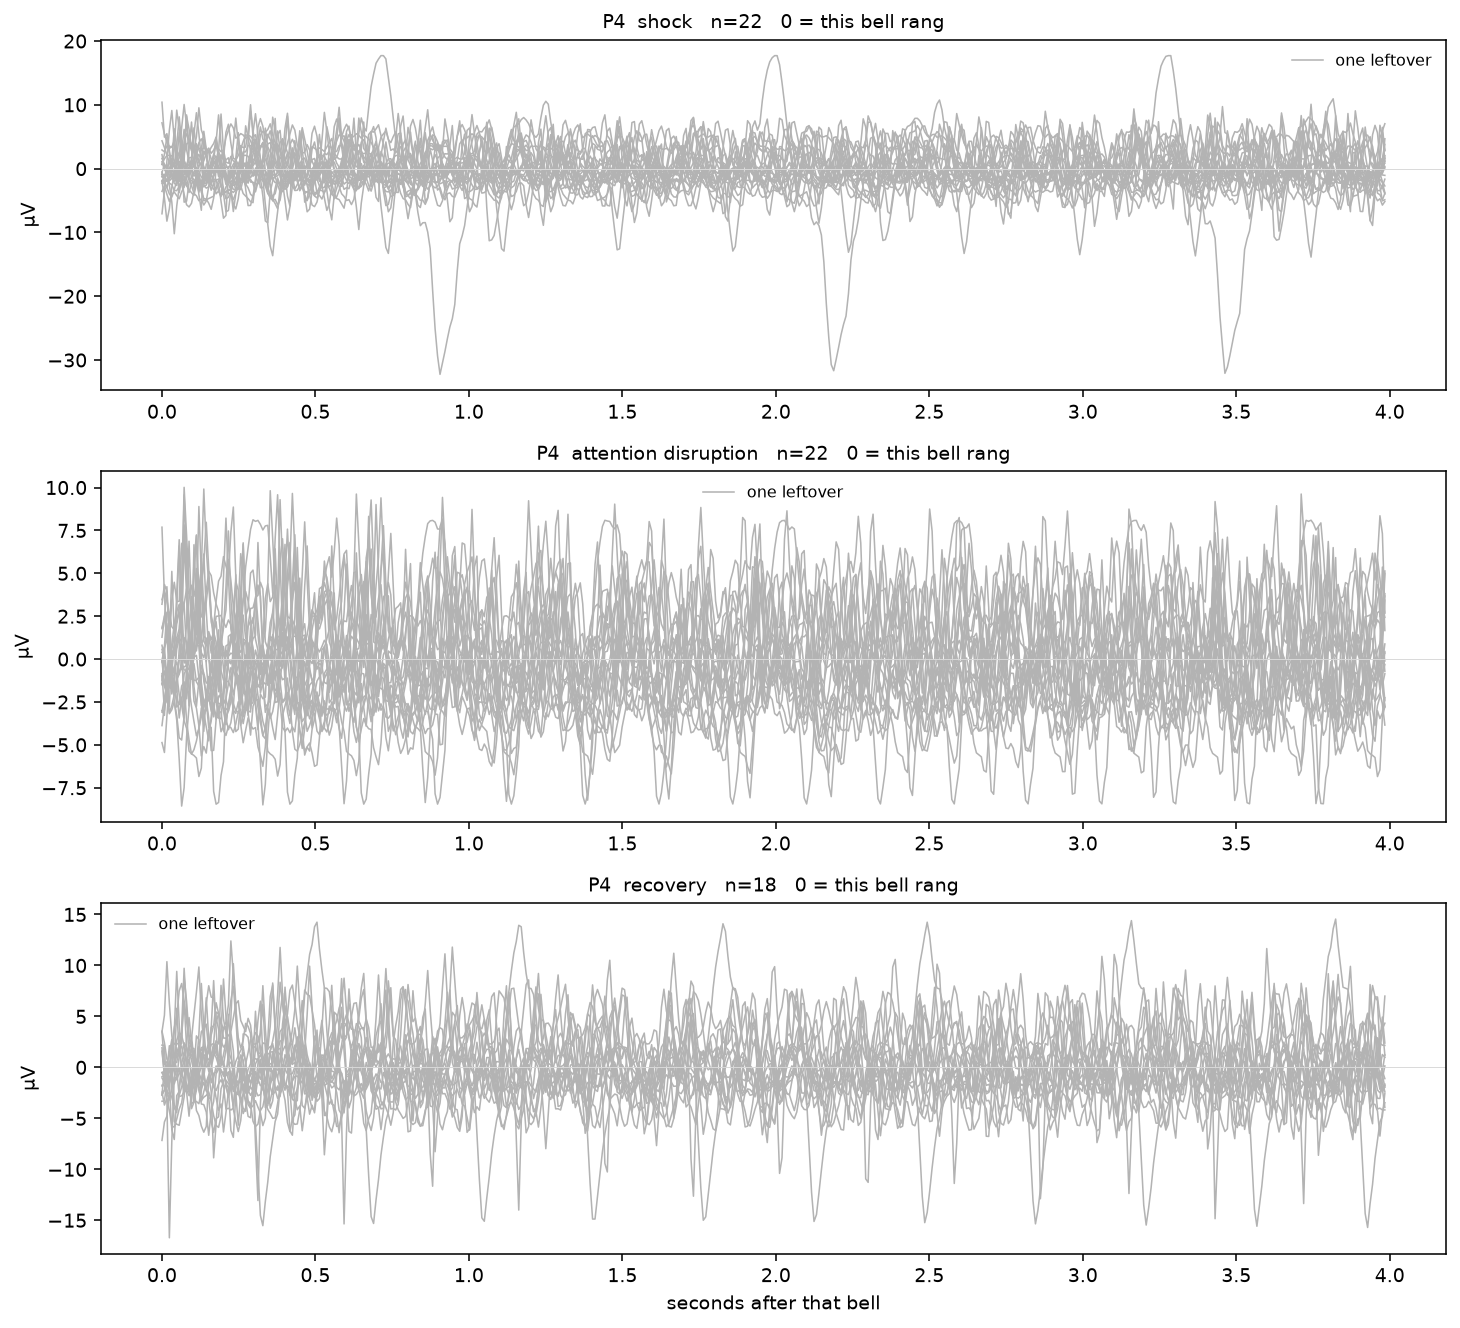

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set3/P4/collect_stack.png


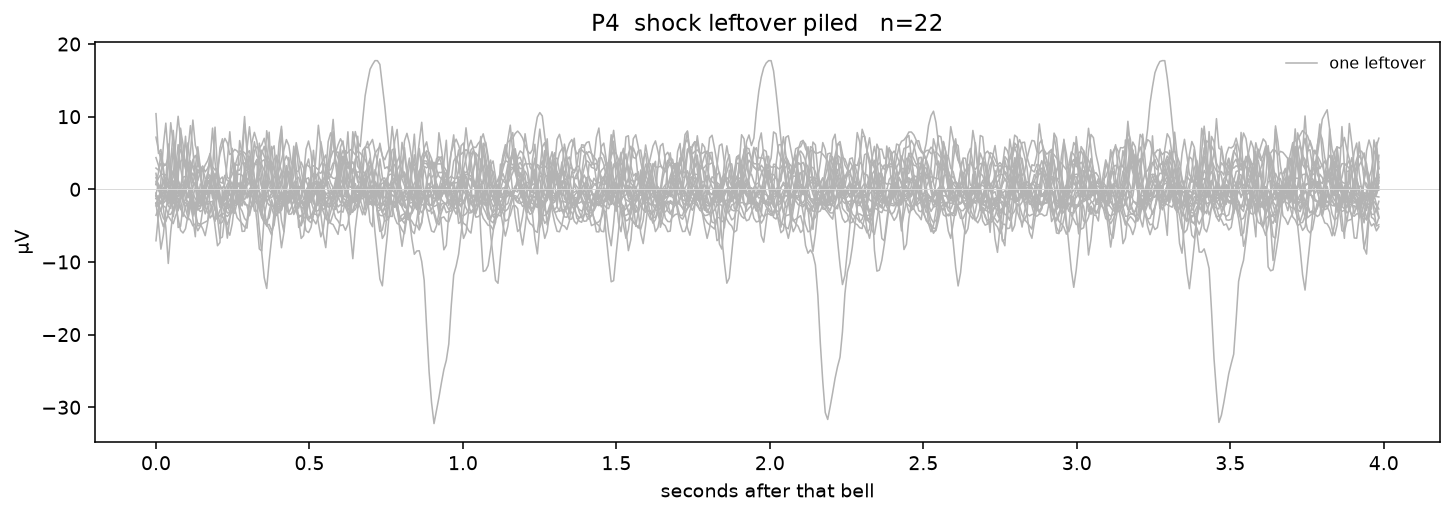

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set3/P4/collect_stack_shock.png


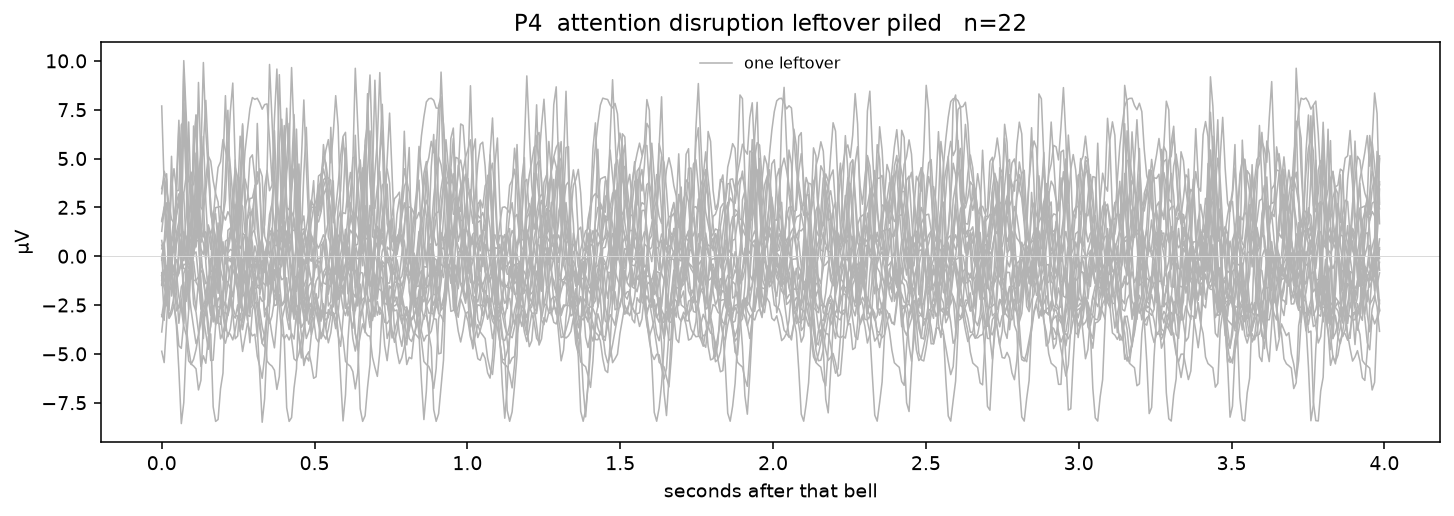

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set3/P4/collect_stack_disruption.png


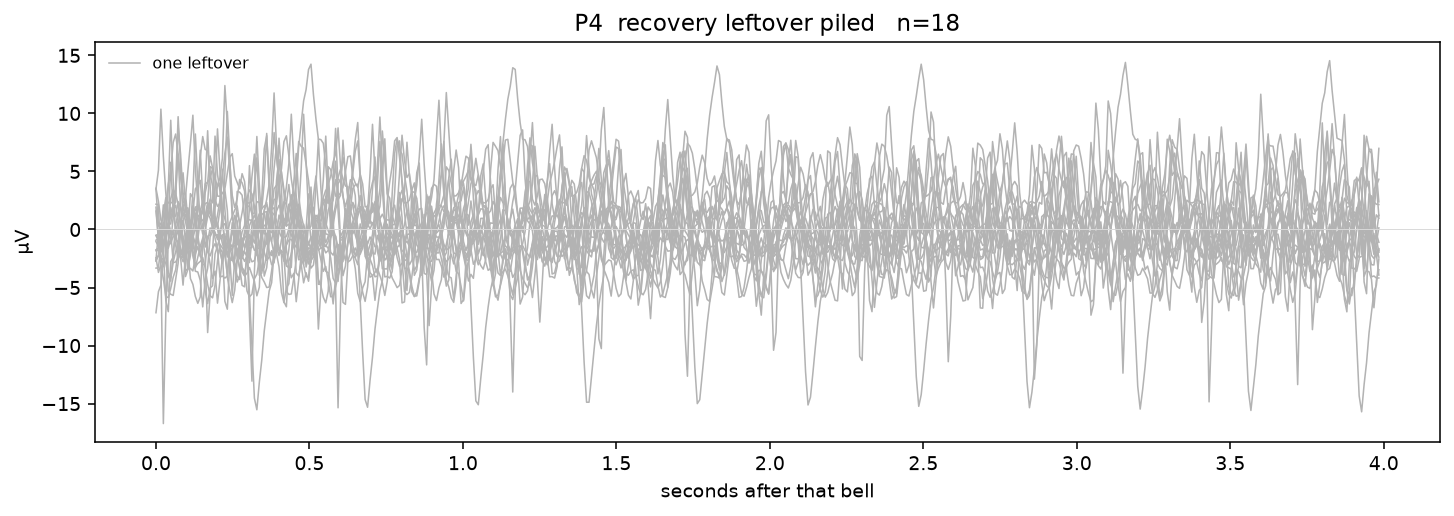

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set3/P4/collect_stack_recovery.png


In [179]:
# 8b — pile leftover by bell: shock (1), attention disruption (11), recovery (12)
# Time 0 = that bell rang. Leftover hills are NOT slid onto each other.
if not CLIP_LIST:
    raise RuntimeError("Run 8a first.")

MARK_WHAT = globals().get("MARK_WHAT") or {1: "shock", 11: "attention disruption", 12: "recovery"}
MARK_SLUG = {1: "shock", 11: "disruption", 12: "recovery"}


def _stack_group(clips, t):
    rows = []
    for c in clips:
        trel = np.asarray(c["tt"], float) - float(c["tt"][0])
        rows.append(np.interp(t, trel, np.asarray(c["y_fit"], float)))
    return np.vstack(rows)


dur = float(min(float(c["tt"][-1] - c["tt"][0]) for c in CLIP_LIST))
n_samp = max(8, int(dur * rec["fs"]))
STACK_T_SHARED = np.linspace(0.0, dur, n_samp, endpoint=False)

STACKS = {}
for code in (1, 11, 12):
    group = [c for c in CLIP_LIST if int(c.get("code") or 0) == code]
    print(f"  {MARK_WHAT.get(code, code)}: {len(group)} leftover clip(s)")
    if not group:
        continue
    fit = _stack_group(group, STACK_T_SHARED)
    STACKS[code] = dict(t=STACK_T_SHARED, fit=fit, what=MARK_WHAT[code], slug=MARK_SLUG[code])

if not STACKS:
    print("no shock / disruption / recovery timestamps — piling all leftover as reading")
    fit = _stack_group(CLIP_LIST, STACK_T_SHARED)
    STACKS[0] = dict(t=STACK_T_SHARED, fit=fit, what="reading", slug="reading")

# Later cells (8d/8e) use shock, because set 4 only has shock.
_use = 1 if 1 in STACKS else next(iter(STACKS))
STACK_T = STACKS[_use]["t"]
STACK_FIT = STACKS[_use]["fit"]
print(f"close-the-gap will use: {STACKS[_use]['what']}  n={len(STACK_FIT)}")

n_pan = len(STACKS)
fig, axes = plt.subplots(n_pan, 1, figsize=(10.5, 3.2 * n_pan), sharex=True, sharey=True)
axes = np.atleast_1d(axes)
_all = np.concatenate([S["fit"].ravel() for S in STACKS.values()])
_ylo, _yhi = float(np.nanmin(_all)), float(np.nanmax(_all))
_pad = 0.05 * (_yhi - _ylo + 1e-9)
for ax, code in zip(axes, STACKS):
    S = STACKS[code]
    for i, row in enumerate(S["fit"]):
        ax.plot(S["t"], row, color="0.7", lw=0.8, label="one leftover" if i == 0 else None)
    ax.axhline(0, color="0.85", lw=0.5)
    ax.set_xlim(0.0, float(S["t"][-1]))
    ax.set_ylim(_ylo - _pad, _yhi + _pad)
    ax.set_ylabel("µV")
    ax.set_title(f"{CHANNEL_LABELS[CH_ANN]}  {S['what']}   n={len(S['fit'])}   0 = marker", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
axes[-1].set_xlabel("seconds after the marker")
fig.tight_layout()
show_fig(fig, "collect_stack", rec["out_dir"])

for code, S in STACKS.items():
    fig, ax = plt.subplots(figsize=(10.5, 3.8))
    for i, row in enumerate(S["fit"]):
        ax.plot(S["t"], row, color="0.7", lw=0.8, label="one leftover" if i == 0 else None)
    ax.axhline(0, color="0.85", lw=0.5)
    ax.set_xlabel("seconds after that bell")
    ax.set_ylabel("µV")
    ax.set_title(f"{CHANNEL_LABELS[CH_ANN]}  {S['what']} leftover piled   n={len(S['fit'])}")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    show_fig(fig, f"collect_stack_{S['slug']}", rec["out_dir"])
    plot_dir = Path(rec["out_dir"]) / "plots"
    plot_dir.mkdir(parents=True, exist_ok=True)
    src = Path(rec["out_dir"]) / f"collect_stack_{S['slug']}.png"
    if src.exists():
        shutil.copy2(src, plot_dir / src.name)


In [180]:
# Extra 1 — after the grey pile: keep leftover hills, do not average them.
# Only leftover with R² ≥ 0.5. 0.2 s leftover bump and 0.8 s leftover bump both stay.
MIN_R2 = 0.5

def _r2(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    tot = float(np.sum((x - x.mean()) ** 2))
    return float(1 - np.sum((x - y) ** 2) / tot) if tot > 0 and len(x) >= 8 else np.nan

if not CLIP_LIST:
    raise RuntimeError("Run 8a then 8b first.")

GOOD = []
for c in CLIP_LIST:
    r2 = _r2(c["x"], c["y_fit"])
    row = dict(c, r2=r2)
    if np.isfinite(r2) and r2 >= MIN_R2:
        GOOD.append(row)
print(f"keep {len(GOOD)} / {len(CLIP_LIST)} leftover clips  (R² ≥ {MIN_R2})")

MARK_WHAT = globals().get("MARK_WHAT") or {1: "shock", 11: "attention disruption", 12: "recovery"}
panels = []
for code in (1, 11, 12, 0):
    g = [c for c in GOOD if int(c.get("code") or 0) == code]
    print(f"  {MARK_WHAT.get(code, code)}: {len(g)}")
    if g:
        panels.append((code, g))
if not panels:
    print("no leftover passed R². look at single clips, or lower MIN_R2.")
else:
    fig, axes = plt.subplots(len(panels), 1, figsize=(10.5, 3.0 * len(panels)))
    axes = np.atleast_1d(axes)
    for ax, (code, g) in zip(axes, panels):
        for c in g:
            trel = np.asarray(c["tt"], float) - float(c["tt"][0])
            ax.plot(trel, c["y_fit"], color="0.55", lw=0.8)
        ax.axhline(0, color="0.85", lw=0.5)
        ax.set_ylabel("µV")
        ax.set_title(f"{CHANNEL_LABELS[CH_ANN]}  {MARK_WHAT.get(code)}  leftover hills kept  n={len(g)}  no average")
    axes[-1].set_xlabel("seconds after the marker")
    fig.tight_layout()
    show_fig(fig, "collect_union_good_r2", rec["out_dir"])

keep 0 / 62 leftover clips  (R² ≥ 0.5)
  shock: 0
  attention disruption: 0
  recovery: 0
  reading: 0
no leftover passed R². look at single clips, or lower MIN_R2.


shock: n=22  leftover mean peak 2 µV  trough -2 µV
attention disruption: n=22  leftover mean peak 2 µV  trough -2 µV
recovery: n=18  leftover mean peak 2 µV  trough -2 µV


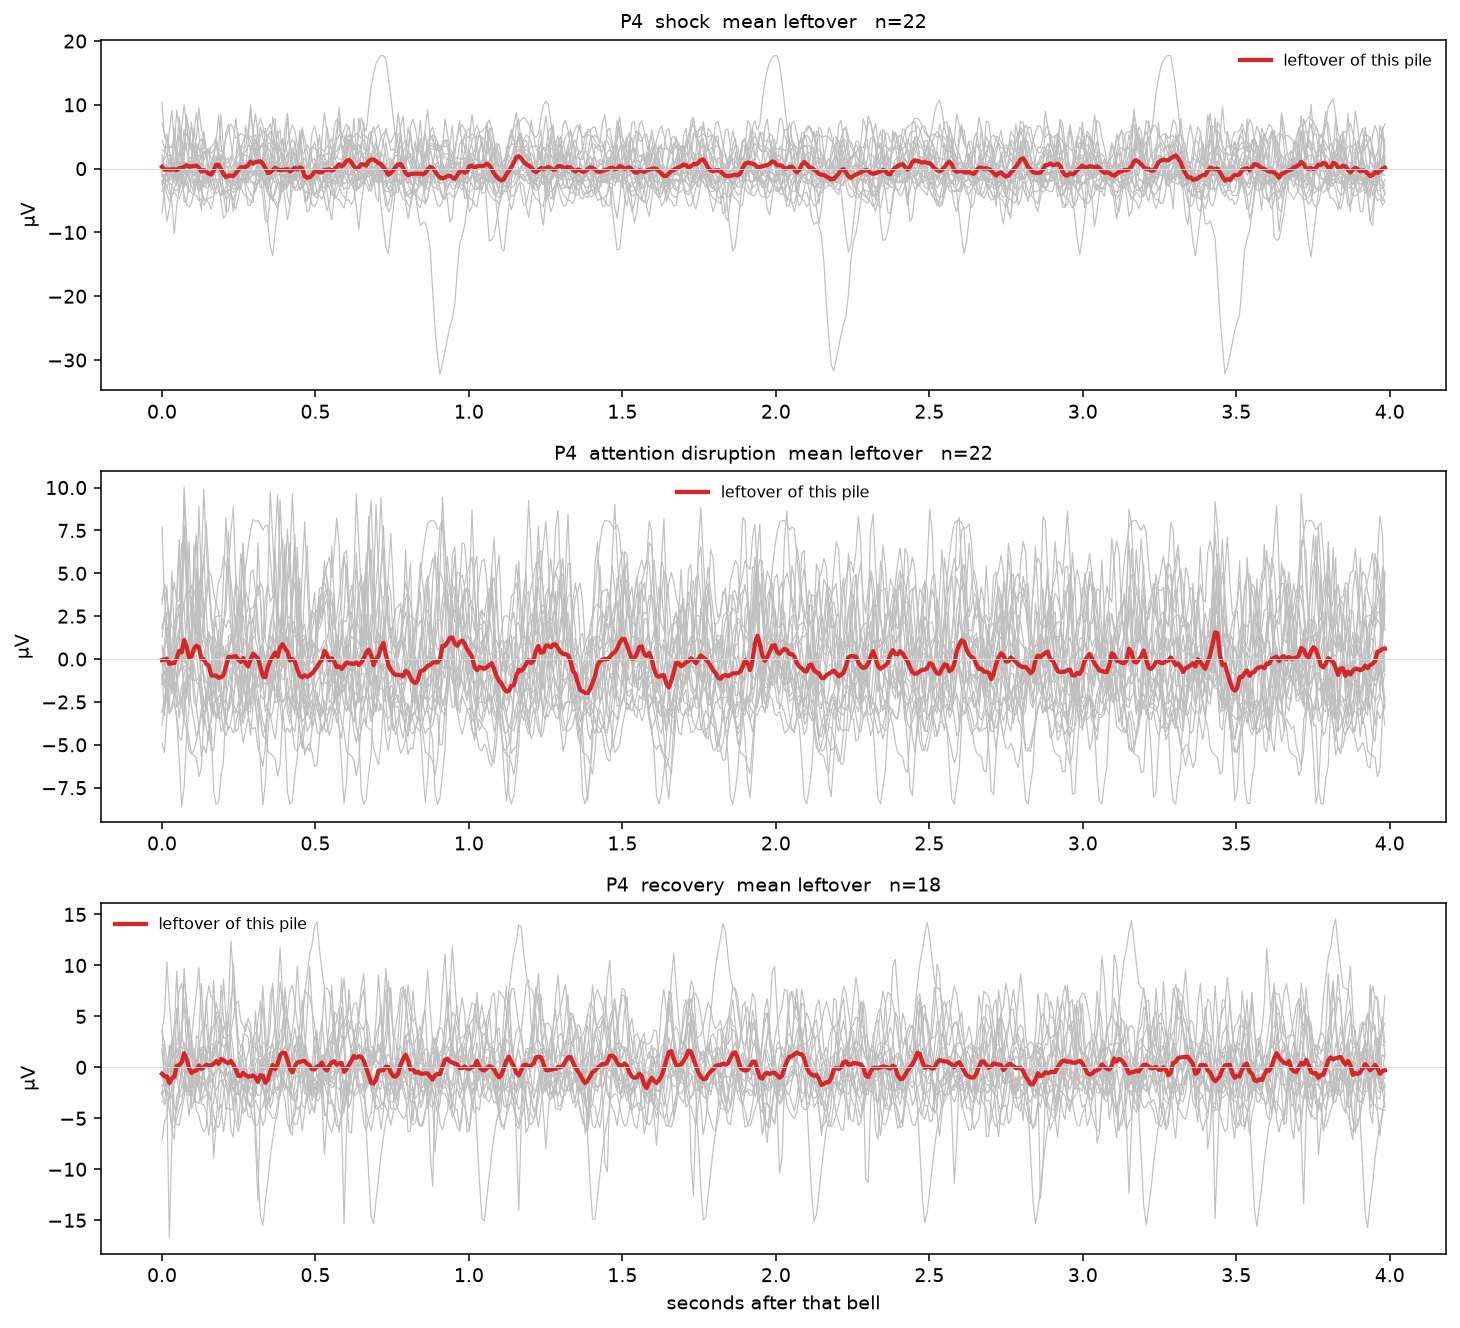

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set3/P4/collect_stack_mean.png


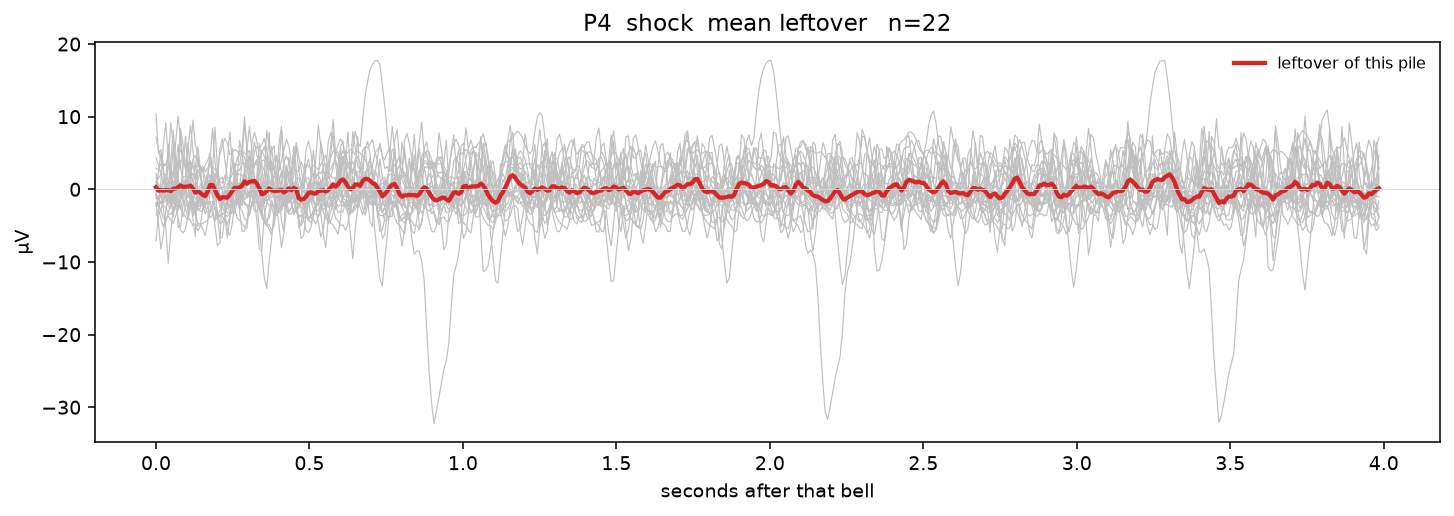

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set3/P4/collect_stack_mean_shock.png


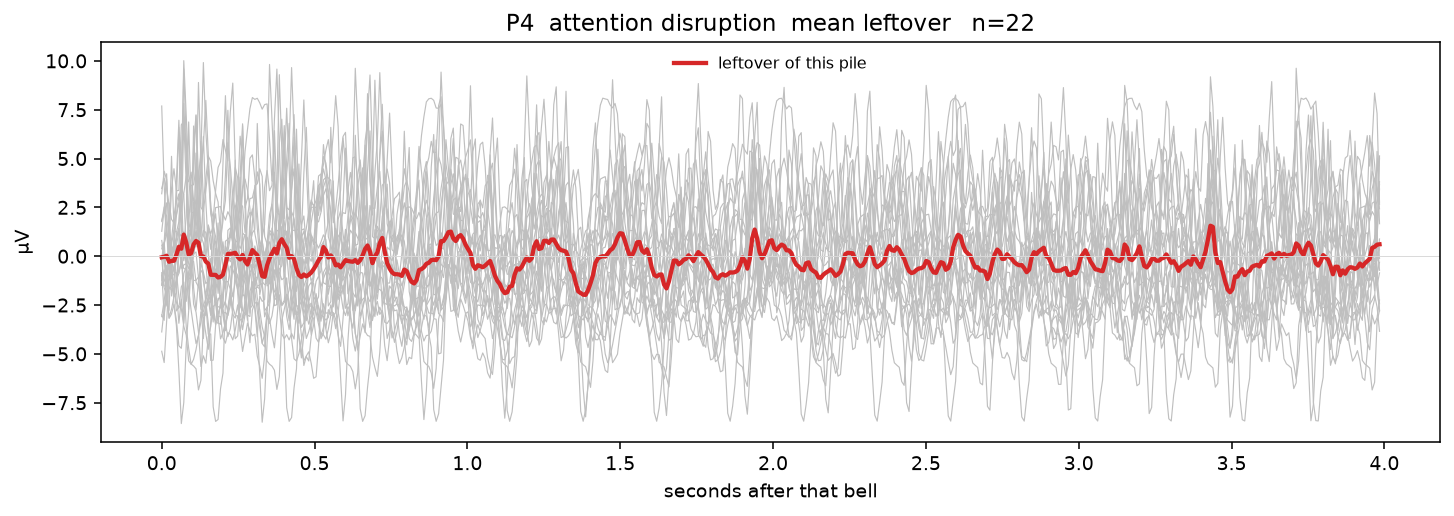

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set3/P4/collect_stack_mean_disruption.png


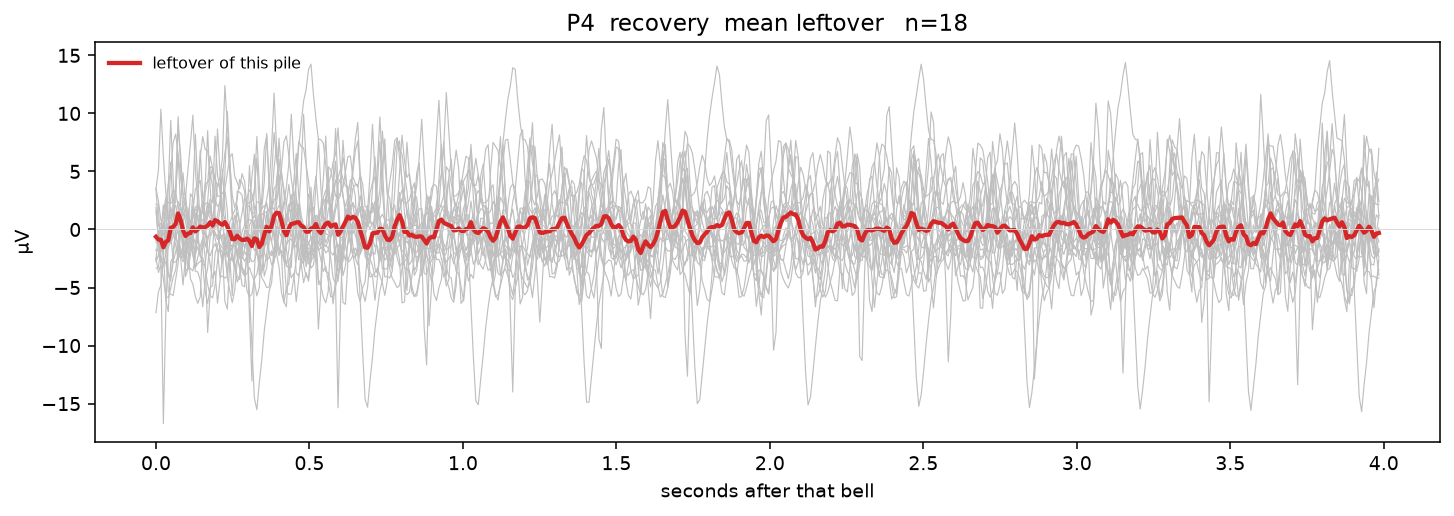

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set3/P4/collect_stack_mean_recovery.png
saved mean leftover for: shock, attention disruption, recovery


In [181]:
# 8c — one leftover wave per marker (mean of that pile)
if "STACKS" not in globals() or not STACKS:
    raise RuntimeError("Run 8b first.")

STACK_MEANS = {}
n_pan = len(STACKS)
fig, axes = plt.subplots(n_pan, 1, figsize=(10.5, 3.2 * n_pan), sharex=True, sharey=True)
axes = np.atleast_1d(axes)
_all = np.concatenate([S["fit"].ravel() for S in STACKS.values()])
_ylo, _yhi = float(np.nanmin(_all)), float(np.nanmax(_all))
_pad = 0.05 * (_yhi - _ylo + 1e-9)
_xmax = max(float(S["t"][-1]) for S in STACKS.values())
for ax, code in zip(axes, STACKS):
    S = STACKS[code]
    mean = S["fit"].mean(axis=0)
    STACK_MEANS[code] = mean
    print(f"{S['what']}: n={len(S['fit'])}  leftover mean peak {np.max(mean):.0f} µV  trough {np.min(mean):.0f} µV")
    for row in S["fit"]:
        ax.plot(S["t"], row, color="0.75", lw=0.6)
    ax.plot(S["t"], mean, color="C3", lw=2.2, label="leftover of this pile")
    ax.axhline(0, color="0.85", lw=0.5)
    ax.set_xlim(0.0, _xmax)
    ax.set_ylim(_ylo - _pad, _yhi + _pad)
    ax.set_xticks(np.arange(0.0, _xmax + 1e-9, 0.5))
    ax.set_ylabel("µV")
    ax.set_title(f"{CHANNEL_LABELS[CH_ANN]}  {S['what']}  mean leftover   n={len(S['fit'])}", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
axes[-1].set_xlabel("seconds after the marker")
fig.tight_layout()
show_fig(fig, "collect_stack_mean", rec["out_dir"])

for code, S in STACKS.items():
    mean = STACK_MEANS[code]
    fig, ax = plt.subplots(figsize=(10.5, 3.8))
    for row in S["fit"]:
        ax.plot(S["t"], row, color="0.75", lw=0.6)
    ax.plot(S["t"], mean, color="C3", lw=2.2, label="leftover of this pile")
    ax.axhline(0, color="0.85", lw=0.5)
    ax.set_xlim(0.0, _xmax)
    ax.set_ylim(_ylo - _pad, _yhi + _pad)
    ax.set_xticks(np.arange(0.0, _xmax + 1e-9, 0.5))
    ax.set_xlabel("seconds after the marker")
    ax.set_ylabel("µV")
    ax.set_title(f"{CHANNEL_LABELS[CH_ANN]}  {S['what']}  mean leftover   n={len(S['fit'])}")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    show_fig(fig, f"collect_stack_mean_{S['slug']}", rec["out_dir"])
    np.savetxt(rec["out_dir"] / f"collect_stack_mean_{S['slug']}.csv",
               np.column_stack([S["t"], mean]), delimiter=",", header="t_s,uV", comments="")
    plot_dir = Path(rec["out_dir"]) / "plots"
    src = Path(rec["out_dir"]) / f"collect_stack_mean_{S['slug']}.png"
    if src.exists():
        shutil.copy2(src, plot_dir / src.name)

# shock pile is what 8d/8e deform (set 4 only has shock)
_use = 1 if 1 in STACKS else next(iter(STACKS))
STACK_T = STACKS[_use]["t"]
STACK_FIT = STACKS[_use]["fit"]
STACK_MEAN = STACK_MEANS[_use]
print(f"saved mean leftover for: {', '.join(S['what'] for S in STACKS.values())}")


LOO  n=22  median r=0.02  min -0.11  max 0.10
Each point is one hidden clip vs the leftover built from the other clips.
split  train 15 / test 7  (seed 0, hold 30%)
  in-sample  median r=0.18
  held-out   median r=0.01
  train−test gap 0.17   (large gap = overfitting the stacked mean)


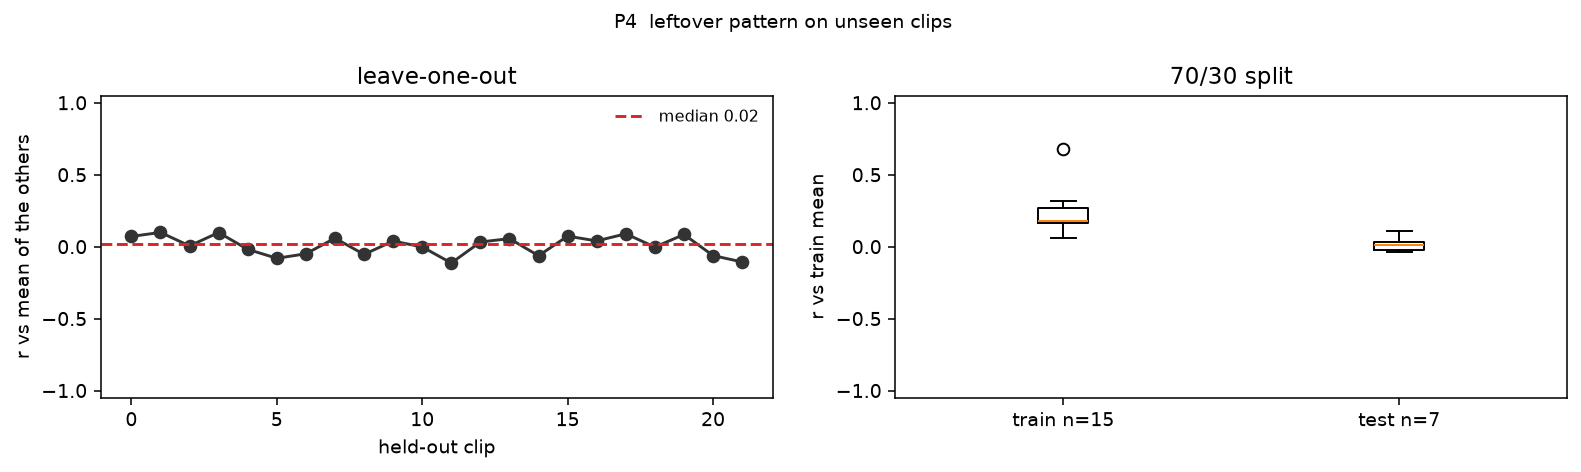

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/raw_signals/Soni/set3/P4/collect_leftover_loo_split.png


In [182]:
# 8c2 — does the stacked leftover overfit? LOO + a 70/30 split
# Hide some clips, build the mean leftover from the rest, score the hidden ones.
# High held-out r = leftover repeats. A big drop vs in-sample r = the mean was memorizing those clips.
if "STACK_FIT" not in globals():
    raise RuntimeError("Run 8b (stack) first.")

HOLD_FRAC = 0.30
SPLIT_SEED = 0


def _clip_r(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    if m.sum() < 8 or np.std(a[m]) < 1e-9 or np.std(b[m]) < 1e-9:
        return np.nan
    return float(np.corrcoef(a[m], b[m])[0, 1])


n = len(STACK_FIT)
if n < 4:
    raise RuntimeError(f"Need at least 4 stored clips for a split (have {n}). Run G-batch.")

# Leave-one-out: mean of everyone except i vs clip i
loo_r = np.array([
    _clip_r(STACK_FIT[i], np.delete(STACK_FIT, i, 0).mean(0))
    for i in range(n)
], dtype=float)
print(f"LOO  n={n}  median r={np.nanmedian(loo_r):.2f}  "
      f"min {np.nanmin(loo_r):.2f}  max {np.nanmax(loo_r):.2f}")
print("Each point is one hidden clip vs the leftover built from the other clips.")

# Hold-out split: one reproducible 70/30. Train mean vs train clips (in-sample) and vs test clips.
rng = np.random.default_rng(SPLIT_SEED)
idx = rng.permutation(n)
n_test = max(1, int(round(n * HOLD_FRAC)))
test_i, train_i = idx[:n_test], idx[n_test:]
mean_train = STACK_FIT[train_i].mean(0)
r_train = np.array([_clip_r(STACK_FIT[i], mean_train) for i in train_i], dtype=float)
r_test = np.array([_clip_r(STACK_FIT[i], mean_train) for i in test_i], dtype=float)
print(f"split  train {len(train_i)} / test {len(test_i)}  (seed {SPLIT_SEED}, hold {HOLD_FRAC:.0%})")
print(f"  in-sample  median r={np.nanmedian(r_train):.2f}")
print(f"  held-out   median r={np.nanmedian(r_test):.2f}")
if np.isfinite(np.nanmedian(r_train)) and np.isfinite(np.nanmedian(r_test)):
    gap = float(np.nanmedian(r_train) - np.nanmedian(r_test))
    print(f"  train−test gap {gap:.2f}   (large gap = overfitting the stacked mean)")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4))
axes[0].plot(np.arange(n), loo_r, "o-", color="0.2")
axes[0].axhline(np.nanmedian(loo_r), color="C3", ls="--",
                label=f"median {np.nanmedian(loo_r):.2f}")
axes[0].set_ylim(-1.05, 1.05)
axes[0].set_xlabel("held-out clip")
axes[0].set_ylabel("r vs mean of the others")
axes[0].set_title("leave-one-out")
axes[0].legend(frameon=False, fontsize=8)
axes[1].boxplot([r_train, r_test])
axes[1].set_xticklabels([f"train n={len(train_i)}", f"test n={len(test_i)}"])
axes[1].set_ylim(-1.05, 1.05)
axes[1].set_ylabel("r vs train mean")
axes[1].set_title("70/30 split")
fig.suptitle(f"{CHANNEL_LABELS[CH_ANN]}  leftover pattern on unseen clips", fontsize=10)
fig.tight_layout()
show_fig(fig, "collect_leftover_loo_split", rec["out_dir"])

In [ ]:
# 8d — load the baseline stack already stored for this channel (set 1 folder)
if "STACK_MEAN" not in globals():
    raise RuntimeError("Run 8c first.")

d_b, clips_b = load_fitted_clips(set_id=1, ch=CH_ANN)
print(f"baseline folder  {fitted_clips_dir(1, CH_ANN)}")
print(f"{len(clips_b)} fitted baseline segment(s)")
if len(clips_b) < 2:
    raise RuntimeError("Run Meeting G + rough pattern on set 1 (same VIEW_CH) until at least 2 clips are stored.")

n_use = min(len(STACK_FIT), len(clips_b))
print(f"using n={n_use} on each side (time order)")

rows_b = []
for c in clips_b[:n_use]:
    trel = np.asarray(c["tt"], float) - float(c["tt"][0])
    rows_b.append(np.interp(STACK_T, trel, np.asarray(c["y_fit"], float)))
STACK_FIT_B = np.vstack(rows_b)
STACK_MEAN_B = STACK_FIT_B.mean(axis=0)
STACK_FIT_D = STACK_FIT[:n_use]
STACK_MEAN_D = STACK_FIT_D.mean(axis=0)

fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.plot(STACK_T, STACK_MEAN_B, color="0.4", lw=1.8, label=f"baseline mean  n={n_use}")
ax.plot(STACK_T, STACK_MEAN_D, color="C3", lw=1.8, label=f"distract mean  n={n_use}")
ax.plot(STACK_T, STACK_MEAN_D - STACK_MEAN_B, color="0.15", lw=1.0, ls=":", label="delta")
ax.axhline(0, color="0.85", lw=0.5)
ax.set_xlabel("seconds from clip start")
ax.set_ylabel("µV")
ax.set_title(f"{CHANNEL_LABELS[CH_ANN]}  stacked leftover: baseline vs this set")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
show_fig(fig, "collect_vs_baseline", rec["out_dir"])


In [ ]:
# 8e — shift + scale + offset to close the gap; LOO checks unseen clips
if "STACK_MEAN_B" not in globals():
    raise RuntimeError("Run 8d first (baseline compare).")


def _shift(y, lag):
    out = np.full_like(y, np.nan, dtype=float)
    if lag == 0:
        return np.asarray(y, float).copy()
    if lag > 0:
        out[lag:] = y[:-lag]
    else:
        out[:lag] = y[-lag:]
    return out


def _rmse(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.sqrt(np.mean((a[m] - b[m]) ** 2))) if m.any() else np.nan


def _r(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    if m.sum() < 8 or np.std(a[m]) < 1e-9 or np.std(b[m]) < 1e-9:
        return np.nan
    return float(np.corrcoef(a[m], b[m])[0, 1])


def _map_together(y_from, y_to, fs, max_lag_s=1.0):
    max_lag = int(max_lag_s * fs)
    c = np.correlate(y_to - np.mean(y_to), y_from - np.mean(y_from), mode="full")
    lags = np.arange(-len(y_from) + 1, len(y_to))
    inner = np.abs(lags) <= max_lag
    lag = int(lags[inner][np.argmax(c[inner])]) if inner.any() else 0
    y_s = _shift(y_from, lag)
    ok = np.isfinite(y_s) & np.isfinite(y_to)
    coef, *_ = np.linalg.lstsq(np.column_stack([y_s[ok], np.ones(ok.sum())]), y_to[ok], rcond=None)
    a, b = float(coef[0]), float(coef[1])
    return lag, a, b, a * y_s + b


fs = rec["fs"]
lag, a_map, b_map, y_hat = _map_together(STACK_MEAN_B, STACK_MEAN_D, fs)
print(f"in-sample  y_distract ≈ {a_map:.2f}·shift(y_baseline) + {b_map:.1f}")
print(f"  lag {lag / fs * 1000:.0f} ms   RMSE {_rmse(STACK_MEAN_D, STACK_MEAN_B):.1f} → {_rmse(STACK_MEAN_D, y_hat):.1f} µV   "
      f"r {_r(STACK_MEAN_D, STACK_MEAN_B):.2f} → {_r(STACK_MEAN_D, y_hat):.2f}")

# LOO: fit the map without clip i, score it on that clip (has the function seen this leftover?)
loo_r, loo_rmse = [], []
n = len(STACK_FIT_D)
for i in range(n):
    mu_d = np.delete(STACK_FIT_D, i, 0).mean(0)
    lag_i, a_i, b_i, _ = _map_together(STACK_MEAN_B, mu_d, fs)
    y_i = a_i * _shift(STACK_MEAN_B, lag_i) + b_i
    loo_r.append(_r(STACK_FIT_D[i], y_i))
    loo_rmse.append(_rmse(STACK_FIT_D[i], y_i))
print(f"LOO held-out clips  median r={np.nanmedian(loo_r):.2f}   median RMSE={np.nanmedian(loo_rmse):.1f} µV")
print("If LOO r is much worse than in-sample r, the map is overfitting the stacked mean.")
print("This only lines leftover fits up. It is not a brain inverse.")

fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.plot(STACK_T, STACK_MEAN_D, color="C3", lw=1.7, label="distract stack mean")
ax.plot(STACK_T, STACK_MEAN_B, color="0.55", lw=1.2, label="baseline stack mean")
ax.plot(STACK_T, y_hat, color="0.1", lw=1.7, label=f"mapped baseline  ({a_map:.2f}·shift + {b_map:.1f})")
ax.axhline(0, color="0.85", lw=0.5)
ax.set_xlabel("seconds from clip start")
ax.set_ylabel("µV")
ax.set_title(f"{CHANNEL_LABELS[CH_ANN]}  close the gap")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
show_fig(fig, "collect_close_gap", rec["out_dir"])

fig, ax = plt.subplots(figsize=(10.5, 3.2))
ax.plot(np.arange(n), loo_r, "o-", color="0.2", label="LOO r on held-out clip")
ax.axhline(_r(STACK_MEAN_D, y_hat), color="C3", ls="--", label=f"in-sample r={_r(STACK_MEAN_D, y_hat):.2f}")
ax.set_ylim(-1.05, 1.05)
ax.set_xlabel("held-out clip")
ax.set_ylabel("r")
ax.set_title("does the map work on a leftover fit it has not seen?")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
show_fig(fig, "collect_loo_heldout", rec["out_dir"])


In [183]:
# Extra 2 — leftover numbers only (no new leftover wave). Phone leftover vs reading leftover.
def _r2(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    tot = float(np.sum((x - x.mean()) ** 2))
    return float(1 - np.sum((x - y) ** 2) / tot) if tot > 0 and len(x) >= 8 else np.nan

def _leftover_row(c, where):
    y = np.asarray(c["y_fit"], float)
    T = float(c["T"])
    r2 = c.get("r2", _r2(c["x"], c["y_fit"]))
    return dict(where=where, what=c.get("what", "reading"), t_s=round(float(c["start"]), 1),
                Hz=(1.0 / T if T else np.nan), bump_uV=float(np.nanmax(y)),
                trough_uV=float(np.nanmin(y)), drop_uV=float(np.nanmax(y) - np.nanmin(y)), r2=r2)

use = [c for c in (globals().get("GOOD") or CLIP_LIST) ]
rows = [_leftover_row(c, "phone") for c in use]
_, base = load_fitted_clips(set_id=1, ch=CH_ANN)
rows += [_leftover_row(dict(c, what="reading"), "reading") for c in base]
tab = pd.DataFrame(rows)
print("median leftover numbers")
print(tab.groupby(["where", "what"])[["Hz", "bump_uV", "trough_uV", "drop_uV", "r2"]].median().round(2))
phone = tab[tab["where"] == "phone"]
if len(phone):
    bins = np.arange(np.floor(phone["bump_uV"].min()), np.ceil(phone["bump_uV"].max()) + 2, 2)
    counts, edges = np.histogram(phone["bump_uV"], bins=bins)
    i = int(np.argmax(counts))
    print(f"most common leftover bump on phone: {edges[i]:.0f}–{edges[i+1]:.0f} µV  ({int(counts[i])} clips)")
read = tab[tab["where"] == "reading"]
if len(phone) and len(read):
    print(f"reading leftover bump median {read['bump_uV'].median():.0f} µV   phone {phone['bump_uV'].median():.0f} µV")
    print("that gap is leftover change. this cell does not draw a leftover wave from the numbers.")
display(tab.round(2))

median leftover numbers
                                Hz  bump_uV  trough_uV  drop_uV    r2
where   what                                                         
phone   attention disruption  3.60     7.52      -4.27    12.87 -0.17
        recovery              3.82     8.63      -5.90    14.79 -0.10
        shock                 3.68     7.79      -4.50    12.30 -0.13
reading reading               3.97     7.84      -4.57    12.08 -0.12
most common leftover bump on phone: 8–10 µV  (23 clips)
reading leftover bump median 8 µV   phone 8 µV
that gap is leftover change. this cell does not draw a leftover wave from the numbers.


,where,what,t_s,Hz,bump_uV,trough_uV,drop_uV,r2
0,phone,shock,0.9,3.38,4.69,-4.00,8.69,-0.19
1,phone,attention disruption,9.5,2.98,7.88,-5.66,13.54,-0.20
2,phone,shock,311.7,3.79,6.83,-3.71,10.54,-0.13
3,phone,attention disruption,320.6,3.79,6.76,-8.59,15.35,-0.22
4,phone,recovery,325.1,2.60,6.66,-5.70,12.36,0.06
...,...,...,...,...,...,...,...,...
372,reading,reading,3550.0,3.57,7.66,-8.26,15.92,-0.17
373,reading,reading,3560.0,3.57,4.66,-4.41,9.07,-0.13
374,reading,reading,3570.0,4.81,8.77,-4.06,12.83,-0.08
375,reading,reading,3580.0,1.79,5.51,-7.68,13.19,-0.04


In [ ]:
# Meeting H — same 4 trials: 8 s of READING (just before text) vs 8 s ON THE PHONE
# Not a separate baseline file. Left = the same trial, before marker 1.
N_CLIPS = 4
CLIP_S = 8.0
CH_CLIPS = CH_ANN

def complete_trials(rec):
    ev = marker_times_s(rec)
    ones = [t for t, v in ev if v == 1]
    elevens = [t for t, v in ev if v == 11]
    twelves = [t for t, v in ev if v == 12]
    out, used11, used12 = [], set(), set()
    for t1 in ones:
        t11s = [t for t in elevens if t > t1 and t not in used11]
        if not t11s:
            continue
        t11 = t11s[0]
        t12s = [t for t in twelves if t > t11 and t not in used12]
        if not t12s:
            continue
        t12 = t12s[0]
        out.append((t1, t11, t12))
        used11.add(t11); used12.add(t12)
    return out

def has_samples(t0, t1, ch):
    return window_ok(X_CLEAN[:, ch], t0, t1)

trials = []
for t1, t11, t12 in complete_trials(rec):
    if has_samples(t1 - CLIP_S, t1, CH_CLIPS) and has_samples(t11, min(t11 + CLIP_S, t12), CH_CLIPS):
        trials.append((t1, t11, t12))
print(f"{len(complete_trials(rec))} complete 1→11→12 trials; {len(trials)} have clean reading+phone clips")
for i, (t1, t11, t12) in enumerate(trials[:N_CLIPS], 1):
    print(f"  {i}. read {t1-CLIP_S:.0f}→{t1:.0f}s   phone {t11:.0f}→{min(t11+CLIP_S,t12):.0f}s")

show = trials[:N_CLIPS]
n_row = max(len(show), 1)
fig, axes = plt.subplots(n_row, 2, figsize=(13, 2.2 * n_row), sharex=False, sharey="row")
if n_row == 1:
    axes = np.array([axes])
for r, (t1, t11, t12) in enumerate(show):
    ax_q, ax_a = axes[r, 0], axes[r, 1]
    _, xq = rec_slice(X_CLEAN[:, CH_CLIPS], t1 - CLIP_S, t1)
    t_end = min(t11 + CLIP_S, t12)
    _, xa = rec_slice(X_CLEAN[:, CH_CLIPS], t11, t_end)
    tq = np.arange(len(xq)) / rec["fs"]
    ta = np.arange(len(xa)) / rec["fs"]
    ax_q.plot(tq, xq, color="0.2", lw=0.9)
    ax_a.plot(ta, xa, color="C0", lw=0.9)
    ax_a.axvline(0, color="C2", lw=0.8, ls="--")
    ax_q.set_ylabel(CHANNEL_LABELS[CH_CLIPS], fontsize=8)
    ax_q.text(0.02, 0.9, f"reading  RMS {np.sqrt(np.nanmean(xq**2)):.1f} µV",
              transform=ax_q.transAxes, fontsize=8, va="top")
    ax_a.text(0.02, 0.9, f"on phone  RMS {np.sqrt(np.nanmean(xa**2)):.1f} µV",
              transform=ax_a.transAxes, fontsize=8, va="top", color="C0")
    ax_q.set_xlim(0, CLIP_S); ax_a.set_xlim(0, CLIP_S)
if len(show):
    axes[0, 0].set_title("reading (8 s before text arrived)")
    axes[0, 1].set_title("on phone (8 s after pickup)  — same y-scale as the left")
    axes[-1, 0].set_xlabel("s from start of this 8 s piece")
    axes[-1, 1].set_xlabel("s from pickup (11)")
fig.suptitle(f"{rec['id']}  {CHANNEL_LABELS[CH_CLIPS]}  {CLEAN_NAME}   same trials, reading vs phone", fontsize=10)
fig.tight_layout()
show_fig(fig, "meeting_four_pickups", rec["out_dir"])


In [ ]:
# Meeting I — event-locked overlay (ERP-style, n = number of events that fit)
PRE_S, POST_S = 0.5, 2.0


def lock_events(x_1d, times, pre=PRE_S, post=POST_S):
    t = session_time_min(rec) * 60.0
    n = int((pre + post) * rec["fs"])
    tt = np.arange(n) / rec["fs"] - pre
    snaps = []
    for t_ev in times:
        m = (t >= t_ev - pre) & (t < t_ev + post) & np.isfinite(x_1d)
        ep = x_1d[m]
        if len(ep) < n * 0.9:
            continue
        ep = ep[:n]
        npre = int(pre * rec["fs"])
        snaps.append(ep - np.mean(ep[:npre]))
    if not snaps:
        return tt, np.empty((0, n))
    L = min(len(s) for s in snaps)
    return tt[:L], np.vstack([s[:L] for s in snaps])


ev = marker_times_s(rec)
t_ping = [t for t, v in ev if v == 1]
t_pick = [t for t, v in ev if v == 11]
x1 = X_CLEAN[:, CH_CLIPS]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, times, name in (
    (axes[0], t_ping, "text arrives (1)"),
    (axes[1], t_pick, "phone pickup (11)"),
):
    tt, snaps = lock_events(x1, times)
    if len(snaps) == 0:
        ax.set_title(f"{name}  — no events in range")
        continue
    for s in snaps:
        ax.plot(tt, s, color="0.75", lw=0.7)
    ax.plot(tt, np.mean(snaps, axis=0), color="0.1", lw=2.0, label=f"mean n={len(snaps)}")
    ax.axvline(0, color="C3", lw=0.9, ls="--")
    ax.axvspan(-PRE_S, 0, color="0.9", zorder=0)
    # literature latency windows (not detections)
    ax.axvspan(0.25, 0.40, color="C1", alpha=0.18, zorder=0)
    ax.axvspan(0.30, 0.50, color="C4", alpha=0.12, zorder=0)
    ax.set_title(f"{name}   n={len(snaps)}")
    ax.set_xlabel("s from event (0 = marker)")
    ax.legend(fontsize=8, frameon=False, loc="upper right")
axes[0].axvspan(0.25, 0.40, color="C1", alpha=0.18, label="P300 window ~250–400 ms")
axes[0].axvspan(0.30, 0.50, color="C4", alpha=0.12, label="N400 window ~300–500 ms")
axes[0].legend(fontsize=7, frameon=False, loc="upper right")
axes[0].set_ylabel(f"{CHANNEL_LABELS[CH_CLIPS]}  µV\n(each event minus its own pre-event mean)")
fig.suptitle(f"{rec['id']}  event-locked  {CLEAN_NAME}   grey=one event, black=mean of n events", fontsize=10)
fig.tight_layout()
show_fig(fig, "meeting_event_locked", rec["out_dir"])
print("shaded = pre-event baseline. If grey traces do not stack, the mean is not a stable wave yet.")


In [ ]:
# Meeting J — one plot per trial: reading → text (1) → pickup (11) → put-down (12)
N_TRIALS = 4
PRE_READ_S = 8.0     # seconds of reading shown before the text arrives
POST_12_S = 3.0      # a little after put-down


def complete_trials(rec):
    """(t1, t11, t12) in recording seconds."""
    ev = marker_times_s(rec)
    ones = [t for t, v in ev if v == 1]
    elevens = [t for t, v in ev if v == 11]
    twelves = [t for t, v in ev if v == 12]
    out = []
    used11, used12 = set(), set()
    for t1 in ones:
        t11s = [t for t in elevens if t > t1 and t not in used11]
        if not t11s:
            continue
        t11 = t11s[0]
        t12s = [t for t in twelves if t > t11 and t not in used12]
        if not t12s:
            continue
        t12 = t12s[0]
        out.append((t1, t11, t12))
        used11.add(t11)
        used12.add(t12)
    return out

trials = complete_trials(rec)
print(f"{len(trials)} complete 1→11→12 trials")
for i, (t1, t11, t12) in enumerate(trials[:N_TRIALS], 1):
    print(f"  {i}. 1={t1:.0f}s  wait {t11-t1:.1f}s  on-phone {t12-t11:.1f}s  12={t12:.0f}s")

show = trials[:N_TRIALS]
if not show:
    print("No complete 1→11→12 trials in this file.")
else:
    n = len(show)
    fig, axes = plt.subplots(n, 1, figsize=(13, 2.4 * n), sharex=False)
    if n == 1:
        axes = [axes]
    for ax, (t1, t11, t12) in zip(axes, show):
        t0 = t1 - PRE_READ_S
        t1e = t12 + POST_12_S
        tt, x = rec_slice(X_CLEAN[:, CH_CLIPS], t0, t1e)
        # x-axis: seconds from text arriving, so 1 is at 0
        ax.plot(tt - t1, x, color="0.15", lw=0.8)
        ax.axvspan(-PRE_READ_S, 0, color="#eeeeee", zorder=0)          # reading
        ax.axvspan(0, t11 - t1, color="#fff3cd", zorder=0)             # after ping, before pickup
        ax.axvspan(t11 - t1, t12 - t1, color="#d6eaf8", zorder=0)      # on phone
        ax.axvline(0, color="C1", lw=1.3, ls="--")
        ax.axvline(t11 - t1, color="C2", lw=1.3, ls="--")
        ax.axvline(t12 - t1, color="C3", lw=1.3, ls="--")
        ymax = np.nanpercentile(np.abs(x), 99) if len(x) else 1
        ax.set_ylim(-max(25, 1.2 * ymax), max(25, 1.2 * ymax))
        ax.set_ylabel(CHANNEL_LABELS[CH_CLIPS], fontsize=8)
        ax.text(0.01, 0.92, "reading", transform=ax.transAxes, fontsize=8, color="0.35")
        ax.text((0 + (t11 - t1)) / 2 / (t1e - t0) * 0 + 0.02, 0.08,
                "", transform=ax.transAxes)
        ax.annotate("1 text", xy=(0, ax.get_ylim()[1] * 0.85), fontsize=8, color="C1", ha="left")
        ax.annotate("11 pickup", xy=(t11 - t1, ax.get_ylim()[1] * 0.55), fontsize=8, color="C2")
        ax.annotate("12 down", xy=(t12 - t1, ax.get_ylim()[1] * 0.85), fontsize=8, color="C3", ha="right")
        ax.set_xlim(-PRE_READ_S, (t12 - t1) + POST_12_S)
    axes[0].set_title("grey=reading   yellow=after text, before pickup   blue=on the phone")
    axes[-1].set_xlabel("seconds from text arriving (marker 1 at 0)")
    # legend
    handles = [
        plt.Line2D([0], [0], color="C1", ls="--", lw=1.3, label="1  text arrived"),
        plt.Line2D([0], [0], color="C2", ls="--", lw=1.3, label="11 picked up"),
        plt.Line2D([0], [0], color="C3", ls="--", lw=1.3, label="12 put down"),
    ]
    axes[0].legend(handles=handles, loc="upper right", fontsize=8, frameon=False)
    fig.suptitle(f"{rec['id']}  {CHANNEL_LABELS[CH_CLIPS]}  {CLEAN_NAME}   one full distraction each row", fontsize=10)
    fig.tight_layout()
    show_fig(fig, "meeting_full_trials", rec["out_dir"])

    # one larger single trial, easier to point at
    t1, t11, t12 = show[0]
    t0, t1e = t1 - PRE_READ_S, t12 + POST_12_S
    tt, x = rec_slice(X_CLEAN[:, CH_CLIPS], t0, t1e)
    fig, ax = plt.subplots(figsize=(13, 4.4))
    ax.plot(tt - t1, x, color="0.12", lw=0.9)
    ax.axvspan(-PRE_READ_S, 0, color="#eeeeee", zorder=0, label="reading")
    ax.axvspan(0, t11 - t1, color="#fff3cd", zorder=0, label="heard text, still reading")
    ax.axvspan(t11 - t1, t12 - t1, color="#d6eaf8", zorder=0, label="on the phone")
    ax.axvline(0, color="C1", lw=1.4, ls="--")
    ax.axvline(t11 - t1, color="C2", lw=1.4, ls="--")
    ax.axvline(t12 - t1, color="C3", lw=1.4, ls="--")
    # P300/N400 are ~0.3 s — a sliver after 1 and after 11
    ax.axvspan(0.25, 0.50, color="C1", alpha=0.35, zorder=1)
    ax.axvspan((t11 - t1) + 0.25, (t11 - t1) + 0.50, color="C2", alpha=0.35, zorder=1)
    ax.set_xlabel("seconds from text arriving (0 = marker 1)")
    ax.set_ylabel(f"{CHANNEL_LABELS[CH_CLIPS]}  µV")
    ax.set_title(f"{rec['id']}  one full trial   1 at 0, 11 at {t11-t1:.1f}s, 12 at {t12-t1:.1f}s\\n"
                 "orange ticks after 1 and 11 = 250–500 ms (where a P300/N400 would sit; not a detection)")
    ax.legend(loc="upper right", fontsize=8, frameon=False, ncol=2)
    fig.tight_layout()
    show_fig(fig, "meeting_one_full_trial", rec["out_dir"])


In [ ]:
# Meeting K — five EEG bands on ONE full trial (reading → 1 → 11 → 12)
# Same cleaned voltage, split by frequency. Markers identical on every row.
BANDS = [
    ("delta (1–4 Hz)  slow", 1.0, 4.0),
    ("theta (4–8 Hz)", 4.0, 8.0),
    ("alpha (8–13 Hz)", 8.0, 13.0),
    ("beta (13–30 Hz)", 13.0, 30.0),
    ("gamma (30–40 Hz)  fast", 30.0, 40.0),
]
PRE_READ_S = 8.0
POST_12_S = 3.0

def bandpass_1d(x, fs, lo, hi):
    x = np.asarray(x, dtype=float)
    if not np.isfinite(x).any() or len(x) < fs:
        return x
    y = x.copy()
    ok = np.isfinite(y)
    y[~ok] = 0.0
    ny = fs / 2.0
    sos = butter(4, [max(lo / ny, 1e-4), min(hi / ny, 0.99)], btype="band", output="sos")
    y = sosfiltfilt(sos, y)
    y[~ok] = np.nan
    return y

trials_k = complete_trials(rec)
if not trials_k:
    print("No complete 1→11→12 trial for the band plot.")
else:
    t1, t11, t12 = trials_k[0]
    t0, t1e = t1 - PRE_READ_S, t12 + POST_12_S
    tt, x = rec_slice(X_CLEAN[:, CH_CLIPS], t0, t1e)
    rel = tt - t1
    fig, axes = plt.subplots(len(BANDS), 1, figsize=(13, 1.7 * len(BANDS)), sharex=True)
    for ax, (name, lo, hi) in zip(axes, BANDS):
        xb = bandpass_1d(x, rec["fs"], lo, hi)
        ax.plot(rel, xb, color="0.12", lw=0.8)
        ax.axvspan(-PRE_READ_S, 0, color="#eeeeee", zorder=0)
        ax.axvspan(0, t11 - t1, color="#fff3cd", zorder=0)
        ax.axvspan(t11 - t1, t12 - t1, color="#d6eaf8", zorder=0)
        ax.axvline(0, color="C1", lw=1.2, ls="--")
        ax.axvline(t11 - t1, color="C2", lw=1.2, ls="--")
        ax.axvline(t12 - t1, color="C3", lw=1.2, ls="--")
        ax.set_ylabel(name, fontsize=8)
        ax.set_xlim(-PRE_READ_S, (t12 - t1) + POST_12_S)
    axes[0].set_title(
        f"{rec['id']}  {CHANNEL_LABELS[CH_CLIPS]}   grey=reading  yellow=after text  blue=on phone"
    )
    axes[-1].set_xlabel("seconds from text arriving (0 = marker 1; green-ish 11 = pickup; red 12 = down)")
    handles = [
        plt.Line2D([0], [0], color="C1", ls="--", lw=1.3, label="1 text"),
        plt.Line2D([0], [0], color="C2", ls="--", lw=1.3, label="11 pickup"),
        plt.Line2D([0], [0], color="C3", ls="--", lw=1.3, label="12 down"),
    ]
    axes[0].legend(handles=handles, loc="upper right", fontsize=8, frameon=False, ncol=3)
    fig.tight_layout()
    show_fig(fig, "meeting_five_bands", rec["out_dir"])
    print(f"trial 1 at {t1:.0f}s, pickup {t11-t1:.1f}s later, down {t12-t1:.1f}s later")


In [ ]:
# Meeting L — zoom each of the 5 bands around marker 1 and 11 (ERP window)
# Grey = each complete trial. Black = mean. Shaded 250–400 ms / 300–500 ms = literature
# P300 / N400 *windows*, not detections. Voltage in µV, not power.
PRE_Z, POST_Z = 0.5, 2.0

def band_lock(x_full_ch, times, lo, hi, pre=PRE_Z, post=POST_Z):
    t = session_time_min(rec) * 60.0
    n = int((pre + post) * rec["fs"])
    tt = np.arange(n) / rec["fs"] - pre
    snaps = []
    for t_ev in times:
        m = (t >= t_ev - pre) & (t < t_ev + post) & np.isfinite(x_full_ch)
        ep = x_full_ch[m]
        if len(ep) < n * 0.9:
            continue
        ep = bandpass_1d(ep[:n], rec["fs"], lo, hi)
        npre = int(pre * rec["fs"])
        snaps.append(ep - np.nanmean(ep[:npre]))
    if not snaps:
        return tt, np.empty((0, n))
    Lmin = min(len(s) for s in snaps)
    return tt[:Lmin], np.vstack([s[:Lmin] for s in snaps])

ev = marker_times_s(rec)
t_ping = [t for t, v in ev if v == 1]
t_pick = [t for t, v in ev if v == 11]
x_ch = X_CLEAN[:, CH_CLIPS]

fig, axes = plt.subplots(len(BANDS), 2, figsize=(12, 1.55 * len(BANDS)), sharex=True)
for r, (name, lo, hi) in enumerate(BANDS):
    for c, (times, title) in enumerate(((t_ping, "text (1)"), (t_pick, "pickup (11)"))):
        ax = axes[r, c]
        tt, snaps = band_lock(x_ch, times, lo, hi)
        if len(snaps) == 0:
            ax.set_title(f"{title} — no events")
            continue
        for s in snaps:
            ax.plot(tt, s, color="0.75", lw=0.5)
        ax.plot(tt, np.mean(snaps, axis=0), color="0.1", lw=1.8)
        ax.axvline(0, color="C3", lw=0.8, ls="--")
        ax.axvspan(-PRE_Z, 0, color="0.92", zorder=0)
        ax.axvspan(0.25, 0.40, color="C1", alpha=0.22, zorder=0)
        ax.axvspan(0.30, 0.50, color="C4", alpha=0.12, zorder=0)
        if c == 0:
            ax.set_ylabel(name.split("(")[0].strip(), fontsize=8)
        if r == 0:
            ax.set_title(f"{title}   n={len(snaps)} overlays of voltage")
        if r == len(BANDS) - 1:
            ax.set_xlabel("s from marker (0 = 1 or 11)")
fig.suptitle(
    f"{rec['id']}  {CHANNEL_LABELS[CH_CLIPS]}   grey=one trial, black=mean.  "
    "orange = P300 window ~250–400 ms, purple = N400 window ~300–500 ms (where they WOULD sit)",
    fontsize=10)
fig.tight_layout()
show_fig(fig, "meeting_five_bands_erp_zoom", rec["out_dir"])
print("overlays = snippets of CLEANED VOLTAGE (µV), lined up so t=0 is the marker, then averaged.")


In [ ]:
# Meeting M — did any band get busier? RMS (typical size) per band × state
# reading        = 8 s before marker 1
# after_text     = marker 1 → 11 (text arrived, not yet picked up)
# on_phone       = first 8 s after marker 11
# after_phone    = first 8 s after marker 12 (phone down)
STATE_ORDER = ["reading", "after_text", "on_phone", "after_phone"]
STATE_LABEL = {
    "reading": "reading (8 s before 1)",
    "after_text": "after text (1→11)",
    "on_phone": "on phone (8 s after 11)",
    "after_phone": "after phone down (8 s after 12)",
}
trials_m = complete_trials(rec)
print(f"{len(trials_m)} trials")
rows = []
for t1, t11, t12 in trials_m:
    wins = {
        "reading": (t1 - 8.0, t1),
        "after_text": (t1, t11),
        "on_phone": (t11, min(t11 + 8.0, t12)),
        "after_phone": (t12, t12 + 8.0),
    }
    for st, (a, b) in wins.items():
        tt, x = rec_slice(X_CLEAN[:, CH_CLIPS], a, b)
        if len(x) < rec["fs"]:
            continue
        for name, lo, hi in BANDS:
            xb = bandpass_1d(x, rec["fs"], lo, hi)
            rms = float(np.sqrt(np.nanmean(xb ** 2)))
            rows.append(dict(state=st, band=name.split("(")[0].strip(), rms=rms, t1=t1))
dfb = pd.DataFrame(rows)
have = [s for s in STATE_ORDER if s in dfb["state"].unique()]
tab = (dfb.groupby(["band", "state"])["rms"].median()
       .unstack()[have]
       .reindex([n.split("(")[0].strip() for n, _, _ in BANDS]))
print("median RMS µV across trials (bigger = that slice was busier)")
print("median = typical trial, not the average of a few huge spikes")
print(tab.round(2).to_string())
tab.round(3).to_csv(rec["out_dir"] / "band_rms_by_state.csv")

fig, ax = plt.subplots(figsize=(10.5, 4.2))
x = np.arange(len(tab))
n_st = len(have)
w = 0.8 / n_st
for i, st in enumerate(have):
    ax.bar(x + (i - (n_st - 1) / 2) * w, tab[st].values, w, label=STATE_LABEL[st])
ax.set_xticks(x)
ax.set_xticklabels(tab.index, fontsize=9)
ax.set_ylabel("median RMS µV")
ax.set_title(f"{rec['id']}  {CHANNEL_LABELS[CH_CLIPS]}   typical size by state (n={dfb.t1.nunique()} trials)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
show_fig(fig, "meeting_band_rms", rec["out_dir"])


In [ ]:
# Meeting N — animation: five-band full trial morph-zooms into the −0.5 to +2 s ERP window at marker 1
trials_n = complete_trials(rec)
if not trials_n:
    print("no trial for animation")
else:
    t1, t11, t12 = trials_n[0]
    t0, t1e = t1 - PRE_READ_S, t12 + POST_12_S
    tt, x = rec_slice(X_CLEAN[:, CH_CLIPS], t0, t1e)
    rel = tt - t1
    bands_y = [(name, bandpass_1d(x, rec["fs"], lo, hi)) for name, lo, hi in BANDS]
    fig, axes = plt.subplots(len(BANDS), 1, figsize=(12, 8), sharex=True)
    lines = []
    for ax, (name, y) in zip(axes, bands_y):
        ln, = ax.plot(rel, y, color="0.12", lw=0.8)
        lines.append(ln)
        ax.axvspan(-PRE_READ_S, 0, color="#eeeeee", zorder=0)
        ax.axvspan(0, t11 - t1, color="#fff3cd", zorder=0)
        ax.axvspan(t11 - t1, t12 - t1, color="#d6eaf8", zorder=0)
        ax.axvline(0, color="C1", lw=1.1, ls="--")
        ax.axvline(t11 - t1, color="C2", lw=1.1, ls="--")
        ax.axvline(t12 - t1, color="C3", lw=1.1, ls="--")
        ax.set_ylabel(name.split("(")[0].strip(), fontsize=8)
    axes[-1].set_xlabel("seconds from text arriving")
    x0, x1 = -PRE_READ_S, (t12 - t1) + POST_12_S
    z0, z1 = -PRE_Z, POST_Z
    nframes = 48
    axes[0].set_xlim(x0, x1)

    def frame(k):
        a = k / (nframes - 1)
        # ease in-out
        a = a * a * (3 - 2 * a)
        lo = x0 * (1 - a) + z0 * a
        hi = x1 * (1 - a) + z1 * a
        for ax in axes:
            ax.set_xlim(lo, hi)
        axes[0].set_title(f"zoom to −0.5…+2 s around text (1)   {100*a:.0f}%")
        return lines

    anim = FuncAnimation(fig, frame, frames=nframes, blit=False, interval=80)
    gif = rec["out_dir"] / "meeting_five_bands_zoom.gif"
    anim.save(gif, writer=PillowWriter(fps=12))
    plt.close(fig)
    print("saved", gif)


## 6. Scalp maps — which electrodes carry which band

Bird’s-eye 10–20 map of **relative band power** (that band as a % of 1–40 Hz at that electrode). This is **not** source localization and not “the brain lighting up.” It is: at C3 / Pz-neighbors / frontal sites, how much of the cleaned voltage is delta vs theta vs alpha vs beta vs gamma.

Rows:
- **baseline** — packed 1-hour from files tagged set 1 (no phone)
- **on phone** — marker 11→12 inside the current set’s packed hour (or the whole hour if there are no 11/12s)
- **phone minus baseline** — same scale per band so a color shift is a real change

One subject. If a region looks “more beta on the phone,” that is an electrode-level observation to check on the voltage traces, not a protocol for activating cortex.


In [ ]:
# Scalp maps: relative band power at each electrode, baseline vs on-phone
HEAD_XY = {
    "Fp1": (-0.31, 0.95), "Fp2": (0.31, 0.95),
    "F7": (-0.81, 0.58), "F3": (-0.40, 0.55), "F4": (0.40, 0.55), "F8": (0.81, 0.58),
    "T7": (-1.00, 0.00), "C3": (-0.50, 0.00), "C4": (0.50, 0.00), "T8": (1.00, 0.00),
    "P7": (-0.81, -0.58), "P3": (-0.40, -0.55), "P4": (0.40, -0.55), "P8": (0.81, -0.58),
    "O1": (-0.31, -0.95), "O2": (0.31, -0.95),
}
TOPO_BANDS = [("delta", 1, 4), ("theta", 4, 8), ("alpha", 8, 13), ("beta", 13, 30), ("gamma", 30, 40)]


def _packed_set(set_id):
    pool = [r for r in records if int(r["set"]) == int(set_id)]
    if not pool:
        return None
    days = pool_by_day(pool)
    out, _ = pick_best_hour(days, VIEW_CH_IDX, TARGET_MIN)
    return out


def _mask_phone(rec):
    t = session_t_s(rec)
    m = np.zeros(len(t), dtype=bool)
    ev = marker_times_s(rec)
    elevens = [a for a, v in ev if v == 11]
    twelves = [a for a, v in ev if v == 12]
    used = set()
    for t11 in elevens:
        later = [u for u in twelves if u > t11 and u not in used]
        if not later:
            continue
        t12 = later[0]
        used.add(t12)
        m |= (t >= t11) & (t < t12)
    return m


def _clean_car(rec):
    gch = [int(c) for c in rec["qc"].loc[rec["qc"].verdict == "USABLE", "ch"]]
    if "stitch_cleaned" in dir():
        return stitch_cleaned(rec, gch)[0]
    return build_stages(rec, gch)["CAR"]


def _rel_band(rec):
    """% of 1–40 Hz power per channel × band, on finite CAR samples (phone mask if any 11/12)."""
    x = _clean_car(rec)
    t = session_t_s(rec)
    phone = _mask_phone(rec)
    use = phone if phone.any() else np.ones(len(t), dtype=bool)
    fs = rec["fs"]
    out = {name: {} for name, _, _ in TOPO_BANDS}
    for ch in range(x.shape[1]):
        y = x[use, ch]
        y = y[np.isfinite(y)]
        lab = CHANNEL_LABELS[ch]
        if len(y) < fs * 4:
            for name, _, _ in TOPO_BANDS:
                out[name][lab] = np.nan
            continue
        f, p = welch(y, fs=fs, nperseg=min(int(4 * fs), len(y)))
        tot = float((np.trapezoid if hasattr(np, 'trapezoid') else np.trapz)(p[(f >= 1) & (f < 40)], f[(f >= 1) & (f < 40)])) + 1e-12
        for name, lo, hi in TOPO_BANDS:
            mb = (f >= lo) & (f < hi)
            out[name][lab] = 100.0 * float((np.trapezoid if hasattr(np, 'trapezoid') else np.trapz)(p[mb], f[mb])) / tot
    return out, int(phone.any())


def _draw_head(ax, values, vmin, vmax, title):
    xs, ys, vs, labs = [], [], [], []
    for lab, (x, y) in HEAD_XY.items():
        v = values.get(lab, np.nan)
        xs.append(x); ys.append(y); vs.append(v); labs.append(lab)
    vs = np.asarray(vs, float)
    xi = np.linspace(-1.2, 1.2, 90)
    yi = np.linspace(-1.2, 1.2, 90)
    Xi, Yi = np.meshgrid(xi, yi)
    finite = np.isfinite(vs)
    if finite.sum() >= 4:
        Zi = griddata((np.array(xs)[finite], np.array(ys)[finite]), vs[finite], (Xi, Yi), method="cubic")
        Zi[Xi ** 2 + Yi ** 2 > 1.05 ** 2] = np.nan
        ax.contourf(Xi, Yi, Zi, levels=10, cmap="RdBu_r", vmin=vmin, vmax=vmax)
    th = np.linspace(0, 2 * np.pi, 180)
    ax.plot(np.cos(th), np.sin(th), color="k", lw=0.8)
    ax.plot([0, 0], [1.0, 1.14], color="k", lw=0.8)
    ax.plot([-1.12, -1.0], [0.12, -0.12], color="k", lw=0.8)
    ax.plot([1.12, 1.0], [0.12, -0.12], color="k", lw=0.8)
    ax.scatter(xs, ys, c="k", s=10, zorder=3)
    for x, y, lab, v in zip(xs, ys, labs, vs):
        ax.text(x, y + 0.07, lab, ha="center", va="bottom", fontsize=6)
        if np.isfinite(v):
            ax.text(x, y - 0.08, f"{v:.0f}", ha="center", va="top", fontsize=6, color="0.2")
    ax.set_aspect("equal")
    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.35, 1.35)
    ax.axis("off")
    ax.set_title(title, fontsize=9)


print("baseline pack (set 1) …")
rec_base = rec if int(rec.get("set") or 0) == 1 else _packed_set(1)
print("distraction pack (current SET) …")
rec_dist = rec if int(rec.get("set") or SET) != 1 else _packed_set(2)

maps = {}
if rec_base is None:
    print("No baseline files tagged — maps will skip that row.")
else:
    maps["baseline"], _ = _rel_band(rec_base)
    print("baseline", rec_base["id"], f"{rec_base['dur_min']:.1f} min")
if rec_dist is None:
    print("No distracted-set files — maps will skip that row.")
else:
    maps["phone"], used_phone = _rel_band(rec_dist)
    print("phone", rec_dist["id"], f"{rec_dist['dur_min']:.1f} min",
          "using 11→12 windows" if used_phone else "no 11/12, using whole hour")

rows = [k for k in ("baseline", "phone") if k in maps]
if "baseline" in maps and "phone" in maps:
    maps["phone − baseline"] = {
        name: {lab: maps["phone"][name].get(lab, np.nan) - maps["baseline"][name].get(lab, np.nan)
               for lab in HEAD_XY}
        for name, _, _ in TOPO_BANDS
    }
    rows.append("phone − baseline")

fig, axes = plt.subplots(len(rows), len(TOPO_BANDS), figsize=(2.55 * len(TOPO_BANDS), 2.7 * len(rows)))
if len(rows) == 1:
    axes = np.array([axes])
for c, (name, lo, hi) in enumerate(TOPO_BANDS):
    abs_stack = np.array([v for rr in rows if rr != "phone − baseline"
                          for v in maps[rr][name].values() if np.isfinite(v)])
    lo_v, hi_v = (np.percentile(abs_stack, [5, 95]) if len(abs_stack) else (0, 50))
    d = np.array([v for v in maps.get("phone − baseline", {}).get(name, {}).values() if np.isfinite(v)])
    span = max(8.0, np.percentile(np.abs(d), 90)) if len(d) else 8.0
    for r, row in enumerate(rows):
        title = f"{row}  {name} {lo:g}–{hi:g}"
        if row == "phone − baseline":
            _draw_head(axes[r, c], maps[row][name], -span, span, title)
        else:
            _draw_head(axes[r, c], maps[row][name], lo_v, hi_v, title)
axes[0, 0].figure.suptitle(
    f"relative band power at electrodes (CAR)   baseline vs set {SET}.  numbers are % of 1–40 Hz at that site, not sources.",
    fontsize=10,
)
fig.tight_layout()
show_fig(fig, "meeting_scalp_bands", rec["out_dir"])
print("saved scalp maps next to the other meeting plots for this channel folder")
print("Read a map: a redder site in 'phone − baseline' has a larger share of that band on the phone than at rest.")


## 7. ECG on Cyton N1P (Ch0) — heart rate during distraction

This section does **not** change the EEG ladder, CAR, leftover plots, or scalp maps.

**Wiring (Priya):** snap electrodes on N1P with SRB2 off. Bottom pin → under the **left** collarbone, upper pin → under the **right** collarbone. Other channels still EEG. The GUI header still says Fp1 — that is only the pin name.

Ch0 is millivolt-scale (bipolar ECG). The EEG leftover path’s **3–80 µV RMS** gate does not apply here, so this section never runs that check on Ch0. For leftover / brainwave plots keep `VIEW_CH` on a scalp site (C3, P3, …), not Fp1.

Study 1 used watch / HealthKit HR. Here the board gives real R–R intervals, so SDNN / RMSSD are beat-to-beat (not estimated from sparse HR samples). Same descriptive extras: mean HR, ΔHR vs set-1 baseline, 5 bpm as a “worth a look” change, reading vs after-text vs on-phone vs after-phone.

Run **Select → Load → Pack** first so `rec` exists. This is a section of this notebook, not a second pipeline. Heart-rate figures save next to the leftover plots as `ecg_*.png`.


In [ ]:
# 7a — N1P / Ch0 ECG. Does not touch X_CLEAN, CAR, leftover VIEW_CH, or EEG range checks.
ECG_CH = 0                 # Cyton N1P. Header still says Fp1.
ECG_HP, ECG_LP = 0.5, 40.0
ECG_NOTCH, ECG_NOTCH_Q = 60.0, 30.0
ECG_MIN_RR, ECG_MAX_RR = 0.45, 1.30   # ~46–133 bpm; drop extra spikes at the bounds
HR_CHANGE_THRESHOLD = 5.0             # Study 1 notable ΔHR (bpm)
HRV_LOW, HRV_HIGH = 50.0, 100.0       # Study 1 SDNN bands (ms) — descriptive only
ECG_CLIP_S = 8.0
ECG_CLIP_START = None                 # None = auto. Or a session-second from the marker table.
ECG_LOCK_PRE, ECG_LOCK_POST = 15.0, 25.0
ECG_STATE_PAD = 8.0                   # same 8 s windows as leftover Meeting M
ECG_HR_DT = 0.5                       # seconds for the HR time course

ECG_STATE_ORDER = ["reading", "after_text", "on_phone", "after_phone"]
ECG_STATE_LABEL = {
    "reading": "reading (8 s before 1)",
    "after_text": "after text (1→11)",
    "on_phone": "on phone (8 s after 11)",
    "after_phone": "after phone down (8 s after 12)",
}


def _ecg_dir(rec):
    """Same folder as leftover plots from this pack. Files are named ecg_*.png."""
    d = Path(rec["out_dir"])
    d.mkdir(parents=True, exist_ok=True)
    return d


def _finite_runs(x):
    m = np.isfinite(x)
    if not m.any():
        return []
    d = np.diff(m.astype(np.int8))
    starts = list(np.where(d == 1)[0] + 1)
    stops = list(np.where(d == -1)[0] + 1)
    if m[0]:
        starts = [0] + starts
    if m[-1]:
        stops = stops + [len(m)]
    return list(zip(starts, stops))


def filter_ecg(x, fs):
    """Median offset, 0.5 Hz high-pass, 60 Hz notch, 40 Hz low-pass. Per finite chunk."""
    x = np.asarray(x, dtype=float)
    y = np.full_like(x, np.nan)
    ny = fs / 2.0
    sos_hp = butter(2, min(ECG_HP, ny * 0.9) / ny, btype="highpass", output="sos")
    sos_lp = butter(4, min(ECG_LP, ny * 0.99) / ny, btype="lowpass", output="sos")
    sos_n = tf2sos(*iirnotch(min(ECG_NOTCH, ny * 0.9), Q=ECG_NOTCH_Q, fs=fs))
    min_n = int(3 * fs)
    for a, b in _finite_runs(x):
        if b - a < min_n:
            continue
        chunk = x[a:b] - np.nanmedian(x[a:b])
        chunk = sosfiltfilt(sos_hp, chunk)
        chunk = sosfiltfilt(sos_n, chunk)
        chunk = sosfiltfilt(sos_lp, chunk)
        y[a:b] = chunk
    return y


def _peak_score(rr, n_peaks, dur_s):
    if len(rr) < 8 or dur_s < 10:
        return -1.0
    bpm = 60.0 / float(np.median(rr))
    if not (40.0 <= bpm <= 140.0):
        return -1.0
    inband = float(np.mean((rr >= 0.45) & (rr <= 1.30)))
    return inband * min(n_peaks / dur_s, 2.5)


def detect_r_peaks(y, t, fs):
    """R-peaks on filtered ECG. Tries both polarities; keeps the more beat-like one."""
    y = np.asarray(y, dtype=float)
    t = np.asarray(t, dtype=float)
    dist = max(1, int(ECG_MIN_RR * fs))
    finite = np.isfinite(y)
    if finite.sum() < int(5 * fs):
        return np.array([], dtype=int), y, "+"
    abs_y = np.abs(y[finite])
    prom = float(max(40.0, np.percentile(abs_y, 80)))
    best = None
    best_y = y
    best_sign = "+"
    for sign, yy in (("+", y), ("-", -y)):
        idx, _ = find_peaks(yy, distance=dist, prominence=prom)
        idx = idx[np.isfinite(y[idx])]
        if len(idx) < 5:
            continue
        rr = np.diff(t[idx])
        keep = (rr >= ECG_MIN_RR) & (rr <= ECG_MAX_RR)
        # drop the interval after a bad gap; keep beats that start a valid RR
        score = _peak_score(rr[keep], int(keep.sum()) + 1, float(np.nanmax(t) - np.nanmin(t)))
        if best is None or score > best[0]:
            best = (score, idx, rr, keep)
            best_y = yy
            best_sign = sign
    if best is None:
        return np.array([], dtype=int), y, "+"
    return best[1], best_y, best_sign


def hrv_from_rr(rr):
    rr = np.asarray(rr, dtype=float)
    rr = rr[(rr >= ECG_MIN_RR) & (rr <= ECG_MAX_RR)]
    out = dict(n_rr=int(len(rr)), mean_hr=np.nan, sdnn=np.nan, rmssd=np.nan, pnn50=np.nan,
               mean_rr_ms=np.nan, min_hr=np.nan, max_hr=np.nan)
    if len(rr) < 3:
        return out
    hr = 60.0 / rr
    rr_ms = rr * 1000.0
    out["mean_hr"] = float(np.mean(hr))
    out["min_hr"] = float(np.min(hr))
    out["max_hr"] = float(np.max(hr))
    out["mean_rr_ms"] = float(np.mean(rr_ms))
    out["sdnn"] = float(np.std(rr_ms, ddof=1))
    d = np.diff(rr_ms)
    out["rmssd"] = float(np.sqrt(np.mean(d ** 2)))
    out["pnn50"] = float(100.0 * np.mean(np.abs(d) > 50.0))
    return out


def interp_hr(t_query, t_beat, hr, max_gap=3.0):
    t_query = np.asarray(t_query, dtype=float)
    t_beat = np.asarray(t_beat, dtype=float)
    hr = np.asarray(hr, dtype=float)
    out = np.full(t_query.shape, np.nan)
    ok = np.isfinite(t_beat) & np.isfinite(hr)
    t_beat, hr = t_beat[ok], hr[ok]
    order = np.argsort(t_beat)
    t_beat, hr = t_beat[order], hr[order]
    if len(t_beat) < 2:
        return out
    out = np.interp(t_query, t_beat, hr, left=np.nan, right=np.nan)
    i = np.clip(np.searchsorted(t_beat, t_query), 1, len(t_beat) - 1)
    gap = t_beat[i] - t_beat[i - 1]
    out[(gap > max_gap) | (t_query < t_beat[0]) | (t_query > t_beat[-1])] = np.nan
    return out


def analyze_ecg_trace(x, t, fs):
    raw_med = float(np.nanmedian(x)) if np.isfinite(x).any() else np.nan
    raw_p2p = float(np.nanpercentile(x, 99) - np.nanpercentile(x, 1)) if np.isfinite(x).sum() > 20 else np.nan
    raw_rms = float(np.sqrt(np.nanmean(x ** 2))) if np.isfinite(x).any() else np.nan
    y = filter_ecg(x, fs)
    idx, y_use, pol = detect_r_peaks(y, t, fs)
    rr = np.diff(t[idx]) if len(idx) >= 2 else np.array([])
    keep = (rr >= ECG_MIN_RR) & (rr <= ECG_MAX_RR) if len(rr) else np.array([], dtype=bool)
    if keep.sum() >= 9:
        med = float(np.median(rr[keep]))
        if med > 0:
            keep = keep & (np.abs(rr - med) / med < 0.35)
    rr_ok = rr[keep] if len(rr) else np.array([])
    t_hr = t[idx][1:][keep] if len(idx) >= 2 else np.array([])
    hr = 60.0 / rr_ok if len(rr_ok) else np.array([])
    stats = hrv_from_rr(rr_ok)
    stats.update(dict(
        polarity=pol,
        n_peaks=int(len(idx)),
        raw_median_uv=raw_med,
        raw_p2p_uv=raw_p2p,
        raw_rms_uv=raw_rms,
        eeg_range_ok=bool(np.isfinite(raw_rms) and 3.0 <= raw_rms <= 80.0),
    ))
    return dict(y=y, y_use=y_use, peak_idx=idx, t=t, x=x, fs=fs,
                rr=rr_ok, t_hr=t_hr, hr=hr, stats=stats, polarity=pol)


def rec_ecg(rec, skip_settle=False):
    fs = float(rec["fs"])
    x = np.asarray(rec["eeg"][:, ECG_CH], dtype=float)
    t = session_t_s(rec)
    if skip_settle:
        m = t >= float(SETTLE_SEC)
        x, t = x[m], t[m]
    elif rec.get("segs"):
        t0 = first_clean_start(rec)
        m = t >= t0
        x, t = x[m], t[m]
    return analyze_ecg_trace(x, t, fs)


def _minirec_from_path(path, spec=None):
    """Load one CSV for ECG only. No EEG QC / range gate."""
    path = Path(path)
    eeg, ts, fs, df, mark, accel = oqc.load_recording(path, verbose=False)
    spec = spec or {}
    return {
        "path": str(path),
        "eeg": eeg,
        "ts": ts,
        "fs": float(fs),
        "df": df,
        "mark": mark,
        "accel": accel,
        "unix": oqc.ts_to_unix(ts),
        "id": spec.get("id") or path.stem.replace("BrainFlow-RAW_", ""),
        "set": spec.get("set"),
        "condition": spec.get("condition"),
        "task": spec.get("task"),
        "segs": [],
    }


def _ecg_trials(rec):
    ev = marker_times_s(rec)
    ones = [t for t, v in ev if v == 1]
    elevens = [t for t, v in ev if v == 11]
    twelves = [t for t, v in ev if v == 12]
    out, used11, used12 = [], set(), set()
    for t1 in ones:
        t11s = [t for t in elevens if t > t1 and t not in used11]
        if not t11s:
            continue
        t11 = t11s[0]
        t12s = [t for t in twelves if t > t11 and t not in used12]
        if not t12s:
            continue
        t12 = t12s[0]
        out.append((t1, t11, t12))
        used11.add(t11)
        used12.add(t12)
    return out


def _sdnn_note(sdnn):
    if not np.isfinite(sdnn):
        return ""
    if sdnn < HRV_LOW:
        return "low (Study 1 band)"
    if sdnn > HRV_HIGH:
        return "high (Study 1 band)"
    return "mid (Study 1 band)"


if "rec" not in globals() or rec is None:
    raise RuntimeError("Run Select → Load → Pack first so rec exists. EEG leftover cells are unchanged.")

ECG_DIR = _ecg_dir(rec)
print("N1P / Ch0 ECG  (SRB2 off, bipolar snaps)")
print(f"  packed rec: {rec.get('id')}   set {rec.get('set')}   {rec['dur_min']:.1f} min")
print(f"  plots → {ECG_DIR}")
print("  EEG leftover path is unchanged. This section does not feed Ch0 into the 3–80 µV RMS gate.")

if rec.get("qc") is not None and len(rec["qc"]):
    row0 = rec["qc"][rec["qc"].ch == ECG_CH]
    if len(row0):
        r0 = row0.iloc[0]
        print(f"  EEG QC on Ch0 (ignored here): verdict={r0['verdict']}  "
              f"median win RMS={r0['median win RMS µV']:.1f} µV  "
              f"(ECG is mV-scale, so that gate is the wrong test)")

ECG = rec_ecg(rec, skip_settle=False)
st = ECG["stats"]
print(f"\npacked hour  polarity {st['polarity']}   R-peaks {st['n_peaks']}   kept RR {st['n_rr']}")
print(f"  Ch0 raw  median {st['raw_median_uv']:.0f} µV   p1–p99 {st['raw_p2p_uv']:.0f} µV   RMS {st['raw_rms_uv']:.0f} µV")
print(f"  would pass EEG 3–80 µV RMS?  {'yes' if st['eeg_range_ok'] else 'no — skipped on purpose'}")
print(f"  mean HR {st['mean_hr']:.1f} bpm   (range {st['min_hr']:.0f}–{st['max_hr']:.0f})")
print(f"  SDNN {st['sdnn']:.1f} ms  ({_sdnn_note(st['sdnn'])})   RMSSD {st['rmssd']:.1f} ms   pNN50 {st['pnn50']:.1f}%")

# Every tagged CSV for this subject (baseline + other sittings), ECG only.
cat = load_subject_catalog()
file_rows = []
for set_id, specs in sorted(cat.items()):
    for spec in specs:
        p = Path(spec["path"])
        if not p.is_file() or p.stat().st_size == 0:
            print(f"  skip empty {p.name}")
            continue
        print(f"  ECG file  set {set_id}  {p.name} …")
        mini = _minirec_from_path(p, spec)
        eg = rec_ecg(mini, skip_settle=True)
        s = eg["stats"]
        file_rows.append({
            "set": int(set_id),
            "id": mini["id"],
            "min": mini["eeg"].shape[0] / mini["fs"] / 60.0,
            "mean_hr": s["mean_hr"],
            "min_hr": s["min_hr"],
            "max_hr": s["max_hr"],
            "sdnn": s["sdnn"],
            "rmssd": s["rmssd"],
            "pnn50": s["pnn50"],
            "n_rr": s["n_rr"],
            "raw_rms_uv": s["raw_rms_uv"],
            "polarity": s["polarity"],
        })
df_ecg_files = pd.DataFrame(file_rows)
if len(df_ecg_files):
    print("\nsitting-level HR (each tagged CSV, Ch0 only, no EEG range check)")
    show = df_ecg_files.copy()
    show["mean_hr"] = show["mean_hr"].map(lambda v: f"{v:.1f}" if np.isfinite(v) else "")
    show["sdnn"] = show["sdnn"].map(lambda v: f"{v:.0f}" if np.isfinite(v) else "")
    show["rmssd"] = show["rmssd"].map(lambda v: f"{v:.0f}" if np.isfinite(v) else "")
    print(df_ecg_files.round(1).to_string(index=False))
    df_ecg_files.round(3).to_csv(ECG_DIR / "ecg_by_file.csv", index=False)

base_hr = np.nan
if len(df_ecg_files) and (df_ecg_files["set"] == 1).any():
    base_hr = float(df_ecg_files.loc[df_ecg_files["set"] == 1, "mean_hr"].mean())
    print(f"\nset-1 baseline mean HR  {base_hr:.1f} bpm")
    cur = df_ecg_files[df_ecg_files["set"] == int(rec.get("set") or 0)]
    if int(rec.get("set") or 0) != 1 and len(cur):
        for _, row in cur.iterrows():
            dhr = float(row["mean_hr"] - base_hr) if np.isfinite(row["mean_hr"]) else np.nan
            flag = ""
            if np.isfinite(dhr) and abs(dhr) >= HR_CHANGE_THRESHOLD:
                flag = f"  |Δ| ≥ {HR_CHANGE_THRESHOLD:.0f} bpm (Study 1 threshold)"
            print(f"  {row['id']}  {row['mean_hr']:.1f} bpm   Δ vs baseline {dhr:+.1f} bpm{flag}")
        packed_d = st["mean_hr"] - base_hr
        print(f"  packed hour vs baseline  {st['mean_hr']:.1f} − {base_hr:.1f} = {packed_d:+.1f} bpm")
        print("  board ECG ≠ watch HR from Study 1. Same 5 bpm flag is only a descriptive cut.")
elif int(rec.get("set") or 0) == 1:
    print("\nthis pack is set 1 (baseline). Tag a distracted set to get ΔHR.")
else:
    print("\nno set-1 CSV in this subject's folder — cannot do baseline ΔHR yet.")

# Instant HR on the packed timeline (for plots + state windows).
t_pack = session_t_s(rec)
t_hr_grid = np.arange(float(t_pack[0]), float(t_pack[-1]) + ECG_HR_DT, ECG_HR_DT) if len(t_pack) else np.array([])
hr_grid = interp_hr(t_hr_grid, ECG["t_hr"], ECG["hr"])
ECG["t_grid"] = t_hr_grid
ECG["hr_grid"] = hr_grid
ECG["base_hr"] = base_hr
ECG["trials"] = _ecg_trials(rec)

state_rows = []
for t1, t11, t12 in ECG["trials"]:
    wins = {
        "reading": (t1 - ECG_STATE_PAD, t1),
        "after_text": (t1, t11),
        "on_phone": (t11, min(t11 + ECG_STATE_PAD, t12)),
        "after_phone": (t12, t12 + ECG_STATE_PAD),
    }
    for stn, (a, b) in wins.items():
        m = (t_hr_grid >= a) & (t_hr_grid < b) & np.isfinite(hr_grid)
        if m.sum() < 4:
            continue
        state_rows.append(dict(state=stn, hr=float(np.mean(hr_grid[m])), t1=t1))
df_ecg_state = pd.DataFrame(state_rows)
if len(df_ecg_state):
    print(f"\n{df_ecg_state.t1.nunique()} complete 1→11→12 trials  — mean HR by leftover-style window")
    tab = (df_ecg_state.groupby("state")["hr"].agg(["median", "mean", "std", "count"])
           .reindex([s for s in ECG_STATE_ORDER if s in set(df_ecg_state["state"])]))
    print(tab.round(2).to_string())
    tab.round(3).to_csv(ECG_DIR / "ecg_hr_by_state.csv")
    if "reading" in tab.index and "on_phone" in tab.index:
        d = float(tab.loc["on_phone", "median"] - tab.loc["reading", "median"])
        print(f"  on-phone − reading (median)  {d:+.1f} bpm")
    if "reading" in tab.index and "after_phone" in tab.index:
        d = float(tab.loc["after_phone", "median"] - tab.loc["reading", "median"])
        print(f"  after-phone − reading (median)  {d:+.1f} bpm   (short-trial stand-in for Study 1 recovery)")
else:
    print("\nno complete 1→11→12 trials in this pack — state HR skipped (normal for set 1).")

print("\nnext cell: ECG clip with R-peaks, HR vs time, state bars, event-locked HR, Poincaré.")


In [ ]:
# 7b — ECG plots (same leftover-style views, heart rate instead of scalp leftover).
if "ECG" not in globals():
    raise RuntimeError("Run the ECG cell above first.")

fs = rec["fs"]
t_all, x_all = session_t_s(rec), np.asarray(rec["eeg"][:, ECG_CH], dtype=float)
y_all = filter_ecg(x_all, fs)
# Map packed-hour peak times onto the full rec timeline (ECG trace was possibly trimmed).
t_peaks = ECG["t"][ECG["peak_idx"]] if len(ECG["peak_idx"]) else np.array([])
hr_t, hr = ECG["t_hr"], ECG["hr"]
t_grid, hr_grid = ECG["t_grid"], ECG["hr_grid"]
trials = ECG["trials"]
base_hr = ECG["base_hr"]
st = ECG["stats"]

def _pick_clip_start():
    if ECG_CLIP_START is not None:
        return float(ECG_CLIP_START)
    if trials:
        t1, t11, t12 = trials[0]
        return float(t11)  # first pickup — ECG during distraction
    t0 = first_clean_start(rec) if rec.get("segs") else float(SETTLE_SEC)
    return t0 + 10.0

# --- clip: filtered ECG + R-peaks ---
c0 = _pick_clip_start()
c1 = c0 + ECG_CLIP_S
tt, yy = rec_window(y_all, c0, c1, rec=rec)
_, xx = rec_window(x_all, c0, c1, rec=rec)
pk = t_peaks[(t_peaks >= c0) & (t_peaks < c1)]
fig, ax = plt.subplots(figsize=(10.5, 3.4))
ax.plot(*nan_at_gaps(tt, xx - np.nanmedian(xx)), color="0.75", lw=0.6, label="Ch0 minus median")
ax.plot(*nan_at_gaps(tt, yy), color="0.1", lw=1.0, label="ECG filter 0.5–40 Hz")
if len(pk):
    ypk = np.interp(pk, tt[np.isfinite(yy)], yy[np.isfinite(yy)]) if np.isfinite(yy).sum() > 2 else np.zeros_like(pk)
    ax.scatter(pk, ypk, marker="v", c="crimson", s=28, zorder=4, label="R-peak")
draw_markers(ax, rec, t0=c0, t1=c1, x_unit="s", legend=False)
ax.set_xlim(c0, c1)
ax.set_xlabel("session seconds")
ax.set_ylabel("µV")
ax.set_title(f"{rec['id']}  N1P/Ch0 ECG  {c0:.1f}–{c1:.1f}s  polarity {st['polarity']}   "
             f"(not an EEG leftover plot)")
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
show_fig(fig, "ecg_rpeaks_clip", ECG_DIR)

# --- HR vs sitting time, markers like leftover hour ---
fig, ax = plt.subplots(figsize=(10.5, 3.6))
tg, hg = nan_at_gaps(t_grid / 60.0, hr_grid, max_dt=5.0 / 60.0)
ax.plot(tg, hg, color="0.15", lw=0.9)
if np.isfinite(base_hr):
    ax.axhline(base_hr, color="0.45", ls="--", lw=0.8, label=f"set-1 mean {base_hr:.0f} bpm")
draw_markers(ax, rec, x_unit="min", legend=True)
ax.set_xlabel("sitting minutes")
ax.set_ylabel("heart rate (bpm)")
ax.set_ylim(40, 140)
ax.set_title(f"{rec['id']}  instant HR from N1P R–R    mean {st['mean_hr']:.0f} bpm   "
             f"SDNN {st['sdnn']:.0f} ms   n={st['n_rr']} beats")
if np.isfinite(base_hr):
    ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
show_fig(fig, "ecg_hr_timeline", ECG_DIR)

# --- leftover-style: reading vs on-phone ECG snippets (first 4 complete trials) ---
if trials:
    nshow = min(4, len(trials))
    fig, axes = plt.subplots(nshow, 2, figsize=(10.5, 2.05 * nshow), sharey=True)
    if nshow == 1:
        axes = np.array([axes])
    for i, (t1, t11, t12) in enumerate(trials[:nshow]):
        for j, (lab, a) in enumerate((("reading", t1 - ECG_STATE_PAD), ("on phone", t11))):
            b = a + ECG_STATE_PAD
            tw, yw = rec_window(y_all, a, b, rec=rec)
            ax = axes[i, j]
            ax.plot(*nan_at_gaps(tw - a, yw), color="0.1", lw=0.8)
            pkw = t_peaks[(t_peaks >= a) & (t_peaks < b)]
            if len(pkw) and np.isfinite(yw).sum() > 2:
                ax.scatter(pkw - a, np.interp(pkw, tw[np.isfinite(yw)], yw[np.isfinite(yw)]),
                           marker="v", c="crimson", s=16, zorder=4)
            m = (t_grid >= a) & (t_grid < b) & np.isfinite(hr_grid)
            hrm = float(np.mean(hr_grid[m])) if m.any() else np.nan
            ax.set_xlim(0, ECG_STATE_PAD)
            if i == 0:
                ax.set_title(f"{lab}  ({hrm:.0f} bpm)" if np.isfinite(hrm) else lab, fontsize=9)
            elif np.isfinite(hrm):
                ax.set_title(f"{hrm:.0f} bpm", fontsize=8)
            if j == 0:
                ax.set_ylabel("µV")
            if i == nshow - 1:
                ax.set_xlabel("seconds in window")
    fig.suptitle(f"{rec['id']}  N1P ECG  same 8 s windows as leftover reading vs phone   n={nshow}",
                 fontsize=10)
    fig.tight_layout()
    show_fig(fig, "ecg_reading_vs_phone", ECG_DIR)

# --- mean HR by state (Meeting M analog) ---
if len(df_ecg_state):
    have = [s for s in ECG_STATE_ORDER if s in set(df_ecg_state["state"])]
    med = df_ecg_state.groupby("state")["hr"].median().reindex(have)
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    colors = ["#6baed6", "#fd8d3c", "#e6550d", "#74c476"]
    ax.bar(np.arange(len(have)), med.values, color=colors[:len(have)], width=0.65)
    ax.set_xticks(np.arange(len(have)))
    ax.set_xticklabels([ECG_STATE_LABEL[s] for s in have], fontsize=8)
    ax.set_ylabel("median HR (bpm)")
    ax.set_ylim(40, 140)
    if np.isfinite(base_hr):
        ax.axhline(base_hr, color="0.4", ls="--", lw=0.8)
    ax.set_title(f"{rec['id']}  heart rate by distraction window   n={df_ecg_state.t1.nunique()} trials")
    fig.tight_layout()
    show_fig(fig, "ecg_hr_by_state", ECG_DIR)

# --- event-locked mean HR around send (1) and pickup (11) ---
def _lock_hr(event_times, pre, post):
    grid = np.arange(-pre, post, ECG_HR_DT)
    rows = []
    for te in event_times:
        rows.append(interp_hr(te + grid, hr_t, hr))
    M = np.vstack(rows) if rows else np.empty((0, len(grid)))
    return grid, M

if trials:
    t1s = [t1 for t1, _, _ in trials]
    t11s = [t11 for _, t11, _ in trials]
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), sharey=True)
    for ax, times, name in (
        (axes[0], t1s, "send / ping (1)"),
        (axes[1], t11s, "engage / pickup (11)"),
    ):
        g, M = _lock_hr(times, ECG_LOCK_PRE, ECG_LOCK_POST)
        if len(M):
            for row in M:
                ax.plot(g, row, color="0.75", lw=0.5, alpha=0.7)
            ax.plot(g, np.nanmean(M, axis=0), color="crimson", lw=1.6, label=f"mean n={len(M)}")
        ax.axvline(0, color="k", lw=0.7)
        ax.set_xlabel("seconds from marker")
        ax.set_title(name, fontsize=10)
        ax.set_ylim(40, 140)
        ax.legend(frameon=False, fontsize=8)
    axes[0].set_ylabel("HR (bpm)")
    fig.suptitle(f"{rec['id']}  event-locked heart rate (not an EEG ERP)", fontsize=10)
    fig.tight_layout()
    show_fig(fig, "ecg_hr_event_locked", ECG_DIR)

# --- Poincaré (RR_n vs RR_{n+1}) + RR histogram ---
rr = ECG["rr"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
if len(rr) >= 4:
    axes[0].scatter(rr[:-1] * 1000.0, rr[1:] * 1000.0, s=8, c="0.2", alpha=0.45)
    lim = np.percentile(rr * 1000.0, [2, 98])
    axes[0].plot(lim, lim, color="0.6", lw=0.7)
    axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("RR$_n$ (ms)")
axes[0].set_ylabel("RR$_{n+1}$ (ms)")
axes[0].set_title("Poincaré (beat-to-beat)", fontsize=10)
if len(rr):
    axes[1].hist(60.0 / rr, bins=24, color="0.35", edgecolor="white")
axes[1].set_xlabel("HR (bpm)")
axes[1].set_ylabel("beats")
axes[1].set_title(f"HR from R–R   mean {st['mean_hr']:.0f}  SDNN {st['sdnn']:.0f} ms  RMSSD {st['rmssd']:.0f} ms",
                  fontsize=10)
fig.tight_layout()
show_fig(fig, "ecg_poincare_hr_hist", ECG_DIR)

print("ECG plots saved under", ECG_DIR)
print("Ch0 stayed out of the EEG 3–80 µV check. Leftover / CAR / ICA cells were not edited.")
